# TrustGuard: Financial Fraud Detection
### Deep Learning Week Datathon 2026, Track 2 (Finance)

**Goal.** Given one card or account transaction, output the probability that it is fraudulent, so a bank can stop fraud while disturbing as few genuine customers as possible.

**How to read this notebook.** Every section follows the same pattern: **What we did**, **Why**, and **Key Findings** (with numbers taken from the output directly above). Section 12 ends with a Q&A sheet for the judging round.

**Running it: two modes** (set in the configuration cell at the top).
* **`MODE = 'score'` (default, used for the hidden test set):** loads the saved `model.pkl`, scores the test file and writes the prediction files. **Nothing is trained.** It takes well under a minute, and the training CSV is not needed. Cells marked `%%analysis` are skipped. The outputs shown under them in the submitted notebook come from our full training run.
* **`MODE = 'train'`:** runs every analysis cell, compares and tunes all models, and re-creates `model.pkl` (about 30 minutes on a laptop, about 10 with the environment variable `QUICK=1`).
* **Test file:** set `TEST_PATH` in the configuration cell, or leave it as `None` to find the competition test file next to the notebook, in `Track 2 Dataset/` or in Colab's `/content`. `model.pkl` is looked for next to the notebook (or set `MODEL_PATH`).

### Executive summary
| | |
|---|---|
| **Final model** | **Capped logistic regression** ("X1", Section 7b): engineered behavioural features, extreme values capped so the shifted test population cannot dominate, `C = 3`. Saved as `model.pkl` = (scikit-learn pipeline, feature list), exactly as the organisers' template loads it |
| **Public leaderboard PR-AUC** | **0.2217** (rank #4 at submission time), up from 0.1915 for our round-1 model |
| **Cross-validated PR-AUC** | **0.216** (5-fold x 3 repeats, random = 0.018). Lower than round 1's 0.234 on training-like data, by design: see the next row |
| **Key discovery** | **Concept shift.** In training, large amounts signal fraud. In the test set's new cluster of large payments from old AU, JP and MY accounts they mostly do not. Our validation therefore ranked models in reverse order to the leaderboard (Spearman -0.42), and capping extreme values is what transferred |
| **Imbalance** | No SMOTE. It lowered PR-AUC (0.203) and inflated predicted risk 20-fold. The threshold handles imbalance instead |
| **Default decision** | Cutoff 0.059 (maximises F2): on validation it flags 4.1% of transactions and catches 38% of fraud at 17% precision |
| **Other insights** | Fraud here is mostly **new-account (mule) fraud on new devices**, not account takeover. Tree models and blends beat nothing on the shifted test. A capping flaw that silently deleted the missing-value flags was worth +0.004 once fixed |
| **Prototype** | A Gradio dashboard that scores a CSV, explains each alert in plain English and shows the precision recall trade-off live |

| # | Section | Key question |
|---|---|---|
| 0 | Understanding the problem | What does "good" mean when only 1.8% of transactions are fraud? |
| 1 | Data loading | What do we have? |
| 2 | Exploratory data analysis | Where does fraud concentrate, and is the test set like the training set? |
| 3 | Cleaning and missing values | How should gaps be filled without inventing signal? |
| 4 | Feature engineering | Which behavioural signals can we build from 10 raw columns? |
| 5 | Class imbalance study | Does SMOTE help? (No, and we show why.) |
| 6 | Model comparison | Which model ranks fraud best, including on test-like data? |
| 7 | Hyper-parameter tuning | How much do tuned settings add? |
| 8 | Explainability and assumptions | What drives a fraud score, and do the model's assumptions hold? |
| 9 | Threshold, cost and calibration | When should the bank actually block a transaction? |
| 10 | Final model, export and predictions | `model.pkl` and the prediction CSV, with robustness tests |
| 11 | TrustGuard dashboard | A Gradio app a fraud team can use |
| 12 | Limitations, improvements and Q&A | What we would do next |

## 0. Understanding the problem

**The data.** 20,000 labelled training transactions and 12,000 unlabelled test transactions. Each row has the transaction itself (amount, hour, merchant category, country, channel), the account's recent behaviour (transactions and spend in the last 24 hours, transactions in the last hour), and account facts (age in days, whether the device is new).

**Why accuracy is the wrong yardstick.** Only about 1.8% of training transactions are fraud. A model that answers "not fraud" every time is 98.2% accurate and catches nothing.

**Why PR-AUC is the main metric.** The precision recall curve asks two questions at every possible cut-off:
* **Precision**: of the transactions we flag, how many are really fraud? Low precision means many genuine customers get blocked.
* **Recall**: of all real frauds, how many do we catch? Low recall means money is lost.

PR-AUC is the area under that curve. A random guess scores the fraud rate (about 0.018), so every result below should be read against that floor. ROC-AUC is reported too, but it looks flattering when legitimate transactions dominate, because it rewards correctly ignoring the many easy negatives.

**The two kinds of mistakes have different costs.**
* A **false negative** (missed fraud) costs the stolen amount, a chargeback and customer trust.
* A **false positive** (false alarm) costs a blocked card, an annoyed customer and analyst time.

This is why the model outputs a **probability** (the competition's golden rule), and the decision threshold is a separate business choice that we make explicitly in Section 9.

**Robustness is part of the brief.** The organisers will run our saved model on a hidden private test set that "may contain different observations and edge cases". So the saved model must accept raw rows, survive messy input, and not over-fit the training distribution.

In [1]:
# [Runs in both modes]
# ============================================================================================
# CONFIGURATION
#   MODE = 'score' (default): load the saved model.pkl and score the test file. Nothing is trained.
#                             This is how the organisers run the notebook on the hidden test set.
#   MODE = 'train'          : run the full analysis, re-train and compare every model, and re-create
#                             model.pkl (about 30 minutes). Cells marked %%analysis run only in this mode.
#   TEST_PATH               : CSV to score. None = find the competition test file automatically.
#   MODEL_PATH              : None = look for model.pkl next to this notebook (or in /content).
# ============================================================================================
import os
MODE = os.environ.get('TRUSTGUARD_MODE', 'score').strip().lower()
TEST_PATH = None
MODEL_PATH = None
TRAIN_MODE = MODE == 'train'
print('Running in', 'TRAIN' if TRAIN_MODE else 'SCORE', 'mode')

# Install anything missing (Google Colab ships most of these). Scoring needs only catboost and cloudpickle.
import importlib.util, subprocess, sys
REQUIRED = {'xgboost': 'xgboost', 'lightgbm': 'lightgbm', 'catboost': 'catboost', 'shap': 'shap',
            'optuna': 'optuna', 'imblearn': 'imbalanced-learn', 'cloudpickle': 'cloudpickle'}
if not TRAIN_MODE:
    REQUIRED = {}                                   # scoring needs only numpy, pandas, scikit-learn and joblib
missing = [pkg for mod, pkg in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if missing:
    print('Installing missing packages:', missing)
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *missing], check=False)
    importlib.invalidate_caches()

import os, glob, time, json, inspect, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display, Markdown
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_val_predict
from sklearn.metrics import (average_precision_score, roc_auc_score, brier_score_loss,
                             precision_recall_curve, precision_score, recall_score, f1_score, fbeta_score)
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer
warnings.filterwarnings('ignore')

def has(mod):
    return importlib.util.find_spec(mod) is not None
HAS = {m: has(m) for m in ['xgboost', 'lightgbm', 'catboost', 'shap', 'optuna', 'imblearn', 'cloudpickle']}
print('Optional libraries available:', HAS)

SEED = 42
np.random.seed(SEED)
QUICK = os.environ.get('QUICK', '0') == '1'   # set QUICK=1 for a fast smoke run (fewer tuning trials)

# Chart style: light surface, recessive grid, thin marks, one accent per job.
SURFACE, INK, INK2, MUTED, GRID, AXIS = '#fcfcfb', '#0b0b0b', '#52514e', '#8a8984', '#e1e0d9', '#c3c2b7'
BLUE, ORANGE, AQUA, VIOLET = '#2a78d6', '#eb6834', '#1baf7a', '#4a3aa7'
GOOD, WARNING, CRITICAL = '#0ca30c', '#fab219', '#d03b3b'
BLUES = LinearSegmentedColormap.from_list('blues', ['#f0f5fc', '#b7d3f6', '#6da7ec', '#2a78d6', '#1c5cab', '#0d366b'])
mpl.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': AXIS, 'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2,
    'axes.titlecolor': INK, 'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.labelsize': 10, 'font.size': 10, 'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.axisbelow': True,
    'legend.frameon': False, 'figure.dpi': 110,
})
def pct(x, d=1):
    return f'{100 * x:.{d}f}%'

# %%analysis marks a training-analysis cell: it runs only in TRAIN mode. In SCORE mode it is skipped,
# so the hidden test set is scored with the saved model and nothing is re-trained.
from IPython import get_ipython
from IPython.core.magic import register_cell_magic
@register_cell_magic
def analysis(line, cell):
    if TRAIN_MODE:
        result = get_ipython().run_cell(cell)
        result.raise_error()
    else:
        print('Training-analysis cell: skipped in SCORE mode (set MODE = "train" to run it). '
              'The outputs in the submitted notebook come from our training run.')

Running in TRAIN mode


Optional libraries available: {'xgboost': True, 'lightgbm': True, 'catboost': True, 'shap': True, 'optuna': True, 'imblearn': True, 'cloudpickle': True}


## 1. Data loading

**What we did.** Located the two CSV files (the code searches the usual places, including Colab's `/content`), loaded them, and checked shape, types, duplicates and the target.

**Why.** The organisers will re-run this notebook in a clean environment, so file discovery must not depend on one laptop's folder layout. Set `TEST_PATH` (or `DATATHON_INPUT_PATH`) to score a different test file, for example the private test set.

In [2]:
# [Runs in both modes]
def find_csv(keyword, required=True):
    roots = [os.environ.get('DATA_DIR', ''), '.', 'Track 2 Dataset', '..', '../Track 2 Dataset',
             '/content', '/content/Track 2 Dataset', '/content/drive/MyDrive']
    for root in roots:
        if root and os.path.isdir(root):
            hits = sorted(glob.glob(os.path.join(root, f'*{keyword}*.csv')))
            if hits:
                return hits[0]
    if required:
        raise FileNotFoundError(f'Could not find a CSV containing "{keyword}". Put the dataset next to this notebook, '
                                f'set TEST_PATH in the configuration cell, or set the DATA_DIR environment variable.')
    return None

TEST_PATH = TEST_PATH or os.environ.get('TEST_PATH') or os.environ.get('DATATHON_INPUT_PATH') or find_csv('Testing')
test = pd.read_csv(TEST_PATH)
print('test file:', TEST_PATH, test.shape)
TRAIN_PATH = os.environ.get('TRAIN_PATH') or find_csv('Training', required=TRAIN_MODE)   # only needed in TRAIN mode
train = pd.read_csv(TRAIN_PATH) if TRAIN_PATH else None

test file: /Users/tdf/Downloads/datathon/Track 2 Dataset/Track 2 Testing Dataset.csv (12000, 11)


In [3]:
%%analysis
y = train['fraud'].astype(int).to_numpy()
BASE_RATE = y.mean()
print('train:', train.shape, '| test:', test.shape)
print('duplicate ids  train:', train['id'].duplicated().sum(), '| test:', test['id'].duplicated().sum(),
      '| shared between files:', len(set(train['id']) & set(test['id'])))
print('duplicate feature rows (ignoring id):', train.drop(columns=['id', 'fraud']).duplicated().sum())
print(f'fraud cases: {y.sum()} of {len(y)}  (fraud rate {pct(BASE_RATE, 2)})')
print(f'PR-AUC of a random model = fraud rate = {BASE_RATE:.4f}')
display(train.head())
display(train.dtypes.to_frame('dtype').T)

train: (20000, 12) | test: (12000, 11)
duplicate ids  train: 0 | test: 0 | shared between files: 0
duplicate feature rows (ignoring id): 0
fraud cases: 353 of 20000  (fraud rate 1.76%)
PR-AUC of a random model = fraud rate = 0.0176


,id,transaction_amount,transaction_hour,merchant_category,country,transaction_channel,transactions_last_24h,spend_last_24h,account_age,new_device,transactions_last_1h,fraud
0,FR016993,55.03,16,retail,SG,ecommerce,27.0,1791.34,1192.0,0.0,5.0,0
1,FR002433,20.75,1,gaming,SG,mobile_app,3.0,217.96,3073.0,0.0,0.0,0
2,FR009253,21.51,9,entertainment,SG,mobile_app,3.0,62.71,985.0,0.0,0.0,0
3,FR004881,813.98,16,utilities,GB,mobile_app,2.0,110.48,653.0,0.0,1.0,0
4,FR014830,13.54,20,food_delivery,SG,card_present,4.0,114.98,79.0,0.0,0.0,0


,id,transaction_amount,transaction_hour,merchant_category,country,transaction_channel,transactions_last_24h,spend_last_24h,account_age,new_device,transactions_last_1h,fraud
dtype,object,float64,int64,object,object,object,float64,float64,float64,float64,float64,int64


| Column | Meaning | Type |
|---|---|---|
| `transaction_amount` | value of this transaction | numeric |
| `transaction_hour` | hour of day, 0 to 23 | numeric (cyclical) |
| `merchant_category` | 11 categories, from grocery to luxury | categorical |
| `country` | 10 countries, mostly SG | categorical |
| `transaction_channel` | card present, mobile app, e-commerce, bank transfer | categorical |
| `transactions_last_24h` | account's transaction count in the past 24 hours | count |
| `spend_last_24h` | account's total spend in the past 24 hours | numeric |
| `account_age` | days since the account was opened | numeric |
| `new_device` | 1 if the device has not been seen before | binary |
| `transactions_last_1h` | account's transaction count in the past hour | count |
| `fraud` | target: 1 = fraud | binary |

**Key Findings.** Ids are unique and do not overlap between files, there are no duplicate rows, and fraud is 353 of 20,000 rows (1.76%). We also checked that the numeric part of the id carries no signal (ROC-AUC 0.50), so it is dropped.

## 2. Exploratory data analysis

**What we did.** Instead of one histogram per column, each chart below answers one question about *where fraud concentrates*. Every fraud rate is shown with a **95% Wilson confidence interval**. With only 353 frauds, small groups can show dramatic rates by chance, and the interval tells us which differences are real.

The dashed line on each chart is the overall fraud rate (1.8%).

In [4]:
%%analysis
def wilson(k, n, z=1.96):
    # Returns (low, high), clipped to [0, 1].
    # 95% Wilson score interval for a proportion k/n (stable for small n and rates near 0).
    k, n = np.asarray(k, float), np.asarray(n, float)
    p = np.where(n > 0, k / np.maximum(n, 1), 0)
    denom = 1 + z**2 / np.maximum(n, 1)
    centre = (p + z**2 / (2 * np.maximum(n, 1))) / denom
    half = z * np.sqrt(p * (1 - p) / np.maximum(n, 1) + z**2 / (4 * np.maximum(n, 1)**2)) / denom
    return np.clip(centre - half, 0, 1), np.clip(centre + half, 0, 1)

def rate_by(df, col, target='fraud'):
    g = df.groupby(col, observed=True)[target].agg(n='size', frauds='sum')
    g['rate'] = g.frauds / g.n
    g['lo'], g['hi'] = wilson(g.frauds, g.n)
    return g

def base_line(ax, horizontal=True):
    if horizontal:
        ax.axhline(BASE_RATE * 100, color=INK2, ls='--', lw=1)
    else:
        ax.axvline(BASE_RATE * 100, color=INK2, ls='--', lw=1)

### 2a. Bursts of activity: the clearest fraud signal

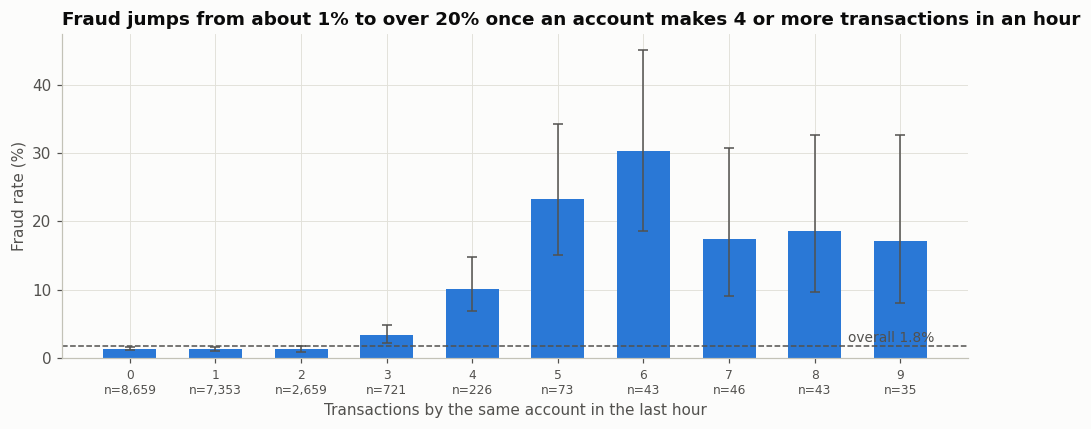

tx1h,0.0,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0
n,8659.000,7353.000,2659.000,721.000,226.000,73.000,43.000,46.000,43.000,35.000
frauds,119.000,96.000,35.000,24.000,23.000,17.000,13.000,8.000,8.000,6.000
rate,0.014,0.013,0.013,0.033,0.102,0.233,0.302,0.174,0.186,0.171


In [5]:
%%analysis
t = rate_by(train.assign(tx1h=train.transactions_last_1h.clip(upper=9)), 'tx1h')
fig, ax = plt.subplots(figsize=(9, 4))
x = t.index.astype(int)
ax.bar(x, t.rate * 100, color=BLUE, width=0.62)
ax.errorbar(x, t.rate * 100, yerr=[(t.rate - t.lo) * 100, (t.hi - t.rate) * 100], fmt='none', ecolor=INK2, elinewidth=1, capsize=3)
base_line(ax)
ax.text(9.4, BASE_RATE * 100 + 0.6, 'overall 1.8%', color=INK2, ha='right', fontsize=9)
ax.set_xticks(x, [f'{i}\nn={n:,}' for i, n in zip(x, t.n)], fontsize=8)
ax.set_xlabel('Transactions by the same account in the last hour')
ax.set_ylabel('Fraud rate (%)')
ax.set_title('Fraud jumps from about 1% to over 20% once an account makes 4 or more transactions in an hour')
plt.tight_layout(); plt.show()
display(t[['n', 'frauds', 'rate']].T.round(3))

**Key Findings.** With 0 to 2 transactions in the past hour, the fraud rate sits near 1.3%. At 3 it more than doubles, at 4 it is about 10%, and at 5 to 6 it reaches 23% to 30%. Beyond 6 it falls back to about 17% to 19%, although those groups are small (n under 50), so the intervals are wide.

**Why it matters.** This is the classic "card testing" or "account takeover burst" pattern: a fraudster who gains access makes many rapid transactions before being stopped. The curve is **not a straight line** (flat, then a cliff, then a slight drop). A linear model given the raw count would mis-fit it, so in Section 4 we let the model treat 0 to 2, 3, 4, 5, 6 and 7+ as separate bands.

### 2b. New accounts are riskier

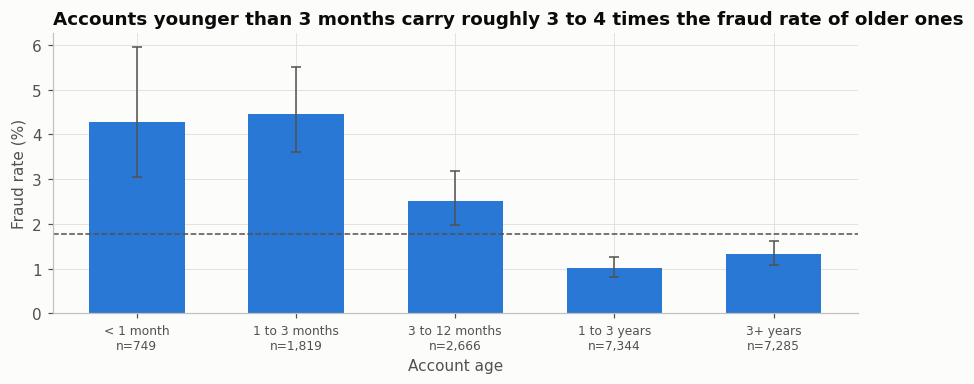

_age_band,< 1 month,1 to 3 months,3 to 12 months,1 to 3 years,3+ years
n,749.000,1819.000,2666.000,7344.00,7285.000
frauds,32.000,81.000,67.000,74.00,96.000
rate,0.043,0.045,0.025,0.01,0.013


In [6]:
%%analysis
age_bins = [-1, 30, 90, 365, 1095, np.inf]
age_labels = ['< 1 month', '1 to 3 months', '3 to 12 months', '1 to 3 years', '3+ years']
train['_age_band'] = pd.cut(train.account_age, age_bins, labels=age_labels)
t = rate_by(train, '_age_band')
fig, ax = plt.subplots(figsize=(8, 3.6))
xs = np.arange(len(t))
ax.bar(xs, t.rate * 100, color=BLUE, width=0.6)
ax.errorbar(xs, t.rate * 100, yerr=[(t.rate - t.lo) * 100, (t.hi - t.rate) * 100], fmt='none', ecolor=INK2, elinewidth=1, capsize=3)
base_line(ax)
ax.set_xticks(xs, [f'{l}\nn={n:,}' for l, n in zip(t.index, t.n)], fontsize=8)
ax.set_ylabel('Fraud rate (%)'); ax.set_xlabel('Account age')
ax.set_title('Accounts younger than 3 months carry roughly 3 to 4 times the fraud rate of older ones')
plt.tight_layout(); plt.show()
display(t[['n', 'frauds', 'rate']].T.round(3))

**Key Findings.** Accounts under one month old and one to three months old defraud at about 4% to 5%, against roughly 1% to 1.5% for accounts older than a year. Fraudsters open fresh ("mule") accounts or use newly compromised ones, and a long account history is evidence of a real customer.

### 2c. "Large" versus "large for this customer"
The team's feature list asked whether *relative* amount (this transaction against the account's recent average) is more useful than the raw amount. We compare both on the same scale: split each into ten equal-sized groups (deciles) and plot the fraud rate per group.

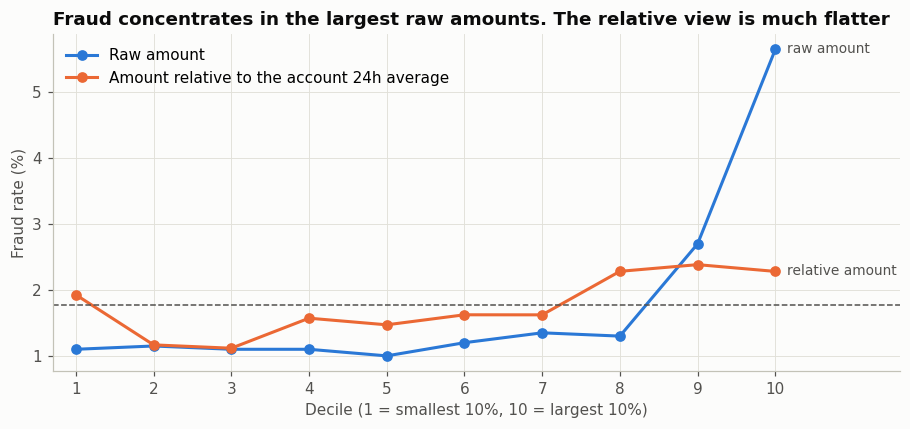

Single-feature PR-AUC   raw amount: 0.0381 | relative amount: 0.0205


In [7]:
%%analysis
avg_24h = train.spend_last_24h / (train.transactions_last_24h + 1)
rel_amt = np.log1p(train.transaction_amount) - np.log1p(avg_24h)
dec = pd.DataFrame({'fraud': train.fraud,
                    'abs': pd.qcut(train.transaction_amount.rank(method='first'), 10, labels=range(1, 11)),
                    'rel': pd.qcut(rel_amt.rank(method='first'), 10, labels=range(1, 11))})
dec.loc[rel_amt.isna(), 'rel'] = np.nan
ra, rr = rate_by(dec, 'abs'), rate_by(dec, 'rel')
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.plot(ra.index.astype(int), ra.rate * 100, color=BLUE, lw=2, marker='o', ms=6, label='Raw amount')
ax.plot(rr.index.astype(int), rr.rate * 100, color=ORANGE, lw=2, marker='o', ms=6, label='Amount relative to the account 24h average')
base_line(ax)
ax.text(10.15, ra.rate.iloc[-1] * 100, 'raw amount', color=INK2, va='center', fontsize=9)
ax.text(10.15, rr.rate.iloc[-1] * 100, 'relative amount', color=INK2, va='center', fontsize=9)
ax.set_xticks(range(1, 11)); ax.set_xlim(0.7, 11.6)
ax.set_xlabel('Decile (1 = smallest 10%, 10 = largest 10%)'); ax.set_ylabel('Fraud rate (%)')
ax.legend(loc='upper left')
ax.set_title('Fraud concentrates in the largest raw amounts. The relative view is much flatter')
plt.tight_layout(); plt.show()
print('Single-feature PR-AUC   raw amount: %.4f | relative amount: %.4f' % (
    average_precision_score(y, train.transaction_amount), average_precision_score(y, rel_amt.fillna(rel_amt.median()))))

**Key Findings.**
* **Raw amount wins clearly.** Its fraud rate stays near 1% for the first eight deciles, then jumps to 2.7% and **5.6%** in the top two. The relative amount never rises above about 2.4%, and its single-feature PR-AUC is about half that of raw amount (0.021 against 0.038).
* The relative view is not useless: its top three deciles sit above the overall rate. It is simply much weaker than we expected. Section 4.2 investigates why, and finds a better way to put amount in context (relative to account **age** rather than to today's spending).

**Note on the team's feature ideas #2 and #4.** `spend_last_24h / (transactions_last_24h + 1)` appears in both ideas under two names (`avg_transaction_24h` and `spend_per_transaction_24h`), so they are the **same feature**. We keep one copy.

### 2d. New device combined with a young account

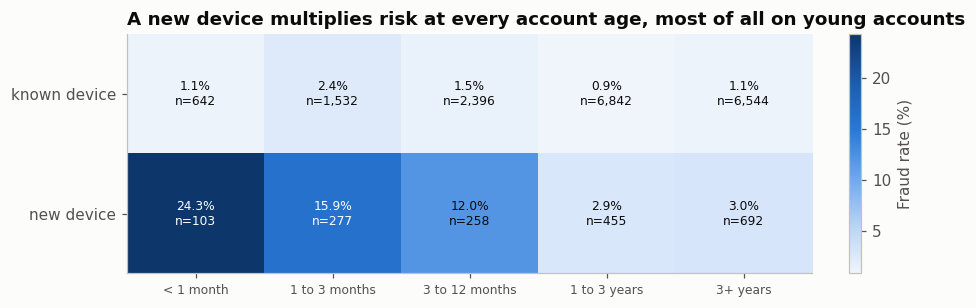

In [8]:
%%analysis
ct_n = pd.crosstab(train.new_device, train._age_band)
ct_k = pd.crosstab(train.new_device, train._age_band, values=train.fraud, aggfunc='sum')
ct_r = ct_k / ct_n
fig, ax = plt.subplots(figsize=(8.5, 2.9))
im = ax.imshow(ct_r.values * 100, cmap=BLUES, aspect='auto')
for i in range(ct_r.shape[0]):
    for j in range(ct_r.shape[1]):
        v = ct_r.values[i, j] * 100
        ax.text(j, i, f'{v:.1f}%\nn={ct_n.values[i, j]:,}', ha='center', va='center', fontsize=8,
                color='white' if v > 0.6 * np.nanmax(ct_r.values * 100) else INK)
ax.set_xticks(range(ct_r.shape[1]), ct_r.columns, fontsize=8)
ax.set_yticks([0, 1], ['known device', 'new device'])
ax.grid(False)
ax.set_title('A new device multiplies risk at every account age, most of all on young accounts')
plt.colorbar(im, ax=ax, label='Fraud rate (%)', fraction=0.025)
plt.tight_layout(); plt.show()

**Key Findings.** A new device raises the fraud rate in every age band, and the effect stacks with account age. A new device on an account under three months old is the riskiest cell. Overall, new-device transactions defraud at 7.5% against 1.2% on known devices, and 38% of all frauds come from a new device even though new devices are only 9% of traffic.

### 2e. Time of day and channel

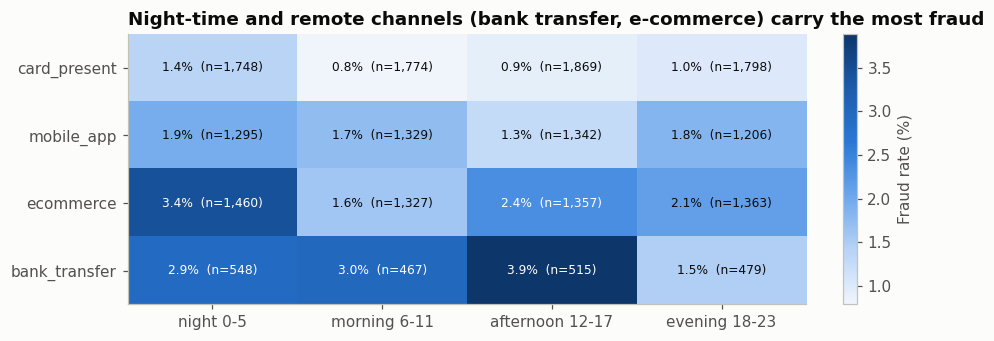

In [9]:
%%analysis
hb = pd.cut(train.transaction_hour, [-1, 5, 11, 17, 23], labels=['night 0-5', 'morning 6-11', 'afternoon 12-17', 'evening 18-23'])
ct_n = pd.crosstab(train.transaction_channel, hb)
ct_r = pd.crosstab(train.transaction_channel, hb, values=train.fraud, aggfunc='sum') / ct_n
ct_r = ct_r.loc[ct_r.mean(1).sort_values().index]; ct_n = ct_n.loc[ct_r.index]
fig, ax = plt.subplots(figsize=(8.5, 3.2))
im = ax.imshow(ct_r.values * 100, cmap=BLUES, aspect='auto')
for i in range(ct_r.shape[0]):
    for j in range(ct_r.shape[1]):
        v = ct_r.values[i, j] * 100
        ax.text(j, i, f'{v:.1f}%  (n={ct_n.values[i, j]:,})', ha='center', va='center', fontsize=8,
                color='white' if v > 0.6 * np.nanmax(ct_r.values * 100) else INK)
ax.set_xticks(range(4), ct_r.columns); ax.set_yticks(range(len(ct_r)), ct_r.index); ax.grid(False)
ax.set_title('Night-time and remote channels (bank transfer, e-commerce) carry the most fraud')
plt.colorbar(im, ax=ax, label='Fraud rate (%)', fraction=0.025)
plt.tight_layout(); plt.show()

**Key Findings.** Night hours (midnight to 5 am) have the highest fraud rate (2.3% against about 1.5% to 1.7% at other times). Card-present payments are the safest channel (1.0%), and bank transfers and e-commerce, where the card holder is not physically present, are the riskiest (2.4% to 2.8%). Because hour is cyclical (23:00 is next to 00:00), the model receives it as a sine and cosine pair rather than a number from 0 to 23.

### 2f. Merchant category and country: which differences are real?

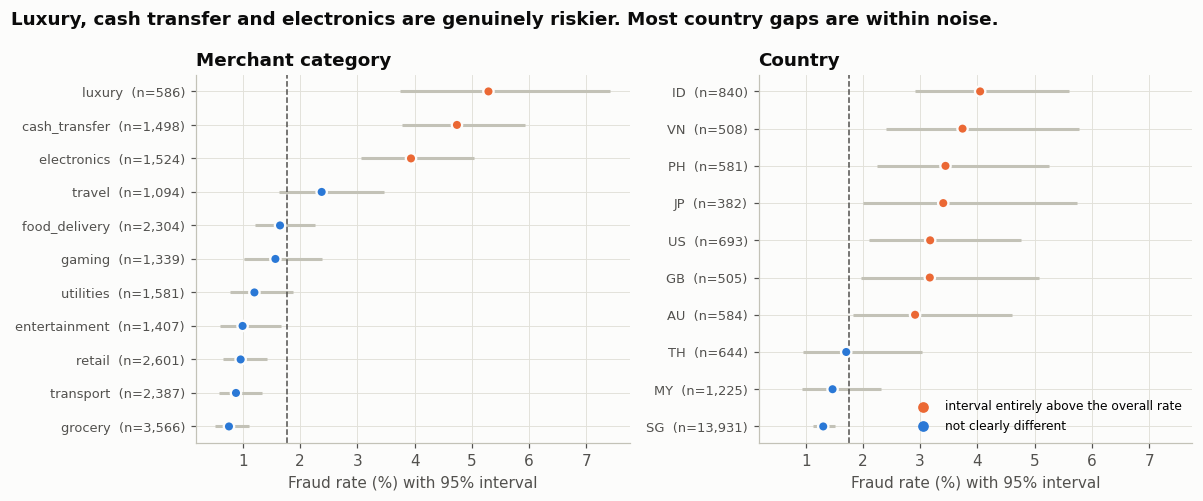

In [10]:
%%analysis
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharex=True)
for ax, col, title in [(axes[0], 'merchant_category', 'Merchant category'), (axes[1], 'country', 'Country')]:
    t = rate_by(train, col).sort_values('rate')
    sig = t.lo > BASE_RATE
    ys = np.arange(len(t))
    ax.hlines(ys, t.lo * 100, t.hi * 100, color=AXIS, lw=2)
    ax.scatter(t.rate * 100, ys, s=46, color=np.where(sig, ORANGE, BLUE), zorder=3, edgecolor=SURFACE, linewidth=1.5)
    ax.set_yticks(ys, [f'{i}  (n={n:,})' for i, n in zip(t.index, t.n)], fontsize=8.5)
    base_line(ax, horizontal=False)
    ax.set_title(title); ax.set_xlabel('Fraud rate (%) with 95% interval')
axes[1].scatter([], [], color=ORANGE, label='interval entirely above the overall rate')
axes[1].scatter([], [], color=BLUE, label='not clearly different')
axes[1].legend(loc='lower right', fontsize=8)
fig.suptitle('Luxury, cash transfer and electronics are genuinely riskier. Most country gaps are within noise.',
             x=0.01, ha='left', fontweight='bold', color=INK)
plt.tight_layout(); plt.show()

**Key Findings.** Luxury (5.3%), cash transfer (4.7%) and electronics (3.9%) have intervals well above the overall rate. These are categories where stolen value is easy to resell or move. Singapore, which is 70% of the data, sits slightly below average. Several foreign countries look two to three times riskier, but with only 400 to 800 rows each their intervals are wide. The model therefore receives every category as its own indicator, and regularisation (Section 6) stops it from over-trusting the small groups.

### 2g. Is the test set like the training set? (adversarial validation)
**What we did.** We trained a classifier to tell training rows from test rows. If the two files came from the same distribution, it could not do better than a coin flip (ROC-AUC 0.5).

**Why.** A model is only as good as its match to the data it will score. The organisers warned that the private test set "may contain different observations", so we need to know *how* the public test set differs and build a validation that reflects it.

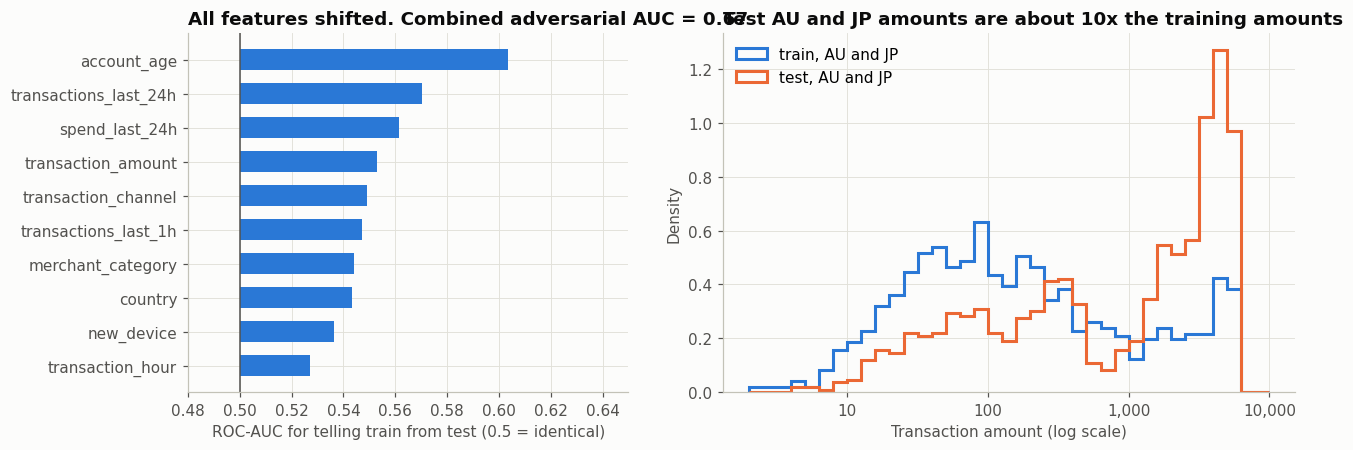

,train mean,test mean,train median,test median,train missing %,test missing %
transaction_amount,252.66,523.93,75.12,87.74,0.00,0.00
transaction_hour,11.45,11.68,11.00,12.00,0.00,0.00
transactions_last_24h,4.64,4.69,4.00,4.00,0.80,2.44
spend_last_24h,555.26,698.21,217.52,289.02,0.66,2.22
account_age,1053.65,1436.50,790.00,1158.00,0.68,2.20
new_device,0.09,0.15,0.00,0.00,0.62,2.44
transactions_last_1h,0.87,0.94,1.00,1.00,0.71,2.04


country,AU,GB,ID,JP,MY,PH,SG,TH,US,VN
train median amount,122.0,74.0,84.0,134.0,76.0,85.0,71.0,86.0,84.0,87.0
test median amount,1297.0,155.0,94.0,1609.0,164.0,172.0,70.0,147.0,120.0,158.0


Training rows that look like the new test cluster (amount > 1,000 and account older than 1,500 days): 466 rows, fraud rate 1.7%
Effective sample size of the shift weights: 9,548 of 20,000 rows (48%)


In [11]:
%%analysis
RAW_NUM = ['transaction_amount', 'transaction_hour', 'transactions_last_24h', 'spend_last_24h',
           'account_age', 'new_device', 'transactions_last_1h']
CAT_COLS = ['merchant_category', 'country', 'transaction_channel']

both = pd.concat([train.drop(columns=['fraud', '_age_band']), test], ignore_index=True)
is_test = np.r_[np.zeros(len(train)), np.ones(len(test))]
enc = both[RAW_NUM].copy()
for c in CAT_COLS:
    enc[c] = both[c].astype('category').cat.codes
adv_cv = StratifiedKFold(5, shuffle=True, random_state=0)
adv_model = HistGradientBoostingClassifier(max_iter=150, max_depth=3, random_state=0,
                                           categorical_features=[enc.columns.get_loc(c) for c in CAT_COLS])
p_test_like = cross_val_predict(adv_model, enc, is_test, cv=adv_cv, method='predict_proba')[:, 1]
adv_auc = roc_auc_score(is_test, p_test_like)
per_feature = {c: roc_auc_score(is_test, cross_val_predict(HistGradientBoostingClassifier(max_iter=100, random_state=0),
                                                           enc[[c]], is_test, cv=adv_cv, method='predict_proba')[:, 1])
               for c in RAW_NUM + CAT_COLS}
per_feature = pd.Series(per_feature).sort_values()

# Importance weights: how "test-like" each training row is. Used for the shift-weighted score from Section 3 on.
p_tr = p_test_like[:len(train)]
SHIFT_W = np.clip(p_tr / (1 - p_tr), 0.05, 20)
SHIFT_W = SHIFT_W / SHIFT_W.mean()
ess = SHIFT_W.sum()**2 / (SHIFT_W**2).sum()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={'width_ratios': [1, 1.3]})
ax = axes[0]
ax.barh(per_feature.index, per_feature.values - 0.5, left=0.5, color=BLUE, height=0.6)
ax.axvline(0.5, color=INK2, lw=1)
ax.set_xlim(0.48, max(0.65, per_feature.max() + 0.02)); ax.set_xlabel('ROC-AUC for telling train from test (0.5 = identical)')
ax.set_title(f'All features shifted. Combined adversarial AUC = {adv_auc:.2f}')
ax = axes[1]
bins = np.linspace(0.3, 4.0, 38)
aujp_tr = train.country.isin(['AU', 'JP']); aujp_te = test.country.isin(['AU', 'JP'])
for data, mask, color, label in [(train, aujp_tr, BLUE, 'train, AU and JP'), (test, aujp_te, ORANGE, 'test, AU and JP')]:
    ax.hist(np.log10(data.loc[mask, 'transaction_amount']), bins=bins, density=True, histtype='step', lw=2, color=color, label=label)
ax.set_xticks([1, 2, 3, 4], ['10', '100', '1,000', '10,000'])
ax.set_xlabel('Transaction amount (log scale)'); ax.set_ylabel('Density'); ax.legend()
ax.set_title('Test AU and JP amounts are about 10x the training amounts')
plt.tight_layout(); plt.show()

summ = pd.DataFrame({
    'train mean': train[RAW_NUM].mean(), 'test mean': test[RAW_NUM].mean(),
    'train median': train[RAW_NUM].median(), 'test median': test[RAW_NUM].median(),
    'train missing %': train[RAW_NUM].isna().mean() * 100, 'test missing %': test[RAW_NUM].isna().mean() * 100}).round(2)
display(summ)
med = pd.DataFrame({'train median amount': train.groupby('country').transaction_amount.median(),
                    'test median amount': test.groupby('country').transaction_amount.median()}).round(0).T
display(med)
big_old = (train.transaction_amount > 1000) & (train.account_age > 1500)
print(f'Training rows that look like the new test cluster (amount > 1,000 and account older than 1,500 days): '
      f'{big_old.sum()} rows, fraud rate {pct(train.fraud[big_old].mean())}')
print(f'Effective sample size of the shift weights: {ess:,.0f} of {len(train):,} rows ({pct(ess / len(train), 0)})')

**What we found. This is the most important finding in the analysis.**
* The adversarial AUC is about **0.67**, well above 0.5. The test file is **not** a random sample of the same population.
* **Amounts:** the test mean is about twice the training mean. In AU and JP, the median test transaction is about 10 times the training median (about 1,300 to 1,600 against 120 to 130). MY, PH, VN and GB roughly double.
* **Accounts are older** in test (median about 1,160 days against 790), and **new devices are more common** (15% against 9%).
* **Missing values are about 3 times as frequent** in test (about 2.3% per column against 0.7%).
* The large test transactions come from **old accounts, during the day, on known devices**. In training, rows like that (amount over 1,000 on an account older than 1,500 days) defraud at the normal base rate. In other words, they look like wealthy or business customers, not fraud.

**Why it matters for modelling.**
1. A model that has learned "big amount means fraud" too literally will flood the shifted test set with false alarms. We want models that weigh amount **against** account age, device and behaviour, and that behave smoothly outside the training range.
2. Ordinary cross-validation measures performance on *training-like* data only. So we also report a **shift-weighted PR-AUC**: each validation row is weighted by how test-like it is (the classifier's odds `p / (1 - p)`, clipped to between 0.05 and 20). This is standard importance weighting for covariate shift. It is a model-selection guide, not a promise of the private score.
3. Missing-value handling must not lean on "missing means safe", because missing values will be three times as common at test time.

## 3. Cleaning and missing values

**What we did.** Counted missing values in both files, checked whether missingness itself predicts fraud, and compared four ways of filling the gaps with the same cross-validation used everywhere else.

**The validation scheme used from here on.** 5-fold stratified cross-validation repeated 3 times (15 fits per model). Each fold keeps the 1.8% fraud rate. With only 353 frauds, a single split has about 70 frauds in validation, and its PR-AUC can swing by plus or minus 0.04. Repeating and averaging is what lets us tell real improvements from luck. All imputation, scaling and resampling are fitted **inside** each training fold, so no validation information leaks into training.

In [12]:
%%analysis
CV_SPLITS = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED).split(train, y))
RESULTS = {}

def cross_validate(make_model, name, data=None, verbose=True, store=True):
    # Fit make_model() on each training fold and score the validation fold.
    # Returns per-fold PR-AUC (plain and shift-weighted) and the out-of-fold prediction averaged over repeats.
    data = train if data is None else data
    ap_plain, ap_shift, fold_preds = [], [], []
    oof, cnt = np.zeros(len(y)), np.zeros(len(y))
    t0 = time.time()
    for tr_idx, va_idx in CV_SPLITS:
        model = make_model().fit(data.iloc[tr_idx], y[tr_idx])
        p = model.predict_proba(data.iloc[va_idx])[:, 1]
        ap_plain.append(average_precision_score(y[va_idx], p))
        ap_shift.append(average_precision_score(y[va_idx], p, sample_weight=SHIFT_W[va_idx]))
        fold_preds.append(p); oof[va_idx] += p; cnt[va_idx] += 1
    res = dict(ap=np.array(ap_plain), wap=np.array(ap_shift), preds=fold_preds, oof=oof / cnt)
    if store:
        RESULTS[name] = res
    if verbose:
        print(f'{name:42s} PR-AUC {res["ap"].mean():.4f} (sd {res["ap"].std():.4f}) | '
              f'shift-weighted {res["wap"].mean():.4f} | {time.time() - t0:.0f}s')
    return res

def summary_row(name, res):
    o = res['oof']
    return {'model': name, 'PR-AUC': res['ap'].mean(), 'PR-AUC sd': res['ap'].std(),
            'shift-weighted PR-AUC': res['wap'].mean(), 'ROC-AUC (OOF)': roc_auc_score(y, o),
            'Brier (OOF)': brier_score_loss(y, o), 'mean predicted p': o.mean()}

miss = pd.DataFrame({'train missing': train[RAW_NUM + CAT_COLS].isna().sum(),
                     'train %': train[RAW_NUM + CAT_COLS].isna().mean() * 100,
                     'test missing': test[RAW_NUM + CAT_COLS].isna().sum(),
                     'test %': test[RAW_NUM + CAT_COLS].isna().mean() * 100})
rows = []
for c in RAW_NUM + CAT_COLS:
    m = train[c].isna()
    lo, hi = wilson(train.fraud[m].sum(), m.sum())
    rows.append({'fraud rate when missing': train.fraud[m].mean(), '95% interval': f'{lo:.3f} to {hi:.3f}' if m.sum() else 'never missing',
                 'expected frauds if random': m.sum() * BASE_RATE, 'observed frauds': int(train.fraud[m].sum())})
miss = miss.join(pd.DataFrame(rows, index=RAW_NUM + CAT_COLS)).round(3)
display(miss)
print('Missing values per row (train):', train[RAW_NUM + CAT_COLS].isna().sum(1).value_counts().sort_index().to_dict())
print('Missing values per row (test): ', test[RAW_NUM + CAT_COLS].isna().sum(1).value_counts().sort_index().to_dict())

,train missing,train %,test missing,test %,fraud rate when missing,95% interval,expected frauds if random,observed frauds
transaction_amount,0,0.000,0,0.000,NaN,never missing,0.000,0
transaction_hour,0,0.000,0,0.000,NaN,never missing,0.000,0
transactions_last_24h,159,0.795,293,2.442,0.031,0.014 to 0.071,2.806,5
spend_last_24h,132,0.660,267,2.225,0.030,0.012 to 0.075,2.330,4
account_age,137,0.685,264,2.200,0.022,0.007 to 0.062,2.418,3
new_device,124,0.620,293,2.442,0.000,0.000 to 0.030,2.189,0
transactions_last_1h,142,0.710,245,2.042,0.028,0.011 to 0.070,2.506,4
merchant_category,113,0.565,259,2.158,0.000,0.000 to 0.033,1.994,0
country,107,0.535,268,2.233,0.009,0.002 to 0.051,1.889,1
transaction_channel,123,0.615,284,2.367,0.033,0.013 to 0.081,2.171,4


Missing values per row (train): {0: 19025, 1: 913, 2: 62}
Missing values per row (test):  {0: 10337, 1: 1198, 2: 421, 3: 43, 4: 1}


**Key Findings.**
* Every column except amount and hour has gaps, at 0.5% to 0.8% in training and about 2% to 2.4% in test. No row is missing more than two values.
* For every column, the 95% interval of the fraud rate among missing rows contains the overall rate of 1.8%. Missing merchant category (0 frauds in 113 rows) and missing new-device flag (0 in 124) *look* safe, but about 2 frauds would be expected by chance anyway, so this is not evidence.
* Conclusion: the values look **missing at random**. Gaps carry no fraud signal we can trust.

**Why we cannot simply drop rows.** Every test transaction must receive a score, so whatever we do must also work on incomplete rows at prediction time.

In [13]:
%%analysis
CAT_LEVELS_SIMPLE = {c: sorted(train[c].dropna().unique()) for c in CAT_COLS}

class SimpleImputeLR:
    # Small comparison model: log-transformed raw columns + one-hot categoricals + logistic regression,
    # with a configurable missing-value strategy.
    def __init__(self, strategy):
        self.strategy = strategy
    def _frame(self, df):
        d = df[RAW_NUM + CAT_COLS].copy()
        for c in ['transaction_amount', 'spend_last_24h', 'account_age']:
            d[c] = np.log1p(d[c])
        return d
    def fit(self, df, yy):
        if self.strategy == 'iterative':
            num = make_pipeline(IterativeImputer(random_state=0, max_iter=10, add_indicator=True), StandardScaler())
        else:
            num = make_pipeline(SimpleImputer(strategy='median', add_indicator=(self.strategy != 'median')), StandardScaler())
        if self.strategy == 'median + flags + missing as own category':
            cat = make_pipeline(SimpleImputer(strategy='constant', fill_value='missing'), OneHotEncoder(handle_unknown='ignore'))
        else:
            cat = OneHotEncoder(categories=[CAT_LEVELS_SIMPLE[c] for c in CAT_COLS], handle_unknown='ignore')   # missing -> "unknown" (all zeros)
        self.m = make_pipeline(ColumnTransformer([('n', num, RAW_NUM), ('c', cat, CAT_COLS)]),
                               LogisticRegression(C=0.1, max_iter=5000)).fit(self._frame(df), yy)
        return self
    def predict_proba(self, df):
        return self.m.predict_proba(self._frame(df))

imp_rows = []
for s in ['median', 'median + flags', 'iterative', 'median + flags + missing as own category']:
    r = cross_validate(lambda s=s: SimpleImputeLR(s), f'impute: {s}', store=False)
    imp_rows.append({'strategy': s, 'PR-AUC': r['ap'].mean(), 'sd': r['ap'].std(), 'shift-weighted PR-AUC': r['wap'].mean()})
display(pd.DataFrame(imp_rows).round(4))

impute: median                             PR-AUC 0.2206 (sd 0.0352) | shift-weighted 0.3328 | 0s


impute: median + flags                     PR-AUC 0.2201 (sd 0.0366) | shift-weighted 0.3330 | 1s


impute: iterative                          PR-AUC 0.2204 (sd 0.0364) | shift-weighted 0.3347 | 2s


impute: median + flags + missing as own category PR-AUC 0.2202 (sd 0.0363) | shift-weighted 0.3335 | 0s


,strategy,PR-AUC,sd,shift-weighted PR-AUC
0,median,0.2206,0.0352,0.3328
1,median + flags,0.2201,0.0366,0.3330
2,iterative,0.2204,0.0364,0.3347
3,median + flags + missing as own category,0.2202,0.0363,0.3335


**Key Findings.** All four strategies land within about 0.005 PR-AUC of each other, far inside the fold-to-fold noise (sd about 0.04). The more elaborate iterative imputer buys nothing.

**Our decision (and why).**
* **Numeric gaps: median imputation plus a 0/1 "was missing" flag per column.** The median is robust to the long right tails of amount and spend. The flag lets the model learn a separate effect if missingness ever matters. Medians are learned from the training fold only.
* **Missing categories: treated as "unknown"** (all category indicators set to 0, so the row gets the average category effect), **not** as a category of its own. A "missing" category would learn "missing means safe" from 113 rows with 0 frauds, which is noise. Test rows have three times as many gaps, so that rule would quietly push many test transactions towards "safe".
* **Cleaning rules applied before any feature is computed** (inside the saved model, so the private test set gets the same treatment): text in numeric columns becomes missing, negative amounts and counts are set to 0, hour is wrapped into 0 to 23, `new_device` is forced to 0 or 1, category spelling is normalised (case and spaces), unseen categories become "unknown", and extreme values are capped at the 0.1% and 99.9% training percentiles so a single absurd value cannot dominate a score.

## 4. Feature engineering: a fraud-behaviour framework

**Purpose.** The raw columns describe one moment. Fraud, however, is a **behaviour**: a stolen card is used fast, for valuable goods, from an unfamiliar device, often at odd hours. Following standard fraud-detection practice (velocity checks, behavioural anomaly detection, know-your-customer and device trust, contextual risk rules), we organise our features into five dimensions. Each dimension answers one question a fraud analyst would ask.

| Dimension | Analyst's question | Features | Fraud pattern it targets |
|---|---|---|---|
| 1. Velocity | How fast is this account moving right now? | `tx1h_band`, `vel_mult`, `tx1h_share`, `burst` | card testing, draining an account in a burst |
| 2. Monetary deviation | Is the money out of character for this account? | `log_amount`, `log_spend24`, `amt_vs_avg24`, `amt_share`, `amt_vs_age`, `spend_intensity` | cash-out, "bust-out" (max out, then vanish) |
| 3. Identity and trust | How much do we know about who is behind it? | `log_age`, `young`, `new_device`, `nd_young`, `nd_old` | mule or synthetic accounts, account takeover |
| 4. Context and opportunity | Where, when and through which door? | `hour_sin`, `hour_cos`, `night`, `remote`, `liquid`, `foreign`, category indicators | card-not-present fraud, easily resold goods, off-hours |
| 5. Data quality | Is the record complete? | `*_na` flags | control dimension (Section 3) |

**How each feature is judged: three lenses.**
1. **Separation.** How well does the feature alone separate fraud? We report its single-feature PR-AUC and its **Information Value (IV)**, the credit-risk industry's standard screening statistic. IV splits the feature into ten bins and adds up, over the bins, (share of genuine minus share of fraud) times log(share of genuine / share of fraud). Rule of thumb:
   * below 0.02: not useful
   * 0.02 to 0.1: weak
   * 0.1 to 0.3: medium
   * 0.3 to 0.5: strong
   * above 0.5: very strong (worth checking for leakage)
2. **Stability.** Is the feature distributed the same way in train and test? We report a **shift AUC**: the adversarial AUC of that single feature (0.5 means identical). A predictive feature whose distribution moves is risky on the private test set.
3. **Contribution.** Does the feature improve the *full* model in paired cross-validation (Section 4.10)? A feature that is strong alone can add nothing once the others are present.

**Implementation.** Every feature is a fixed, stateless formula in `add_features` below (no target information, nothing learned from the data). So the exact same code runs inside the saved model on the private test set. Missing inputs give missing features, which the model imputes (Section 3).

In [14]:
# [Runs in both modes]
RAW_NUM = ['transaction_amount', 'transaction_hour', 'transactions_last_24h', 'spend_last_24h',
           'account_age', 'new_device', 'transactions_last_1h']
CAT_COLS = ['merchant_category', 'country', 'transaction_channel']
CAT_LEVELS = {
    'merchant_category': ['grocery', 'transport', 'retail', 'entertainment', 'utilities', 'gaming',
                          'food_delivery', 'travel', 'electronics', 'cash_transfer', 'luxury'],
    'country': ['SG', 'MY', 'TH', 'ID', 'VN', 'PH', 'JP', 'US', 'GB', 'AU'],
    'transaction_channel': ['card_present', 'mobile_app', 'ecommerce', 'bank_transfer'],
}
# Domain definitions (from payments practice, not from the fraud labels):
LIQUID_MERCHANTS = ['luxury', 'electronics', 'cash_transfer']        # value that is easy to resell or move
REMOTE_CHANNELS = ['ecommerce', 'mobile_app', 'bank_transfer']        # card-not-present: no chip, PIN or signature
HOME_COUNTRY = 'SG'                                                   # 70% of traffic
NA_COLS = ['transactions_last_24h', 'spend_last_24h', 'account_age', 'new_device', 'transactions_last_1h']
TX1H_EDGES = [-np.inf, 2, 3, 4, 5, 6, np.inf]
TX1H_LABELS = ['0-2', '3', '4', '5', '6', '7+']
# Positional column order used if someone passes a bare numpy array (the raw file order without id).
RAW_ORDER = ['transaction_amount', 'transaction_hour', 'merchant_category', 'country', 'transaction_channel',
             'transactions_last_24h', 'spend_last_24h', 'account_age', 'new_device', 'transactions_last_1h']

def to_frame(data):
    # Accept a DataFrame, a dict (one row or columns), a list of dicts, a Series or a numpy array.
    if isinstance(data, pd.DataFrame):
        df = data.copy()
    elif isinstance(data, pd.Series):
        df = data.to_frame().T
    elif isinstance(data, dict):
        df = pd.DataFrame([data]) if all(np.isscalar(v) or v is None for v in data.values()) else pd.DataFrame(data)
    elif isinstance(data, np.ndarray):
        arr = np.atleast_2d(data)
        cols = RAW_ORDER if arr.shape[1] == len(RAW_ORDER) else ['id'] + RAW_ORDER if arr.shape[1] == len(RAW_ORDER) + 1 else None
        if cols is None:
            raise ValueError(f'numpy input must have {len(RAW_ORDER)} columns in this order: {RAW_ORDER}')
        df = pd.DataFrame(arr, columns=cols)
    else:
        df = pd.DataFrame(data)
    df.columns = [str(c).strip().lower().replace(' ', '_') for c in df.columns]
    return df.reset_index(drop=True)

def clean_raw(data, bounds=None):
    # Cleaning rules from Section 3. Returns a frame with exactly the raw columns, in a fixed order.
    df = to_frame(data)
    out = pd.DataFrame(index=df.index)
    for c in RAW_NUM:
        out[c] = pd.to_numeric(df[c], errors='coerce') if c in df else np.nan
    out = out.astype(float).replace([np.inf, -np.inf], np.nan)
    for c in ['transaction_amount', 'transactions_last_24h', 'spend_last_24h', 'account_age', 'transactions_last_1h']:
        out[c] = out[c].clip(lower=0)
    out['transaction_hour'] = np.floor(out['transaction_hour'] % 24)
    out['new_device'] = out['new_device'].clip(0, 1).round()
    if bounds is not None:
        for c, (lo, hi) in bounds.items():
            out[c] = out[c].clip(lo, hi)
    # A last-hour count cannot exceed the last-24-hour count.
    out['transactions_last_24h'] = np.fmax(out['transactions_last_24h'], out['transactions_last_1h'])
    for c in CAT_COLS:
        s = df[c] if c in df else pd.Series(np.nan, index=df.index)
        s = s.astype('string').str.strip()
        s = s.str.upper() if c == 'country' else s.str.lower().str.replace(' ', '_')
        allowed = set(CAT_LEVELS[c])
        out[c] = [v if v in allowed else np.nan for v in s.to_numpy(dtype=object, na_value=None)]   # unseen or missing -> NaN ("unknown")
    return out

def add_features(raw):
    # Stateless engineered features (raw columns are kept). NaN stays NaN and is imputed inside the model.
    d = raw.copy()
    known = lambda s: s.notna()
    # Dimension 1: velocity
    d['vel_mult'] = np.log1p(d.transactions_last_1h / (d.transactions_last_24h / 24 + 0.1))
    d['tx1h_share'] = d.transactions_last_1h / (d.transactions_last_24h + 1)
    d['burst'] = (d.transactions_last_1h >= 4).astype(float).where(known(d.transactions_last_1h))
    d['tx1h_band'] = pd.cut(d.transactions_last_1h, TX1H_EDGES, labels=TX1H_LABELS).astype(object)
    # Dimension 2: monetary deviation
    d['log_amount'] = np.log1p(d.transaction_amount)
    d['log_spend24'] = np.log1p(d.spend_last_24h)
    d['log_tx24'] = np.log1p(d.transactions_last_24h)
    avg24 = d.spend_last_24h / (d.transactions_last_24h + 1)
    d['amt_vs_avg24'] = d.log_amount - np.log1p(avg24)
    d['amt_share'] = d.transaction_amount / (d.spend_last_24h + d.transaction_amount + 1)
    d['amt_vs_age'] = d.log_amount - np.log1p(d.account_age)
    d['spend_intensity'] = d.log_spend24 - np.log1p(d.account_age)
    # Dimension 3: identity and trust
    d['log_age'] = np.log1p(d.account_age)
    d['young'] = (d.account_age < 90).astype(float).where(known(d.account_age))
    d['nd_young'] = d.new_device * d.young
    d['nd_old'] = d.new_device * (d.account_age > 365).astype(float).where(known(d.account_age))
    # Dimension 4: context and opportunity
    d['hour_sin'] = np.sin(2 * np.pi * d.transaction_hour / 24)
    d['hour_cos'] = np.cos(2 * np.pi * d.transaction_hour / 24)
    d['night'] = (d.transaction_hour <= 5).astype(float).where(known(d.transaction_hour))
    d['remote'] = d.transaction_channel.isin(REMOTE_CHANNELS).astype(float).where(known(d.transaction_channel))
    d['liquid'] = d.merchant_category.isin(LIQUID_MERCHANTS).astype(float).where(known(d.merchant_category))
    d['foreign'] = (d.country != HOME_COUNTRY).astype(float).where(known(d.country))
    # Dimension 5: data quality
    for c in NA_COLS:
        d[c + '_na'] = raw[c].isna().astype(float)
    # Combined: count of classic red flags (each 0/1, unknown counts as 0)
    d['red_flags'] = (d.burst.fillna(0) + d.young.fillna(0) + d.new_device.fillna(0) + d.night.fillna(0) + d.remote.fillna(0)
                      + d.liquid.fillna(0) + d.foreign.fillna(0) + (d.amt_vs_avg24 > 1).astype(float))
    return d

# Core groups always offered to the model, and candidate groups that must prove themselves (Section 4.10).
FEATURE_GROUPS = {
    'base': ['log_amount', 'log_spend24', 'log_age', 'transactions_last_24h', 'transactions_last_1h', 'new_device', 'hour_sin', 'hour_cos'],
    'ratio_avg': ['amt_vs_avg24'],
    'ratio_share': ['amt_share'],
    'velocity': ['vel_mult', 'tx1h_share'],
    'flags': ['burst', 'night', 'young', 'nd_young'],
    'missing': [c + '_na' for c in NA_COLS],
    'logtx': ['log_tx24'],
}
CANDIDATE_GROUPS = {
    'tenure': ['amt_vs_age', 'spend_intensity'],
    'domain_flags': ['remote', 'liquid', 'foreign'],
    'red_flag_count': ['red_flags'],
    'takeover': ['nd_old'],
}

In [15]:
%%analysis
feats_train = add_features(clean_raw(train))
feats_test = add_features(clean_raw(test))
print('engineered frame:', feats_train.shape)
display(feats_train.drop(columns=RAW_NUM + CAT_COLS).head(3).round(3))

engineered frame: (20000, 37)


,vel_mult,tx1h_share,burst,tx1h_band,log_amount,log_spend24,log_tx24,amt_vs_avg24,amt_share,amt_vs_age,...,night,remote,liquid,foreign,transactions_last_24h_na,spend_last_24h_na,account_age_na,new_device_na,transactions_last_1h_na,red_flags
0,1.626,0.179,1.0,5,4.026,7.491,3.332,-0.148,0.030,-3.058,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0
1,0.000,0.000,0.0,0-2,3.080,5.389,1.386,-0.937,0.087,-4.951,...,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0
2,0.000,0.000,0.0,0-2,3.114,4.154,1.386,0.300,0.252,-3.780,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [16]:
%%analysis
# Helpers used throughout Section 4.
def information_value(x, yy=y, bins=10):
    s = pd.Series(np.asarray(x, float))
    g = pd.qcut(s.rank(method='first'), bins, labels=False) if s.nunique() > bins else s
    t = pd.DataFrame({'g': g, 'y': yy}).dropna().groupby('g')['y'].agg(['sum', 'size'])
    bad = (t['sum'] + 0.5) / (t['sum'].sum() + 0.5)
    good = (t['size'] - t['sum'] + 0.5) / ((t['size'] - t['sum']).sum() + 0.5)
    return float(((good - bad) * np.log(good / bad)).sum())

def iv_strength(v):
    return 'not useful' if v < 0.02 else 'weak' if v < 0.1 else 'medium' if v < 0.3 else 'strong' if v < 0.5 else 'very strong'

_shift_cache = {}
def shift_auc(col):
    if col not in _shift_cache:
        v = np.r_[feats_train[col].to_numpy(float), feats_test[col].to_numpy(float)].reshape(-1, 1)
        p = cross_val_predict(HistGradientBoostingClassifier(max_iter=80, random_state=0), v, is_test, cv=adv_cv, method='predict_proba')[:, 1]
        _shift_cache[col] = roc_auc_score(is_test, p)
    return _shift_cache[col]

def feature_card(cols):
    rows = []
    for c in cols:
        s = feats_train[c].astype(float); f = s.fillna(s.median())
        iv = information_value(s)
        rows.append({'feature': c, 'mean (genuine)': s[y == 0].mean(), 'mean (fraud)': s[y == 1].mean(),
                     'PR-AUC alone': max(average_precision_score(y, f), average_precision_score(y, -f)),
                     'IV': iv, 'IV strength': iv_strength(iv), 'shift AUC': shift_auc(c)})
    return pd.DataFrame(rows).set_index('feature').round(3)

def rate_by_quantile(values, q=10):
    s = pd.Series(np.asarray(values, float))
    g = pd.qcut(s.rank(method='first'), q, labels=False)
    t = pd.DataFrame({'x': s, 'g': g, 'y': y}).dropna().groupby('g').agg(x=('x', 'median'), k=('y', 'sum'), n=('y', 'size'))
    t['rate'] = t.k / t.n
    t['lo'], t['hi'] = wilson(t.k, t.n)
    return t

def plot_rate_line(ax, t, color, label, xs=None):
    xs = (t.index + 1) if xs is None else xs
    ax.fill_between(xs, t.lo * 100, t.hi * 100, color=color, alpha=0.12, lw=0)
    ax.plot(xs, t.rate * 100, color=color, lw=2, marker='o', ms=5, label=label)

def rate_heatmap(ax, rows, cols, title, row_name, col_name):
    n = pd.crosstab(rows, cols); k = pd.crosstab(rows, cols, values=train.fraud, aggfunc='sum'); r = (k / n) * 100
    im = ax.imshow(r.values, cmap=BLUES, aspect='auto', origin='lower')
    for i in range(r.shape[0]):
        for j in range(r.shape[1]):
            v = r.values[i, j]
            if not np.isnan(v):
                ax.text(j, i, f'{v:.1f}%\nn={n.values[i, j]:,}', ha='center', va='center', fontsize=7.5,
                        color='white' if v > 0.6 * np.nanmax(r.values) else INK)
    ax.set_xticks(range(r.shape[1]), [str(c) for c in r.columns], fontsize=8)
    ax.set_yticks(range(r.shape[0]), [str(i) for i in r.index], fontsize=8)
    ax.set_xlabel(col_name); ax.set_ylabel(row_name); ax.grid(False); ax.set_title(title, fontsize=10)
    return im

### 4.1 Dimension 1: Velocity (how fast is the account moving?)

**Purpose.** Once a fraudster controls a card or account, the window before it is blocked is short, so they move fast. There are two common forms: **card testing** (many small charges to find out which stolen cards work) and **draining** (many charges in quick succession). Velocity rules ("more than N transactions in M minutes") are among the oldest and most widely used fraud controls in card payments.

| Feature | Formula | Plain meaning |
|---|---|---|
| `tx1h_band` | last-hour count grouped as 0-2, 3, 4, 5, 6, 7+ | lets the model learn the cliff at 3 to 4 transactions seen in Section 2a |
| `vel_mult` | log(1 + tx_1h / (tx_24h / 24 + 0.1)) | how many times faster than the account's own hourly average today (team idea #3). The 0.1 avoids dividing by zero |
| `tx1h_share` | tx_1h / (tx_24h + 1) | the share of today's activity squeezed into the last hour |
| `burst` | 1 if tx_1h is 4 or more | the hard rule a bank would write by hand |

#### (a) Acceleration, and bursts on quiet versus busy accounts

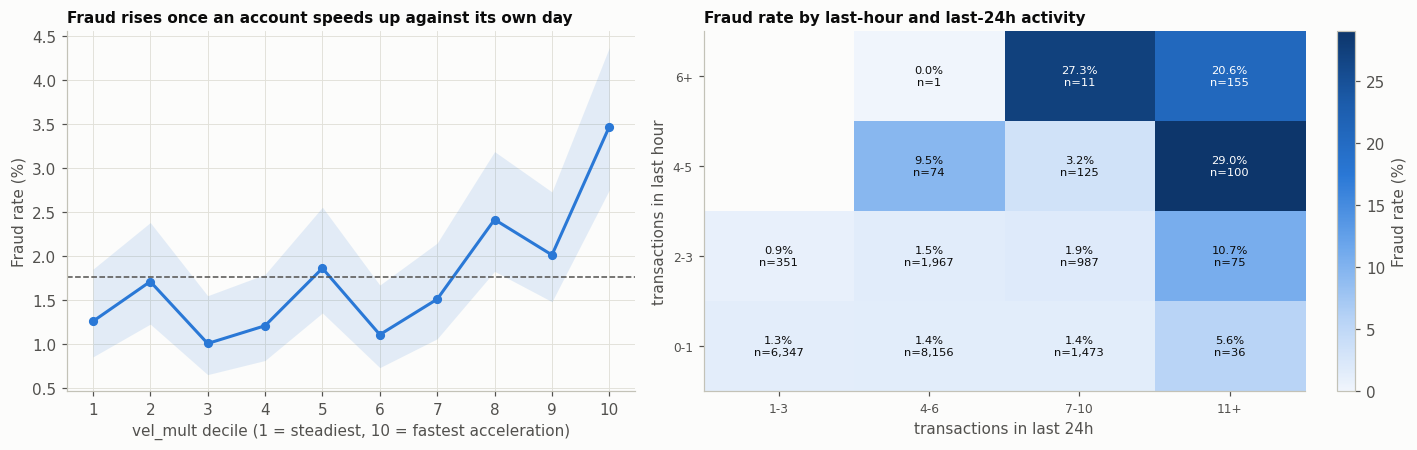

g,0.0,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0
median vel_mult,0.000,0.000,0.00,0.000,1.196,1.445,1.558,1.695,1.904,2.183
n,1986.000,1986.000,1986.00,1985.000,1986.000,1986.000,1985.000,1986.000,1986.000,1986.000
frauds,25.000,34.000,20.00,24.000,37.000,22.000,30.000,48.000,40.000,69.000
rate,0.013,0.017,0.01,0.012,0.019,0.011,0.015,0.024,0.020,0.035


In [17]:
%%analysis
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={'width_ratios': [1, 1.15]})
t = rate_by_quantile(feats_train.vel_mult, q=10)
ax = axes[0]
plot_rate_line(ax, t, BLUE, 'fraud rate')
base_line(ax)
ax.set_xticks(range(1, 11)); ax.set_xlabel('vel_mult decile (1 = steadiest, 10 = fastest acceleration)'); ax.set_ylabel('Fraud rate (%)')
ax.set_title('Fraud rises once an account speeds up against its own day', fontsize=10)
tx24_band = pd.cut(feats_train.transactions_last_24h, [-1, 3, 6, 10, np.inf], labels=['1-3', '4-6', '7-10', '11+'])
tx1h_band = pd.cut(feats_train.transactions_last_1h, [-1, 1, 3, 5, np.inf], labels=['0-1', '2-3', '4-5', '6+'])
im = rate_heatmap(axes[1], tx1h_band, tx24_band, 'Fraud rate by last-hour and last-24h activity', 'transactions in last hour', 'transactions in last 24h')
plt.colorbar(im, ax=axes[1], fraction=0.03, label='Fraud rate (%)')
plt.tight_layout(); plt.show()
display(t[['x', 'n', 'k', 'rate']].rename(columns={'x': 'median vel_mult', 'k': 'frauds'}).T.round(3))

**Key Findings**
* Acceleration on its own is a **weak** signal. Deciles 1 to 7 of `vel_mult` all sit between 1.0% and 1.9%, inside each other's intervals, and only the top deciles rise (2.4%, 2.0% and 3.5%).
* The heatmap shows where velocity really bites: **bursts on accounts that are busy all day**.
  * 4 to 5 transactions in the last hour on an account with 11+ transactions today defraud at **29.0%** (n = 100).
  * 6+ in the last hour with 11+ today: **20.6%** (n = 155).
  * The same 4 to 5 burst on an account with 7 to 10 daily transactions: only **3.2%** (n = 125).
* So the fraud pattern is an account being worked hard for the whole day, not a single quick spike. This explains why the ratio features below are weaker than the raw counts.

#### (b) Velocity scorecard

In [18]:
%%analysis
display(feature_card(['transactions_last_1h', 'vel_mult', 'tx1h_share', 'burst']))

,mean (genuine),mean (fraud),PR-AUC alone,IV,IV strength,shift AUC
feature,,,,,,
transactions_last_1h,0.855,1.911,0.061,0.601,very strong,0.547
vel_mult,0.962,1.215,0.030,0.148,medium,0.564
tx1h_share,0.145,0.192,0.024,0.106,medium,0.539
burst,0.020,0.215,0.048,0.509,very strong,0.516


**Key Findings**
* The raw last-hour count is the strongest velocity feature (**IV 0.60, very strong**). The hand-written `burst` rule reaches IV 0.51 with the lowest shift AUC in the group (0.516), so a simple rule is both strong and stable.
* `vel_mult` and `tx1h_share` are only **medium** (IV 0.15 and 0.11). Dividing by the account's own day *dilutes* the signal, because, as the heatmap shows, the busy accounts are the risky ones.
* All velocity features are stable between train and test (shift AUC 0.52 to 0.56).

### 4.2 Dimension 2: Monetary deviation (is the money out of character?)

**Purpose.** A fraudster wants as much value as possible before detection. That shows up as amounts that are large **in absolute terms** (cash-out) and large **for this particular account**. A payment of 500 is routine for one customer and alarming for another. A related pattern is the **bust-out**: a recently opened account that suddenly spends heavily, then disappears. So we measure money against three yardsticks: the transaction itself, the account's own day, and the account's age.

| Feature | Formula | Plain meaning |
|---|---|---|
| `log_amount` | log(1 + amount) | size of the payment (log tames the long tail up to 9,000) |
| `log_spend24` | log(1 + spend_24h) | total money moved today |
| `amt_vs_avg24` | log(1 + amount) - log(1 + spend_24h / (tx_24h + 1)) | is this payment bigger than the account's typical payment today? (team ideas #2 and #4, which are the same formula) |
| `amt_share` | amount / (spend_24h + amount + 1) | how much of the day's money sits in this one payment |
| `amt_vs_age` | log(1 + amount) - log(1 + account_age) | "too much, too soon": a large payment on a young account |
| `spend_intensity` | log(1 + spend_24h) - log(1 + account_age) | how much the account spends per unit of history (bust-out signature) |

#### (a) Absolute size versus relative size

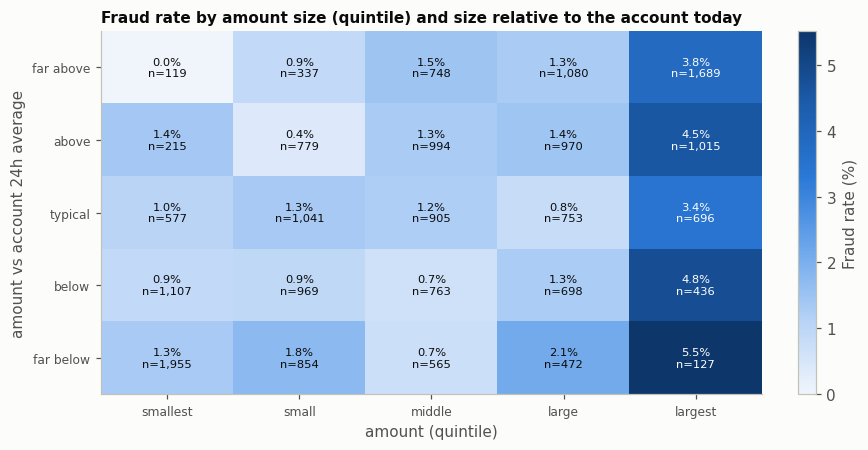

In [19]:
%%analysis
fig, ax = plt.subplots(figsize=(8, 4.2))
q_abs = pd.qcut(feats_train.log_amount.rank(method='first'), 5, labels=['smallest', 'small', 'middle', 'large', 'largest'])
q_rel = pd.qcut(feats_train.amt_vs_avg24.rank(method='first'), 5, labels=['far below', 'below', 'typical', 'above', 'far above'])
im = rate_heatmap(ax, q_rel, q_abs, 'Fraud rate by amount size (quintile) and size relative to the account today',
                  'amount vs account 24h average', 'amount (quintile)')
plt.colorbar(im, ax=ax, fraction=0.03, label='Fraud rate (%)')
plt.tight_layout(); plt.show()

**Key Findings**
* **Absolute size dominates.** In the largest-amount quintile the fraud rate is 3.4% to 5.5% in every row. In the other four quintiles it stays between 0.4% and 2.1%.
* Within a column, being far above the account's average does **not** raise risk consistently. Large payments are risky whether or not they are typical for the account today.
* This **overturns our starting hypothesis.** The team rated "amount relative to the recent average" (idea #2) as the best feature to build, but the data says it is weak (IV 0.07, Section 4.2(d)). A plausible reason: `spend_last_24h` already contains the fraudster's own spending that day, so during an attack the "normal" baseline is itself inflated.

#### (b) Tenure-normalised money: "too much, too soon"

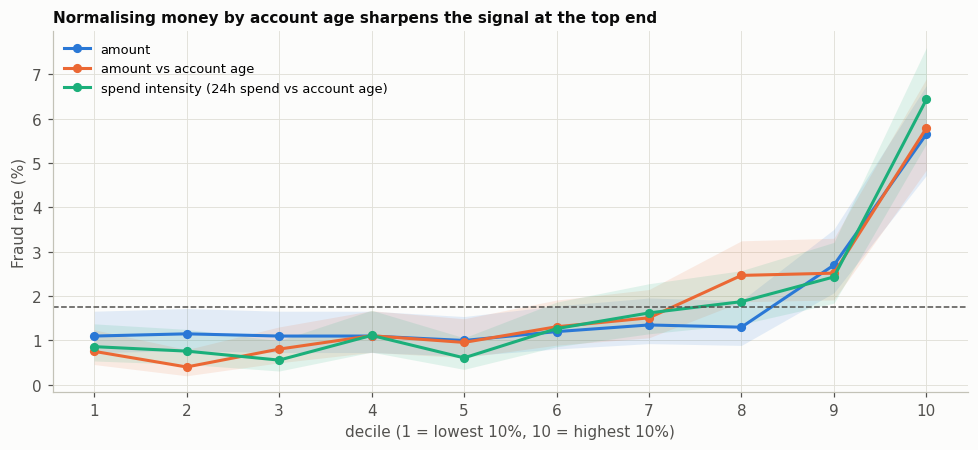

In [20]:
%%analysis
fig, ax = plt.subplots(figsize=(9, 4.2))
for col, color, label in [('log_amount', BLUE, 'amount'), ('amt_vs_age', ORANGE, 'amount vs account age'),
                          ('spend_intensity', AQUA, 'spend intensity (24h spend vs account age)')]:
    t = rate_by_quantile(feats_train[col], q=10)
    plot_rate_line(ax, t, color, label)
base_line(ax)
ax.set_xticks(range(1, 11))
ax.set_xlabel('decile (1 = lowest 10%, 10 = highest 10%)'); ax.set_ylabel('Fraud rate (%)'); ax.legend(loc='upper left', fontsize=8.5)
ax.set_title('Normalising money by account age sharpens the signal at the top end', fontsize=10)
plt.tight_layout(); plt.show()

**Key Findings**
* All three curves are flat up to about the 7th decile, then climb steeply. The top decile reaches 5.6% (amount), 5.8% (amount vs age) and **6.4% (spend intensity)**, about 3.6 times the overall rate.
* The tenure-normalised features also separate better at the **safe** end. The lowest three deciles of amount vs age and of spend intensity fall to 0.4% to 0.9%: established accounts spending modestly are the safest group of all. Raw amount never drops below about 1.0%.

#### (c) Which money features survive the train-to-test shift?

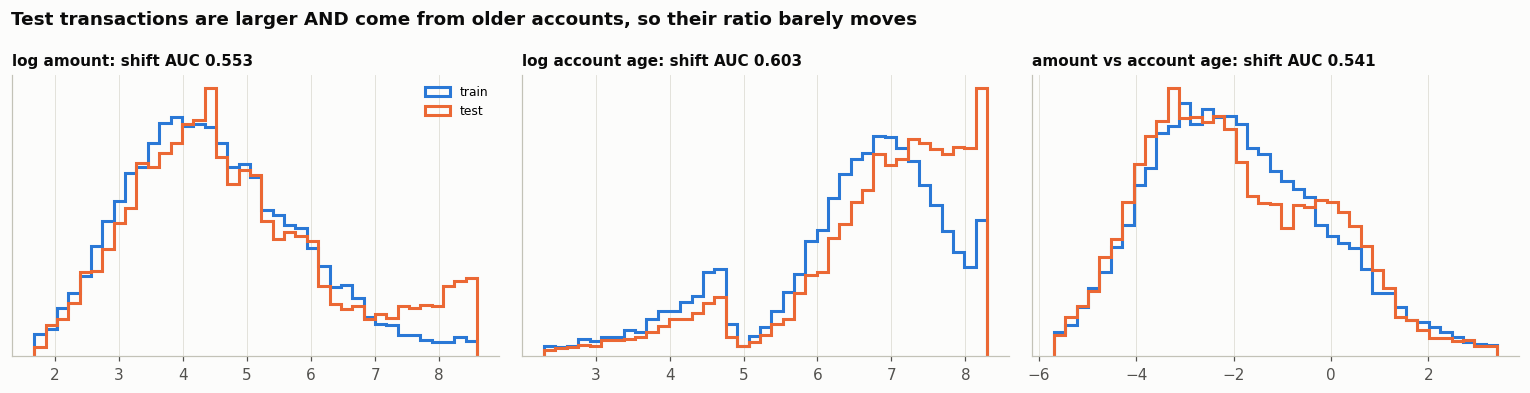

In [21]:
%%analysis
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=False)
for ax, col, title in zip(axes, ['log_amount', 'log_age', 'amt_vs_age'], ['log amount', 'log account age', 'amount vs account age']):
    lo_, hi_ = np.nanpercentile(np.r_[feats_train[col], feats_test[col]], [0.5, 99.5])
    b = np.linspace(lo_, hi_, 40)
    ax.hist(feats_train[col].dropna(), bins=b, density=True, histtype='step', lw=2, color=BLUE, label='train')
    ax.hist(feats_test[col].dropna(), bins=b, density=True, histtype='step', lw=2, color=ORANGE, label='test')
    ax.set_title(f'{title}: shift AUC {shift_auc(col):.3f}', fontsize=10); ax.set_yticks([])
axes[0].legend(fontsize=8)
fig.suptitle('Test transactions are larger AND come from older accounts, so their ratio barely moves',
             x=0.01, ha='left', fontweight='bold', color=INK)
plt.tight_layout(); plt.show()

**Key Findings**
* Raw account age is the most shifted feature in the dataset (shift AUC 0.603), because test accounts are older. Raw amount also shifts (0.554), with a visible bulge of very large test payments on the right.
* **Amount vs account age barely moves (0.541).** In test, the big payments come from old accounts, so the two shifts cancel and the ratio stays in its usual range.
* Practical meaning: a model that judges amount *in the context of tenure* is less likely to panic on the shifted test set than one that reacts to raw amount alone.

#### (d) Monetary scorecard

In [22]:
%%analysis
display(feature_card(['log_amount', 'log_spend24', 'amt_vs_avg24', 'amt_share', 'amt_vs_age', 'spend_intensity']))

,mean (genuine),mean (fraud),PR-AUC alone,IV,IV strength,shift AUC
feature,,,,,,
log_amount,4.450,5.276,0.038,0.410,strong,0.553
log_spend24,5.358,6.330,0.052,0.468,strong,0.562
amt_vs_avg24,0.676,0.808,0.021,0.067,weak,0.537
amt_share,0.314,0.308,0.031,0.060,weak,0.538
amt_vs_age,-1.930,-0.348,0.062,0.570,very strong,0.541
spend_intensity,-1.021,0.703,0.071,0.631,very strong,0.538


**Key Findings**
* `spend_intensity` (IV 0.63) and `amt_vs_age` (IV 0.57) are the strongest monetary features on their own, ahead of raw 24h spend (0.47) and raw amount (0.41), and they are more stable (shift AUC 0.54 against 0.55 to 0.56).
* `amt_vs_avg24` and `amt_share` are weak (IV about 0.06), consistent with (a). They are also 0.95 rank-correlated with each other (Section 4.6(c)).
* **A subtle but important point for Section 4.10:** `amt_vs_age` is exactly `log_amount - log_age`, and `spend_intensity` is exactly `log_spend24 - log_age`. All three ingredients are already in the core model, and a linear model can build any weighted difference of its inputs by itself. So these strong features may add *nothing new* to logistic regression, even though they are excellent for EDA and for tree models.

### 4.3 Dimension 3: Identity and trust (how much do we know about who is behind it?)

**Purpose.** Banks build trust in an account over time (know-your-customer checks, a history of normal behaviour) and in a device (device fingerprinting). Fraud tends to come through the gaps, in two classic forms:
* **Mule or synthetic accounts**: freshly opened accounts used to receive and move stolen money. Signature: a *young* account.
* **Account takeover**: a criminal steals the login of an established customer and uses it from their own phone. Signature: an *old* account on a *new* device.

The data lets us test which of the two dominates here.

| Feature | Formula | Plain meaning |
|---|---|---|
| `log_age` | log(1 + account_age) | account history, with diminishing returns (day 10 versus day 40 matters more than year 5 versus year 6) |
| `young` | 1 if account_age < 90 days | the "new account" window used by many banks |
| `new_device` | given | first time this device is seen |
| `nd_young` | new_device x young | mule signature |
| `nd_old` | new_device x (account_age > 365) | account-takeover signature (candidate feature, tested in 4.10) |

#### (a) Mule accounts or account takeover?

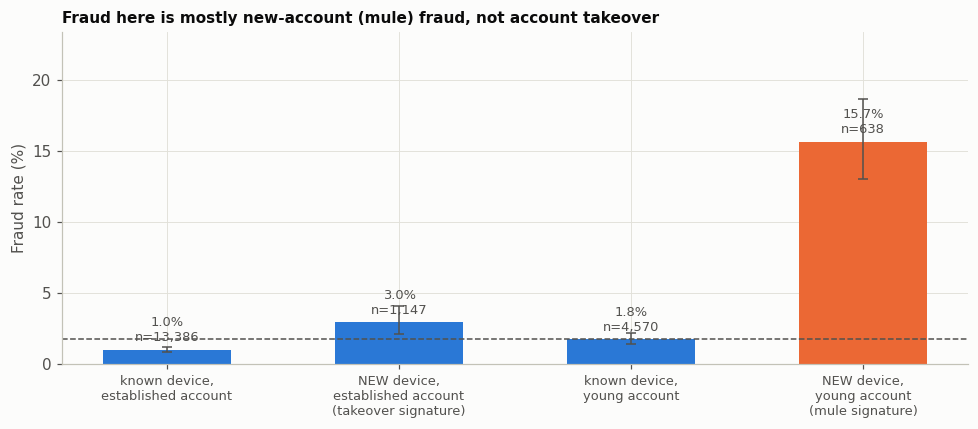

In [23]:
%%analysis
grp = np.select([(feats_train.new_device == 0) & (feats_train.account_age > 365), (feats_train.new_device == 1) & (feats_train.account_age > 365),
                 (feats_train.new_device == 0) & (feats_train.account_age <= 365), (feats_train.new_device == 1) & (feats_train.account_age <= 365)],
                ['known device,\nestablished account', 'NEW device,\nestablished account\n(takeover signature)',
                 'known device,\nyoung account', 'NEW device,\nyoung account\n(mule signature)'], default='unknown')
t = rate_by(train.assign(_g=grp), '_g').drop(index='unknown', errors='ignore')
t = t.loc[['known device,\nestablished account', 'NEW device,\nestablished account\n(takeover signature)',
           'known device,\nyoung account', 'NEW device,\nyoung account\n(mule signature)']]
fig, ax = plt.subplots(figsize=(9, 4))
xs = np.arange(len(t))
ax.bar(xs, t.rate * 100, color=[BLUE, BLUE, BLUE, ORANGE], width=0.55)
ax.errorbar(xs, t.rate * 100, yerr=[(t.rate - t.lo) * 100, (t.hi - t.rate) * 100], fmt='none', ecolor=INK2, capsize=3, lw=1)
for x_, (r_, n_) in enumerate(zip(t.rate, t.n)):
    ax.text(x_, r_ * 100 + 0.6, f'{r_:.1%}\nn={n_:,}', ha='center', fontsize=8.5, color=INK2)
base_line(ax)
ax.set_xticks(xs, t.index, fontsize=8.5); ax.set_ylabel('Fraud rate (%)'); ax.set_ylim(0, t.hi.max() * 100 * 1.25)
ax.set_title('Fraud here is mostly new-account (mule) fraud, not account takeover', fontsize=10)
plt.tight_layout(); plt.show()

**Key Findings**
* **A new device on a young account (one year or younger) defrauds at 15.7%** (n = 638), about 9 times the overall rate.
* A new device on an established account, the account-takeover signature, is only **3.0%** (n = 1,147). That is above average, but five times lower than the mule signature.
* Known devices: 1.75% on young accounts and 1.0% on established ones.
* Conclusion: the dominant fraud pattern in this data is **new-account (mule or synthetic) fraud, not account takeover**. A bank should focus onboarding and device checks on the first year of an account's life.

#### (b) How quickly does trust build?

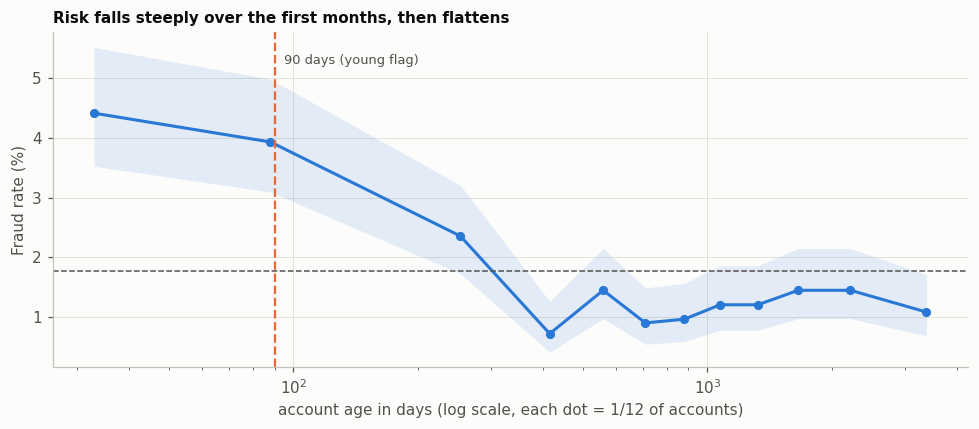

,mean (genuine),mean (fraud),PR-AUC alone,IV,IV strength,shift AUC
feature,,,,,,
log_age,6.379,5.623,0.032,0.340,strong,0.603
young,0.124,0.323,0.026,0.242,medium,0.524
new_device,0.085,0.382,0.040,0.564,very strong,0.536
nd_young,0.016,0.197,0.050,0.498,strong,0.514
nd_old,0.057,0.097,0.019,0.024,weak,0.545


In [24]:
%%analysis
fig, ax = plt.subplots(figsize=(9, 4))
t = rate_by_quantile(feats_train.account_age, q=12)
plot_rate_line(ax, t, BLUE, 'fraud rate', xs=t.x.clip(lower=1))
ax.set_xscale('log'); base_line(ax)
ax.axvline(90, color=ORANGE, lw=1.5, ls='--'); ax.text(95, t.hi.max() * 100 * 0.95, '90 days (young flag)', color=INK2, fontsize=8.5)
ax.set_xlabel('account age in days (log scale, each dot = 1/12 of accounts)'); ax.set_ylabel('Fraud rate (%)')
ax.set_title('Risk falls steeply over the first months, then flattens', fontsize=10)
plt.tight_layout(); plt.show()
display(feature_card(['log_age', 'young', 'new_device', 'nd_young', 'nd_old']))

**Key Findings**
* Risk falls steeply over the first months. The youngest twelfth of accounts (median age 33 days) defrauds at 4.4%, and the second twelfth (88 days) at 3.9%. By about a year (253 days) the rate is 2.4%, and it flattens near 1.1% to 1.5% for accounts older than about 4 years. The 90-day `young` flag sits right where the steep part ends.
* Scorecard:
  * `new_device` is very strong (IV 0.56).
  * `nd_young` is strong (IV 0.50) and the most stable identity feature (shift AUC 0.514).
  * `log_age` is strong (IV 0.34) but the most shifted feature overall (0.603). That is one reason we also keep the shift-proof flags.
  * The takeover flag `nd_old` is weak (IV 0.02), confirming (a).

### 4.4 Dimension 4: Context and opportunity (where, when and through which door?)

**Purpose.** Fraud follows opportunity:
* **Card-not-present channels** (e-commerce, app, bank transfer) need only stolen details, with no chip, PIN or signature.
* **"Liquid" merchants** (luxury, electronics, cash transfer) turn stolen credit into resellable goods or movable money. Card networks treat these as high-risk categories.
* **Night hours** mean the real owner is asleep and slow to react to alerts.
* **Cross-border** use is harder to verify.

These three flags are defined from payments domain knowledge, **not** from our fraud labels, so they cannot leak.

| Feature | Formula | Plain meaning |
|---|---|---|
| `hour_sin`, `hour_cos` | sin and cos of 2 pi x hour / 24 | places the hour on a clock face, so 23:00 sits next to 00:00 |
| `night` | 1 if hour is 0 to 5 | off-hours |
| `remote` | 1 if channel is e-commerce, mobile app or bank transfer | card-not-present |
| `liquid` | 1 if merchant is luxury, electronics or cash transfer | easily monetised |
| `foreign` | 1 if country is not SG | outside the home market |
| category indicators | one 0/1 column per merchant, country, channel | lets the model learn each category's own effect |

#### (a) The fraud clock

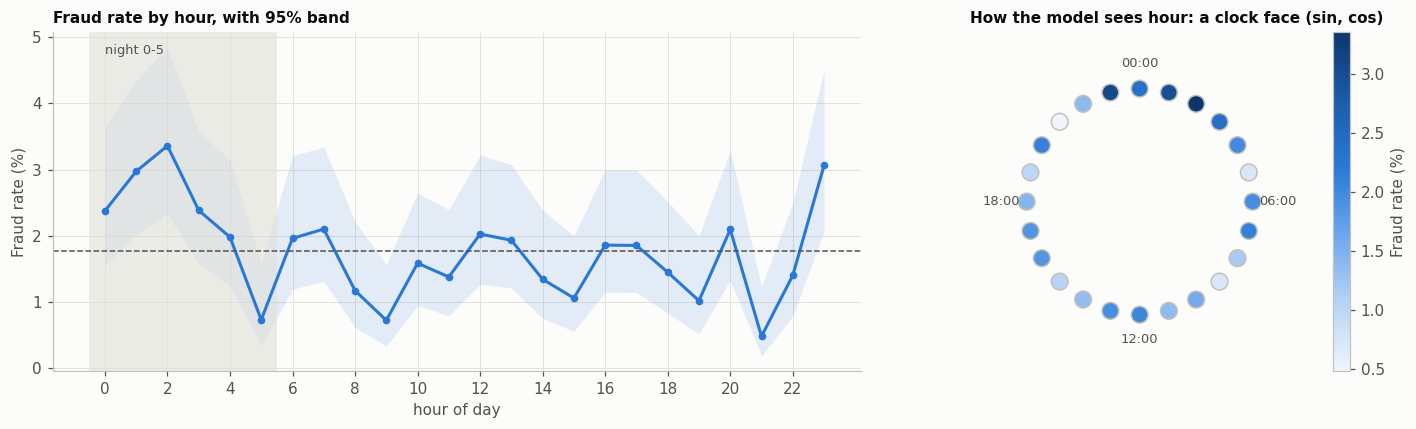

In [25]:
%%analysis
t = rate_by(train, 'transaction_hour')
fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={'width_ratios': [1.7, 1]})
ax = axes[0]
ax.fill_between(t.index, t.lo * 100, t.hi * 100, color=BLUE, alpha=0.12, lw=0)
ax.plot(t.index, t.rate * 100, color=BLUE, lw=2, marker='o', ms=4)
ax.axvspan(-0.5, 5.5, color=GRID, alpha=0.6, lw=0); ax.text(0, t.hi.max() * 100 * 0.98, 'night 0-5', color=INK2, fontsize=8.5)
base_line(ax); ax.set_xticks(range(0, 24, 2)); ax.set_xlabel('hour of day'); ax.set_ylabel('Fraud rate (%)')
ax.set_title('Fraud rate by hour, with 95% band', fontsize=10)
ax = axes[1]
ang = 2 * np.pi * t.index / 24
sc = ax.scatter(np.sin(ang), np.cos(ang), c=t.rate * 100, cmap=BLUES, s=120, edgecolor=AXIS)
for h in [0, 6, 12, 18]:
    ax.text(1.22 * np.sin(2 * np.pi * h / 24), 1.22 * np.cos(2 * np.pi * h / 24), f'{h:02d}:00', ha='center', va='center', fontsize=8.5, color=INK2)
ax.set_aspect('equal'); ax.set_xlim(-1.5, 1.5); ax.set_ylim(-1.5, 1.5); ax.axis('off')
ax.set_title('How the model sees hour: a clock face (sin, cos)', fontsize=10)
plt.colorbar(sc, ax=ax, fraction=0.04, label='Fraud rate (%)')
plt.tight_layout(); plt.show()

**Key Findings**
* The fraud clock peaks between 23:00 and 03:00: 02:00 is the riskiest hour (3.4%), followed by 23:00 (3.1%) and 01:00 (3.0%). Several daytime and evening hours sit below 1% (for example 21:00 at 0.5% and 09:00 at 0.7%).
* Note that 23:00 is just as risky as 01:00, even though 23 and 1 are far apart as plain numbers. That is exactly why hour is encoded as a point on a clock face (`hour_sin`, `hour_cos`): on the circle, 23:00 and 01:00 are neighbours.
* Hour-to-hour noise is large (each hour has only about 800 rows and 15 to 25 frauds), so the model gets a smooth cyclical shape rather than 24 separate hour indicators that would over-fit.

#### (b) Domain risk flags: share, fraud rate and lift

In [26]:
%%analysis
rows = []
for f_ in ['night', 'remote', 'liquid', 'foreign']:
    s = feats_train[f_]
    on, off = y[s == 1], y[s == 0]
    rows.append({'flag': f_, 'share of transactions': (s == 1).mean(), 'fraud rate if flag = 1': on.mean(),
                 'fraud rate if flag = 0': off.mean(), 'lift (ratio)': on.mean() / off.mean(),
                 'share of all frauds': on.sum() / y.sum(), 'IV': information_value(s), 'shift AUC': shift_auc(f_)})
display(pd.DataFrame(rows).set_index('flag').round(3))

,share of transactions,fraud rate if flag = 1,fraud rate if flag = 0,lift (ratio),share of all frauds,IV,shift AUC
flag,,,,,,,
night,0.254,0.023,0.016,1.452,0.331,0.030,0.505
remote,0.634,0.022,0.010,2.142,0.782,0.119,0.518
liquid,0.180,0.045,0.012,3.827,0.459,0.389,0.515
foreign,0.298,0.029,0.013,2.183,0.482,0.149,0.535


**Key Findings**
* **`liquid` is the strongest context flag.** Luxury, electronics and cash transfer are 18% of transactions but **46% of all frauds** (lift 3.8, IV 0.39).
* **78% of frauds come through remote channels** (lift 2.1), and foreign transactions carry 2.2 times the fraud rate of SG ones.
* `night` is the weakest flag (lift 1.45, IV 0.03). Its signal is better captured by the smooth clock encoding.
* All four flags are very stable between train and test (shift AUC 0.505 to 0.535), because they are defined from fixed domain lists.

### 4.5 Dimension 5: Data quality (is the record complete?)
**Purpose.** A missing value can mean a system glitch or a deliberately hidden attribute. Section 3 showed that, in this data, missingness is random. The `*_na` flags stay in the model as a **control**: if missingness ever starts to carry signal (for example, in the private test set), the model has a place to put it, and regularisation keeps their weights near zero meanwhile.

In [27]:
%%analysis
display(feature_card([c + '_na' for c in NA_COLS]))

,mean (genuine),mean (fraud),PR-AUC alone,IV,IV strength,shift AUC
feature,,,,,,
transactions_last_24h_na,0.000,0.000,0.018,0.002,not useful,0.500
spend_last_24h_na,0.007,0.011,0.018,0.004,not useful,0.507
account_age_na,0.007,0.008,0.018,0.001,not useful,0.507
new_device_na,0.006,0.000,0.018,0.007,not useful,0.508
transactions_last_1h_na,0.007,0.011,0.018,0.003,not useful,0.506


**Key Findings**
* Every missing-value flag has IV below 0.01 ("not useful") and a shift AUC of 0.50 to 0.51. This confirms Section 3: missingness carries no fraud signal in this data.
* They stay in the model as a **control**. If missingness starts to matter on the private test set (where it is three times as common), the model has somewhere to put that effect. Meanwhile L2 regularisation keeps their weights near zero (Section 8).

### 4.6 Bringing the dimensions together

#### (a) Red-flag stacking
We count, for every transaction, how many of eight classic red flags it raises:
* burst (4+ transactions in the last hour)
* young account (under 90 days)
* new device
* night (hours 0 to 5)
* remote channel
* liquid merchant
* foreign country
* amount more than e (about 2.7) times the account's average today

This is how a simple rules engine scores risk.

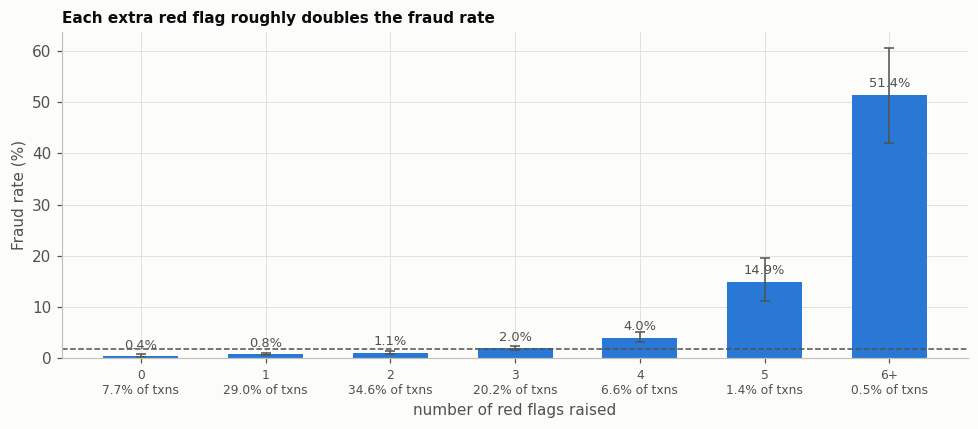

_rf,0.0,1.0,2.0,3.0,4.0,5.0,6.0
n,1534.0000,5808.0000,6911.0000,4045.0000,1320.0000,275.0000,107.000
frauds,6.0000,44.0000,75.0000,79.0000,53.0000,41.0000,55.000
rate,0.0039,0.0076,0.0109,0.0195,0.0402,0.1491,0.514


red_flags alone: PR-AUC 0.143 | IV 1.248


In [28]:
%%analysis
rf = feats_train.red_flags.clip(upper=6)
t = rate_by(train.assign(_rf=rf.values), '_rf')
fig, ax = plt.subplots(figsize=(9, 4))
xs = t.index.astype(int)
ax.bar(xs, t.rate * 100, color=BLUE, width=0.6)
ax.errorbar(xs, t.rate * 100, yerr=[(t.rate - t.lo) * 100, (t.hi - t.rate) * 100], fmt='none', ecolor=INK2, capsize=3, lw=1)
for x_, r_, n_ in zip(xs, t.rate, t.n):
    ax.text(x_, r_ * 100 + 1.5, f'{r_:.1%}', ha='center', fontsize=8.5, color=INK2)
base_line(ax)
ax.set_xticks(xs, [f'{x_}{"+" if x_ == 6 else ""}\n{n_ / len(train):.1%} of txns' for x_, n_ in zip(xs, t.n)], fontsize=8)
ax.set_xlabel('number of red flags raised'); ax.set_ylabel('Fraud rate (%)')
ax.set_title('Each extra red flag roughly doubles the fraud rate', fontsize=10)
plt.tight_layout(); plt.show()
display(t[['n', 'frauds', 'rate']].T.round(4))
print(f'red_flags alone: PR-AUC {average_precision_score(y, feats_train.red_flags):.3f} | IV {information_value(feats_train.red_flags):.3f}')

**Key Findings**
* With **no** red flags, fraud is almost absent: 0.39% (n = 1,534). Each extra flag roughly doubles the rate: 0.8%, 1.1%, 2.0%, 4.0%, then **14.9% with 5 flags** and **51% with 6 or more** (n = 107).
* On its own, the red-flag count reaches **PR-AUC 0.143** (8 times random) and **IV 1.25**, the single strongest feature we built.
* **Why this matters for model choice.** A red-flag count *is* a logistic regression in which every flag gets the same weight. The stacking pattern (each flag multiplies the odds) is exactly the additive-in-log-odds structure that logistic regression assumes. A fitted logistic regression simply learns a better weight for each flag. This is the clearest evidence of why a linear model suits this problem (Section 6). It also predicts, correctly, that adding `red_flags` as a feature brings nothing new (Section 4.10).

#### (b) Feature scorecard: predictive *and* stable?
Every candidate numeric feature, placed by Information Value (x axis, how predictive) against shift AUC (y axis, how much it moves between train and test). The best features sit bottom-right: strong and stable.

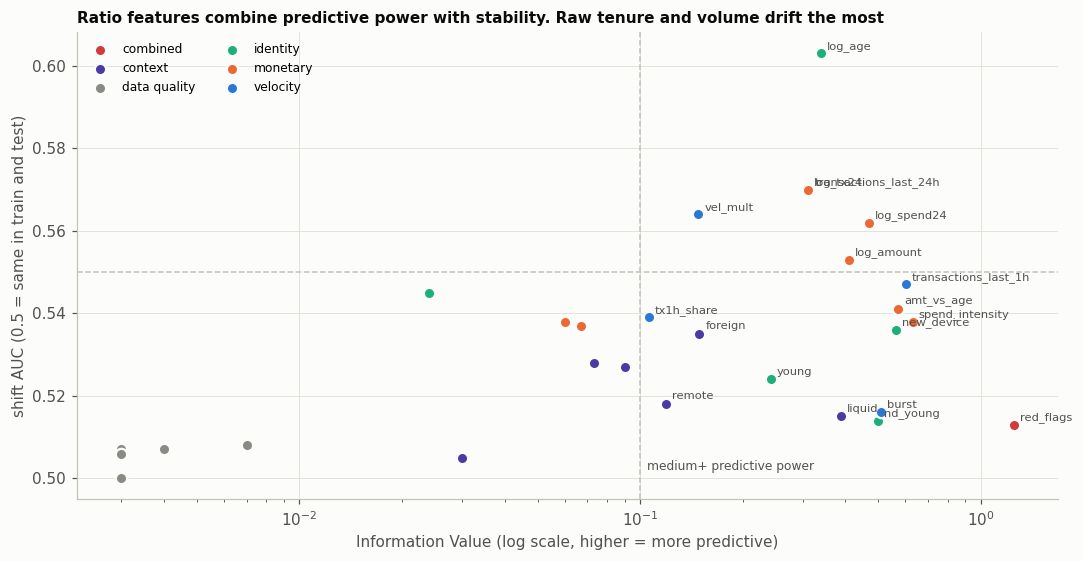

,mean (genuine),mean (fraud),PR-AUC alone,IV,IV strength,shift AUC,dimension
feature,,,,,,,
red_flags,1.929,3.402,0.143,1.248,very strong,0.513,combined
spend_intensity,-1.021,0.703,0.071,0.631,very strong,0.538,monetary
transactions_last_1h,0.855,1.911,0.061,0.601,very strong,0.547,velocity
amt_vs_age,-1.930,-0.348,0.062,0.570,very strong,0.541,monetary
new_device,0.085,0.382,0.040,0.564,very strong,0.536,identity
burst,0.020,0.215,0.048,0.509,very strong,0.516,velocity
nd_young,0.016,0.197,0.050,0.498,strong,0.514,identity
log_spend24,5.358,6.330,0.052,0.468,strong,0.562,monetary
log_amount,4.450,5.276,0.038,0.410,strong,0.553,monetary


In [29]:
%%analysis
all_feats = list(dict.fromkeys(sum(FEATURE_GROUPS.values(), []) + sum(CANDIDATE_GROUPS.values(), [])))
SCORECARD = feature_card(all_feats)
SCORECARD['dimension'] = [next((k for k, v in {'velocity': ['transactions_last_1h', 'vel_mult', 'tx1h_share', 'burst'],
                                               'monetary': ['log_amount', 'log_spend24', 'amt_vs_avg24', 'amt_share', 'amt_vs_age', 'spend_intensity', 'log_tx24', 'transactions_last_24h'],
                                               'identity': ['log_age', 'young', 'new_device', 'nd_young', 'nd_old'],
                                               'context': ['hour_sin', 'hour_cos', 'night', 'remote', 'liquid', 'foreign'],
                                               'combined': ['red_flags']}.items() if f_ in v), 'data quality') for f_ in SCORECARD.index]
DIM_COLORS = {'velocity': BLUE, 'monetary': ORANGE, 'identity': AQUA, 'context': VIOLET, 'combined': CRITICAL, 'data quality': MUTED}
fig, ax = plt.subplots(figsize=(10, 5.2))
for dim, g in SCORECARD.groupby('dimension'):
    ax.scatter(g['IV'].clip(lower=0.003), g['shift AUC'], s=55, color=DIM_COLORS[dim], label=dim, edgecolor=SURFACE, linewidth=1.5, zorder=3)
for f_, r_ in SCORECARD.iterrows():
    if r_['IV'] > 0.1 or r_['shift AUC'] > 0.56:
        ax.annotate(f_, (max(r_['IV'], 0.003), r_['shift AUC']), xytext=(4, 3), textcoords='offset points', fontsize=7.5, color=INK2)
ax.set_xscale('log'); ax.axvline(0.1, color=AXIS, lw=1, ls='--'); ax.axhline(0.55, color=AXIS, lw=1, ls='--')
ax.text(0.105, 0.502, 'medium+ predictive power', fontsize=8, color=INK2)
ax.set_xlabel('Information Value (log scale, higher = more predictive)'); ax.set_ylabel('shift AUC (0.5 = same in train and test)')
ax.legend(fontsize=8, loc='upper left', ncol=2)
ax.set_title('Ratio features combine predictive power with stability. Raw tenure and volume drift the most', fontsize=10)
plt.tight_layout(); plt.show()
display(SCORECARD.sort_values('IV', ascending=False))

**Key Findings**
* **Bottom right, strong and stable:** `transactions_last_1h`, `spend_intensity`, `amt_vs_age`, `new_device`, `burst`, `nd_young` and `liquid`. These are the backbone of a model that should survive the shift.
* **Top right, strong but drifting:** `log_age` (shift AUC 0.603), the 24h counts (0.57), `log_spend24` (0.56) and `log_amount` (0.55). The model uses them, but the shift-weighted validation watches how much it relies on them.
* `red_flags` is far to the right (IV 1.25), but, as explained in (a), it is a summary of the others.
* No feature has an IV above 1 except the combined flag count. That fits a dataset with **no leakage**: no single column gives fraud away.

#### (c) How the engineered features relate to each other

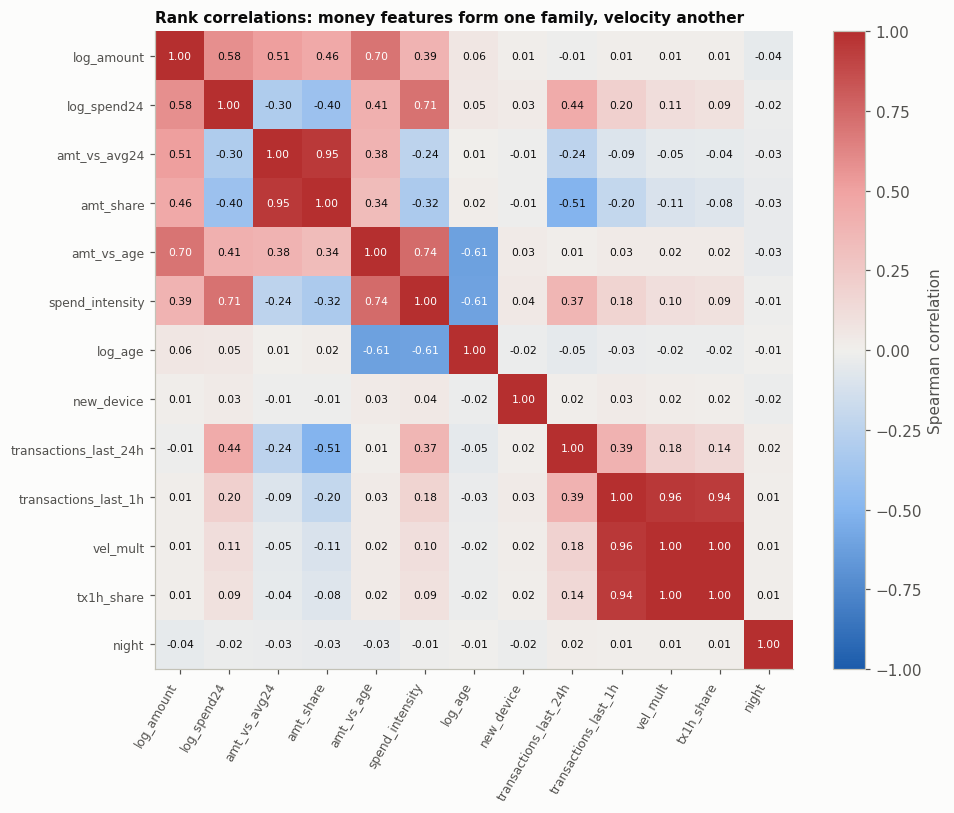

In [30]:
%%analysis
core = ['log_amount', 'log_spend24', 'amt_vs_avg24', 'amt_share', 'amt_vs_age', 'spend_intensity', 'log_age', 'new_device',
        'transactions_last_24h', 'transactions_last_1h', 'vel_mult', 'tx1h_share', 'night']
cm = feats_train[core].corr(method='spearman')
div = LinearSegmentedColormap.from_list('div', ['#1c5cab', '#86b6ef', '#f0efec', '#f0a3a2', '#b52f2f'])
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(cm.values, cmap=div, vmin=-1, vmax=1)
for i in range(len(core)):
    for j in range(len(core)):
        ax.text(j, i, f'{cm.values[i, j]:.2f}', ha='center', va='center', fontsize=7, color='white' if abs(cm.values[i, j]) > 0.6 else INK)
ax.set_xticks(range(len(core)), core, rotation=60, ha='right', fontsize=8); ax.set_yticks(range(len(core)), core, fontsize=8); ax.grid(False)
plt.colorbar(im, ax=ax, fraction=0.04, label='Spearman correlation')
ax.set_title('Rank correlations: money features form one family, velocity another', fontsize=10)
plt.tight_layout(); plt.show()

**Key Findings**
* **Two redundant pairs.**
  * `vel_mult` and `tx1h_share` have rank correlation **1.00**: they order transactions identically and differ only in scale.
  * `amt_vs_avg24` and `amt_share` correlate at 0.95.
  * Keeping both members of a pair costs little in a regularised model, but the drop-one test in 4.10 confirms neither pair adds much.
* **Tenure links the money family to age.** `amt_vs_age` and `spend_intensity` correlate at -0.61 with `log_age` by construction.
* **`new_device` and `night` are uncorrelated with everything** (all at or below 0.05). They carry unique information, which is why they keep large SHAP contributions in Section 8.

### 4.7 Behavioural profiles (k-means clustering)

**Purpose.** Features describe one dimension at a time. Profiles describe *kinds of transactions*. We cluster transactions on eight behavioural features, one or two per dimension, then ask three questions:
1. Which kinds of behaviour carry fraud?
2. Is the test set made of the same kinds of behaviour as the training set?
3. Does each profile tell a story a fraud analyst would recognise?

**Implementation.**
* Features: `tx1h_share`, `vel_mult`, `log_amount`, `amt_vs_avg24`, `log_age`, `new_device`, `spend_intensity`, `night`.
* Preparation: median imputation, then standardisation using training statistics.
* Choosing k: k-means for k = 3 to 7, picking the number of clusters with the best silhouette score on a 4,000-row sample.
* Profiles are fitted on **training rows only** and then applied to test rows.
* Each profile is named automatically from the two features where its centre differs most from the average transaction.

Profiles are used for understanding and monitoring. They are not model inputs, because logistic regression already sees the underlying features directly.

silhouette by k: {3: np.float64(0.213), 4: np.float64(0.233), 5: np.float64(0.24), 6: np.float64(0.22), 7: np.float64(0.235)} -> k = 5


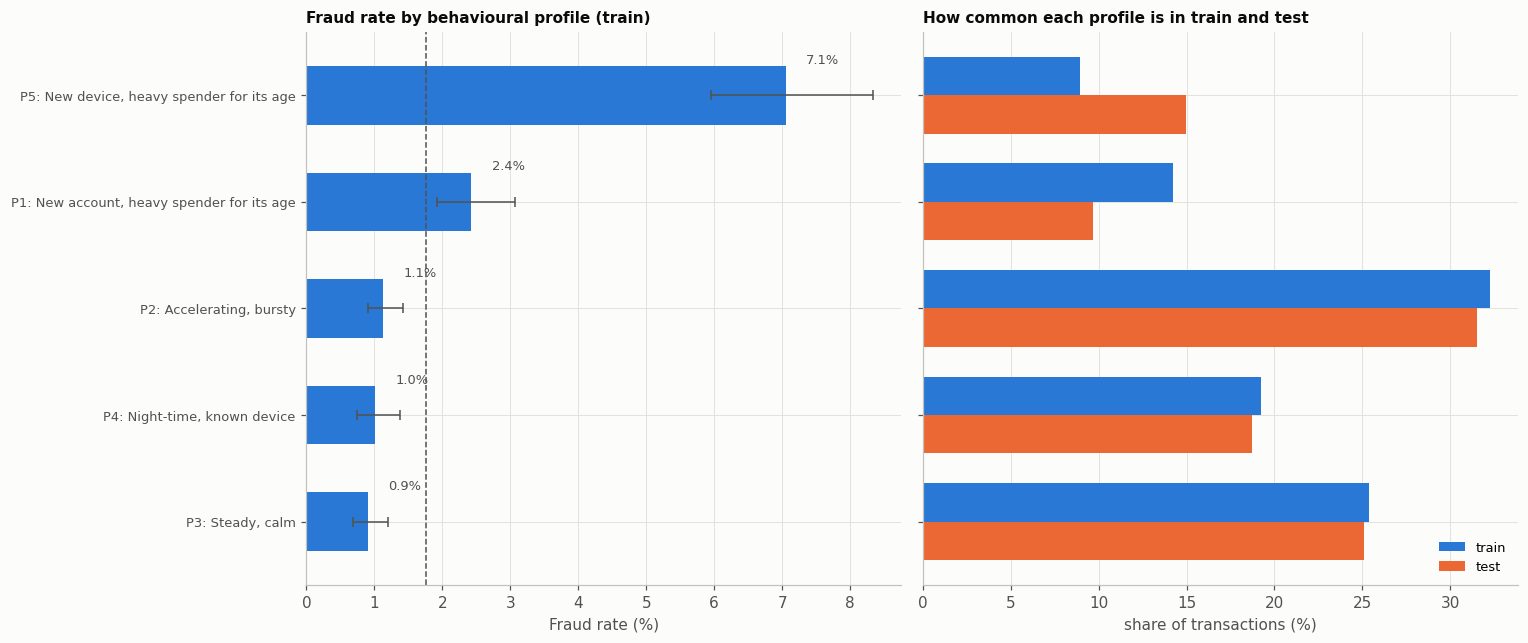

,tx1h_share,vel_mult,log_amount,amt_vs_avg24,log_age,new_device,spend_intensity,night
"P1: New account, heavy spender for its age",-0.03,0.05,0.14,-0.17,-1.73,-0.30,1.40,-0.10
"P2: Accelerating, bursty",0.82,0.89,0.00,-0.07,0.36,-0.31,-0.15,-0.50
"P3: Steady, calm",-0.93,-1.09,0.00,0.18,0.33,-0.31,-0.41,-0.58
"P4: Night-time, known device",-0.15,-0.11,-0.12,0.02,0.30,-0.31,-0.30,1.71
"P5: New device, heavy spender for its age",0.04,0.04,0.02,-0.04,-0.14,3.18,0.15,-0.07


,train share,test share,train fraud rate,frauds
_p,,,,
"P3: Steady, calm",0.254,0.251,0.009,46
"P4: Night-time, known device",0.192,0.187,0.010,39
"P2: Accelerating, bursty",0.323,0.316,0.011,73
"P1: New account, heavy spender for its age",0.142,0.097,0.024,69
"P5: New device, heavy spender for its age",0.089,0.150,0.071,126


In [31]:
%%analysis
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
PROFILE_FEATURES = ['tx1h_share', 'vel_mult', 'log_amount', 'amt_vs_avg24', 'log_age', 'new_device', 'spend_intensity', 'night']
WORDS = {'tx1h_share': ('bursty', 'calm'), 'vel_mult': ('accelerating', 'steady'), 'log_amount': ('big-ticket', 'small-ticket'),
         'amt_vs_avg24': ('out-of-character amount', 'routine amount'), 'log_age': ('established account', 'new account'),
         'new_device': ('new device', 'known device'), 'spend_intensity': ('heavy spender for its age', 'light spender'),
         'night': ('night-time', 'daytime')}
P_med = feats_train[PROFILE_FEATURES].median()
P_mu = feats_train[PROFILE_FEATURES].fillna(P_med).mean(); P_sd = feats_train[PROFILE_FEATURES].fillna(P_med).std()
Ztr = ((feats_train[PROFILE_FEATURES].fillna(P_med) - P_mu) / P_sd).to_numpy()
Zte = ((feats_test[PROFILE_FEATURES].fillna(P_med) - P_mu) / P_sd).to_numpy()
rng = np.random.default_rng(SEED); samp = rng.choice(len(Ztr), 4000, replace=False)
sil = {}
for k in range(3, 8):
    km_ = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Ztr)
    sil[k] = silhouette_score(Ztr[samp], km_.labels_[samp])
K_BEST = max(sil, key=sil.get)
km = KMeans(n_clusters=K_BEST, n_init=10, random_state=SEED).fit(Ztr)
cent = pd.DataFrame(km.cluster_centers_, columns=PROFILE_FEATURES)
names = []
for i, r_ in cent.iterrows():
    top2 = r_.abs().sort_values(ascending=False).index[:2]
    nm = ', '.join(WORDS[f_][0] if r_[f_] > 0 else WORDS[f_][1] for f_ in top2)
    names.append(nm[0].upper() + nm[1:])
names = [f'P{i + 1}: {n}' for i, n in enumerate(names)]
prof_tr, prof_te = np.array(names)[km.labels_], np.array(names)[km.predict(Zte)]
print('silhouette by k:', {k: round(v, 3) for k, v in sil.items()}, '-> k =', K_BEST)

t = rate_by(train.assign(_p=prof_tr), '_p').sort_values('rate')
share = pd.DataFrame({'train': pd.Series(prof_tr).value_counts(normalize=True), 'test': pd.Series(prof_te).value_counts(normalize=True)}).reindex(t.index).fillna(0)
fig, axes = plt.subplots(1, 2, figsize=(14, 0.75 * K_BEST + 2.2), sharey=True)
ys = np.arange(len(t))
ax = axes[0]
ax.barh(ys, t.rate * 100, color=BLUE, height=0.55)
ax.errorbar(t.rate * 100, ys, xerr=[(t.rate - t.lo) * 100, (t.hi - t.rate) * 100], fmt='none', ecolor=INK2, capsize=3, lw=1)
for y_, r_ in zip(ys, t.rate):
    ax.text(r_ * 100 + 0.3, y_ + 0.3, f'{r_:.1%}', fontsize=8.5, color=INK2)
base_line(ax, horizontal=False); ax.set_yticks(ys, t.index, fontsize=8.5); ax.set_xlabel('Fraud rate (%)')
ax.set_title('Fraud rate by behavioural profile (train)', fontsize=10)
ax = axes[1]
h = 0.36
ax.barh(ys + h / 2, share['train'] * 100, height=h, color=BLUE, label='train')
ax.barh(ys - h / 2, share['test'] * 100, height=h, color=ORANGE, label='test')
ax.set_xlabel('share of transactions (%)'); ax.legend(fontsize=8.5, loc='lower right')
ax.set_title('How common each profile is in train and test', fontsize=10)
plt.tight_layout(); plt.show()
display(cent.set_index(pd.Index(names)).round(2).style.background_gradient(cmap=div, vmin=-2, vmax=2, axis=None).format('{:.2f}'))
display(pd.DataFrame({'train share': share['train'], 'test share': share['test'], 'train fraud rate': t.rate, 'frauds': t.frauds}).round(3))

**Key Findings**
* The best silhouette is at **k = 5** (0.24). That is a moderate value: transaction behaviour is a continuum rather than neatly separated groups, which is normal for payments data.
* **P5 "New device, heavy spender for its age"** defrauds at **7.1%** (4 times the average). It holds 126 of the 353 frauds (36%) while being only 8.9% of transactions. This is the mule-account profile from 4.3, now found without using the labels.
* **P1 "New account, heavy spender for its age"** is the second risky profile (2.4%). The other three profiles (calm, bursty but established, night-time on a known device) all sit near 1%.
* **The test set contains 1.7 times as much of the riskiest profile** (P5 is 15.0% of test against 8.9% of training), and less of P1. So we should expect **more fraud in the test set** than the 1.76% seen in training. This agrees with the model's average test prediction (about 2.3%, Section 10) and with the higher alert rate on test in Section 9.
* For a bank, profiles like these are useful for **monitoring**: a sudden growth of P5 in live traffic is an early warning worth investigating.

### 4.8 Checking the "linear in log-odds" assumption feature by feature
Logistic regression assumes each numeric feature moves the **log-odds** of fraud in a straight line. We check this directly: bin each feature, compute the observed log-odds per bin, and compare with a straight-line fit. Where the dots bend away from the line, the raw feature needs reshaping.

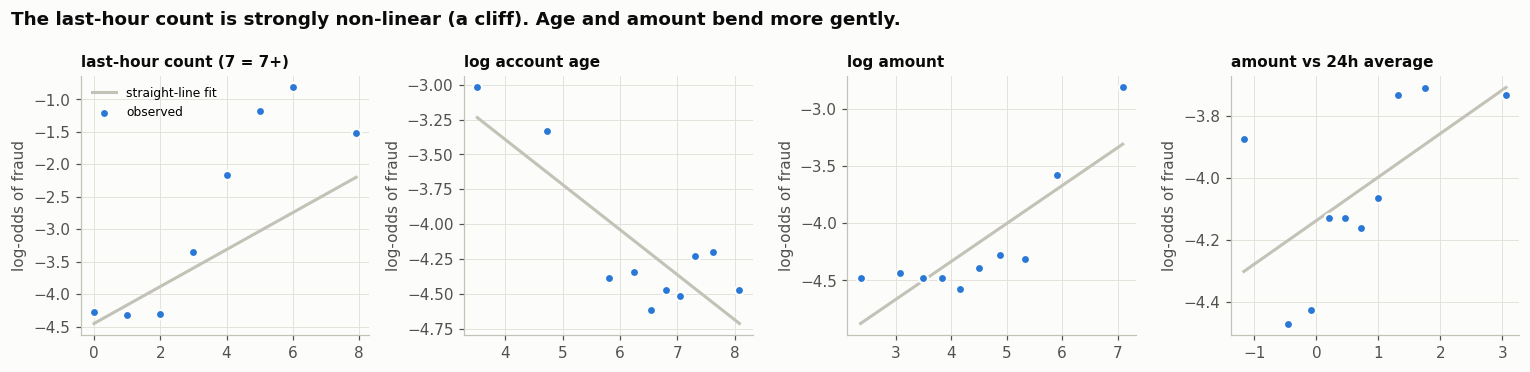

In [32]:
%%analysis
def logodds_panel(ax, values, title, bins=10, discrete=False):
    v = pd.Series(values)
    grp = v.clip(upper=7) if discrete else pd.qcut(v.rank(method='first'), bins, labels=False)
    g = pd.DataFrame({'x': v, 'g': grp, 'y': y}).dropna().groupby('g').agg(x=('x', 'mean'), k=('y', 'sum'), n=('y', 'size'))
    lo = np.log((g.k + 0.5) / (g.n - g.k + 0.5))
    coef = np.polyfit(g.x, lo, 1, w=np.sqrt(g.n))
    ax.plot(g.x, np.polyval(coef, g.x), color=AXIS, lw=2, label='straight-line fit')
    ax.scatter(g.x, lo, s=36, color=BLUE, zorder=3, edgecolor=SURFACE, linewidth=1.5, label='observed')
    ax.set_title(title, fontsize=10); ax.set_ylabel('log-odds of fraud')

fig, axes = plt.subplots(1, 4, figsize=(14, 3.4))
logodds_panel(axes[0], feats_train.transactions_last_1h, 'last-hour count (7 = 7+)', discrete=True)
logodds_panel(axes[1], feats_train.log_age, 'log account age')
logodds_panel(axes[2], feats_train.log_amount, 'log amount')
logodds_panel(axes[3], feats_train.amt_vs_avg24, 'amount vs 24h average')
axes[0].legend(fontsize=8, loc='upper left')
fig.suptitle('The last-hour count is strongly non-linear (a cliff). Age and amount bend more gently.',
             x=0.01, ha='left', fontweight='bold', color=INK)
plt.tight_layout(); plt.show()

**Key Findings.**
* **The last-hour count clearly breaks the assumption.** Log-odds are flat from 0 to 2, then climb by about 3.5 units (roughly 30 times the odds) up to 6. A single slope would under-score 5 or 6 transactions and over-score 1 or 2. Our fix is to give the model **one indicator per band** (0 to 2, 3, 4, 5, 6, 7+), so each band gets its own effect. Section 4.10 confirms this is the most valuable engineered element.
* **Log account age and log amount bend more gently.** Age falls steeply over the first months, then flattens. Amount is flat, then rises in the top decile. These are partly handled by the `young` and `nd_young` flags and by the tenure ratios. In exploratory runs we also tried a fully flexible version (a spline "GAM", giving every numeric feature a curved shape). It *lowered* CV PR-AUC to about 0.21, because with only 353 frauds the extra curve parameters fit noise. So a straight line in the log scale, plus targeted flags, is the better bias-variance trade-off here.
* Relative amount is noisy, with no clear shape, which matches its low IV.

### 4.9 The model object: `FraudScorer`
**What we did.** We wrapped cleaning, feature engineering, imputation, scaling, encoding and the logistic regression into **one class**, used identically in cross-validation, for the final model and inside `model.pkl`.

**Why.**
* The organisers run the pickle on raw private-test rows, so the pickle must contain *all* preprocessing.
* After fitting, the class keeps only numpy arrays (coefficients, medians, scaling, category lists, caps), with no scikit-learn objects. The pickle therefore cannot break because Colab has a different scikit-learn version.
* It also produces plain-English **reason codes** for every score, used by the dashboard in Section 11.

In [33]:
# [Runs in both modes]
def make_lr(C=0.1, l1_ratio=0.0, class_weight=None):
    # Version-proof logistic regression: L2 by default, elastic-net when l1_ratio > 0.
    # Imported here so the saved model does not need scikit-learn just to make predictions.
    from sklearn.linear_model import LogisticRegression
    if l1_ratio and l1_ratio > 0:
        if inspect.signature(LogisticRegression).parameters['penalty'].default == 'deprecated':
            return LogisticRegression(C=C, l1_ratio=l1_ratio, solver='saga', max_iter=5000, class_weight=class_weight)
        return LogisticRegression(C=C, penalty='elasticnet', l1_ratio=l1_ratio, solver='saga', max_iter=5000, class_weight=class_weight)
    return LogisticRegression(C=C, max_iter=5000, class_weight=class_weight)

# Which raw concept each design column belongs to (used for grouped SHAP and reason codes).
def concept_of(col):
    if col.startswith('tx1h_band') or col in ('vel_mult', 'tx1h_share', 'burst', 'transactions_last_1h'):
        return 'velocity_1h'
    if col in ('log_age', 'young'):
        return 'account_age'
    if col in ('new_device', 'nd_young', 'nd_old'):
        return 'new_device'
    if col in ('log_amount', 'amt_vs_avg24', 'amt_share', 'amt_vs_age'):
        return 'amount'
    if col in ('log_spend24', 'spend_intensity'):
        return 'spend_24h'
    if col == 'remote':
        return 'transaction_channel'
    if col == 'liquid':
        return 'merchant_category'
    if col == 'foreign':
        return 'country'
    if col == 'red_flags':
        return 'red_flags'
    if col in ('transactions_last_24h', 'log_tx24'):
        return 'activity_24h'
    if col in ('hour_sin', 'hour_cos', 'night'):
        return 'time_of_day'
    if col.endswith('_na'):
        return 'missing_data'
    for c in CAT_COLS:
        if col.startswith(c):
            return c
    return col

class FraudScorer:
    # Regularised logistic regression with all preprocessing built in. Takes raw transaction rows.
    def __init__(self, C=0.1, l1_ratio=0.0, use_bands=True, drop_groups=(), extra_groups=(), num_cols=None,
                 class_weight=None, sampler=None, threshold=0.5):
        self.C, self.l1_ratio, self.use_bands = C, l1_ratio, use_bands
        self.drop_groups, self.extra_groups, self.num_cols = tuple(drop_groups), tuple(extra_groups), num_cols
        self.class_weight, self.sampler, self.threshold = class_weight, sampler, threshold

    def _numeric_columns(self):
        if self.num_cols is not None:
            return list(self.num_cols)
        groups = {**FEATURE_GROUPS, **{g: CANDIDATE_GROUPS[g] for g in self.extra_groups}}
        cols = [c for g, cs in groups.items() if g not in self.drop_groups for c in cs]
        if self.use_bands:   # bands replace the raw count and the single burst flag
            cols = [c for c in cols if c not in ('transactions_last_1h', 'burst')]
        return cols

    def _design(self, feats):
        Xn = feats[self.num_cols_].to_numpy(float)
        Xn = np.where(np.isnan(Xn), self.medians_, Xn)
        parts = [(Xn - self.mean_) / self.scale_]
        for c in CAT_COLS:
            v = feats[c].to_numpy(object)
            parts.append((v[:, None] == np.array(CAT_LEVELS[c], dtype=object)[None, :]).astype(float))
        if self.use_bands:
            b = feats['tx1h_band'].fillna(TX1H_LABELS[0]).to_numpy(object)    # missing count -> most common band
            parts.append((b[:, None] == np.array(TX1H_LABELS, dtype=object)[None, :]).astype(float))
        return np.hstack(parts)

    def fit(self, data, yy):
        yy = np.asarray(yy).astype(int)
        raw = clean_raw(data)
        self.bounds_ = {c: (float(np.nanpercentile(raw[c], 0.1)), float(np.nanpercentile(raw[c], 99.9)))
                        for c in ['transaction_amount', 'spend_last_24h', 'account_age', 'transactions_last_24h', 'transactions_last_1h']}
        raw = clean_raw(data, self.bounds_)
        feats = add_features(raw)
        self.num_cols_ = self._numeric_columns()
        Xn = feats[self.num_cols_].to_numpy(float)
        self.medians_ = np.nan_to_num(np.nanmedian(Xn, axis=0))
        Xn = np.where(np.isnan(Xn), self.medians_, Xn)
        self.mean_, self.scale_ = Xn.mean(0), Xn.std(0)
        self.scale_[self.scale_ == 0] = 1.0
        X = self._design(feats)
        self.design_mean_ = X.mean(0)             # background for exact linear SHAP values
        self.feature_names_ = (self.num_cols_ + [f'{c}={l}' for c in CAT_COLS for l in CAT_LEVELS[c]]
                               + ([f'tx1h_band={l}' for l in TX1H_LABELS] if self.use_bands else []))
        Xfit, yfit = (X, yy) if self.sampler is None else self.sampler.fit_resample(X, yy)
        lr = make_lr(self.C, self.l1_ratio, self.class_weight).fit(Xfit, yfit)
        self.coef_, self.intercept_ = lr.coef_.ravel().copy(), float(lr.intercept_[0])
        self.sampler = None                       # keep the fitted object free of library objects
        self.n_train_, self.train_rate_ = len(yy), float(yy.mean())
        return self

    def transform(self, data):
        return self._design(add_features(clean_raw(data, self.bounds_)))

    def decision_function(self, data):
        if len(to_frame(data)) == 0:
            return np.zeros(0)
        return self.transform(data) @ self.coef_ + self.intercept_

    def predict_proba(self, data):
        z = np.clip(self.decision_function(data), -35, 35)
        p = 1.0 / (1.0 + np.exp(-z))
        return np.column_stack([1 - p, p])

    def predict(self, data):
        return (self.predict_proba(data)[:, 1] >= self.threshold).astype(int)

    def contributions(self, data):
        # Exact SHAP values for a linear model (features treated as independent): coef * (x - mean).
        X = self.transform(data)
        return (X - self.design_mean_) * self.coef_

    def explain(self, data, top_k=3):
        # Plain-English reasons that pushed each transaction's score up the most.
        import types
        raw = clean_raw(data, None)
        phi = self.contributions(data)
        concepts = sorted(set(concept_of(c) for c in self.feature_names_))
        member = np.array([[concept_of(c) == k for k in concepts] for c in self.feature_names_], dtype=float)
        grouped = phi @ member                                   # contribution of each concept, per row
        order = np.argsort(-grouped, axis=1)[:, :top_k]
        rows = [types.SimpleNamespace(**r) for r in raw.to_dict('records')]
        out = []
        for i, r in enumerate(rows):
            reasons = [self._reason(concepts[j], r) for j in order[i] if grouped[i, j] > 0.05]
            out.append(' | '.join(reasons) if reasons else 'no strong risk factors')
        return out

    @staticmethod
    def _reason(concept, r):
        f = lambda v, fmt: 'unknown' if pd.isna(v) else fmt.format(v)
        if concept == 'velocity_1h':
            return f'{f(r.transactions_last_1h, "{:.0f}")} transactions in the last hour (typical: 0 to 2)'
        if concept == 'account_age':
            return f'account is only {f(r.account_age, "{:,.0f}")} days old'
        if concept == 'new_device':
            return 'first transaction from this device'
        if concept == 'amount':
            avg = r.spend_last_24h / (r.transactions_last_24h + 1) if pd.notna(r.spend_last_24h) else np.nan
            ratio = r.transaction_amount / avg if pd.notna(avg) and avg > 0 else np.nan
            extra = f' ({ratio:.1f}x the account average today)' if pd.notna(ratio) else ''
            return f'large amount {f(r.transaction_amount, "{:,.2f}")}{extra}'
        if concept == 'spend_24h':
            return f'spent {f(r.spend_last_24h, "{:,.0f}")} in the last 24h on an account {f(r.account_age, "{:,.0f}")} days old'
        if concept == 'activity_24h':
            return f'{f(r.transactions_last_24h, "{:.0f}")} transactions in the last 24h'
        if concept == 'time_of_day':
            return f'made at {f(r.transaction_hour, "{:02.0f}")}:00 (night hours carry more fraud)'
        if concept == 'merchant_category':
            return f'higher-risk merchant category ({r.merchant_category})'
        if concept == 'country':
            return f'higher-risk country ({r.country})'
        if concept == 'transaction_channel':
            return f'remote channel ({r.transaction_channel})'
        if concept == 'missing_data':
            return 'key account fields are missing'
        if concept == 'red_flags':
            return 'several classic red flags at once'
        return concept

In [34]:
%%analysis
# Sanity check: FraudScorer must match an equivalent scikit-learn pipeline on the same design.
fs = FraudScorer().fit(train, y)
Xd = fs.transform(train)
ref = make_lr(0.1).fit(Xd, y)
print('max |FraudScorer - sklearn| probability difference:', np.abs(fs.predict_proba(train)[:, 1] - ref.predict_proba(Xd)[:, 1]).max())
print('design matrix:', Xd.shape, '| features:', len(fs.feature_names_))

max |FraudScorer - sklearn| probability difference: 0.0
design matrix: (20000, 51) | features: 51


### 4.10 Which features earn a place in the model?
**What we did.** We ran two steps, each with a decision rule fixed **before** looking at results. Every comparison is **paired**: the same 15 folds are scored with and without the change, which removes most of the fold-to-fold noise.

1. **Forward test of candidate groups.** Each candidate group (`tenure`, `domain_flags`, `red_flag_count`, `takeover`) is added to the core model on its own. It is **accepted** if plain PR-AUC improves by more than one standard error of the paired difference **and** shift-weighted PR-AUC does not fall.
2. **Drop-one ablation** on the resulting model. A group is **dropped** only if removing it improves plain PR-AUC by more than one standard error without lowering the shift-weighted score.

**Why.** With 353 frauds, a feature can look helpful purely by luck. Fixed rules plus paired comparisons stop us from fooling ourselves.

In [35]:
%%analysis
def paired(r, ref):
    d, dw = r['ap'] - ref['ap'], r['wap'] - ref['wap']
    return d.mean(), d.std(ddof=1) / np.sqrt(len(d)), dw.mean(), dw.std(ddof=1) / np.sqrt(len(dw))

core_res = cross_validate(lambda: FraudScorer(), 'LR core groups', store=False)
fwd = []
for g in CANDIDATE_GROUPS:
    r = cross_validate(lambda g=g: FraudScorer(extra_groups=(g,)), f'  + {g}', store=False)
    dm, se, dwm, sew = paired(r, core_res)
    fwd.append({'candidate group': g, 'features': ', '.join(CANDIDATE_GROUPS[g]), 'PR-AUC': r['ap'].mean(), 'gain': dm, 'SE': se,
                'shift-weighted': r['wap'].mean(), 'shift gain': dwm, 'shift SE': sew, 'accept?': bool(dm > se and dwm >= 0)})
fwd = pd.DataFrame(fwd).set_index('candidate group')
display(fwd.round(4))
FINAL_EXTRA = tuple(fwd.index[fwd['accept?']])
print('Accepted candidate groups:', FINAL_EXTRA if FINAL_EXTRA else 'none')

full_res = cross_validate(lambda: FraudScorer(extra_groups=FINAL_EXTRA), 'LR engineered (all groups)')
abl = []
for g in [g for g in list(FEATURE_GROUPS) + list(FINAL_EXTRA) if g != 'base']:
    kw = dict(extra_groups=tuple(x for x in FINAL_EXTRA if x != g), drop_groups=(g,) if g in FEATURE_GROUPS else ())
    r = cross_validate(lambda kw=kw: FraudScorer(**kw), f'  without {g}', store=False)
    dm, se, dwm, sew = paired(r, full_res)
    abl.append({'group removed': g, 'PR-AUC': r['ap'].mean(), 'change': dm, 'SE': se, 'shift-weighted': r['wap'].mean(),
                'shift change': dwm, 'shift SE': sew, 'drop?': bool(dm > se and dwm >= 0)})
r = cross_validate(lambda: FraudScorer(extra_groups=FINAL_EXTRA, use_bands=False), '  without last-hour bands', store=False)
dm, se, dwm, sew = paired(r, full_res)
abl.append({'group removed': 'tx1h bands (use raw count + burst flag)', 'PR-AUC': r['ap'].mean(), 'change': dm, 'SE': se,
            'shift-weighted': r['wap'].mean(), 'shift change': dwm, 'shift SE': sew, 'drop?': False})
abl = pd.DataFrame(abl).set_index('group removed')
display(abl.round(4))
FINAL_DROP = tuple(g for g in abl.index[abl['drop?']] if g in FEATURE_GROUPS)
FINAL_EXTRA = tuple(g for g in FINAL_EXTRA if not (g in abl.index and abl.loc[g, 'drop?']))
BASE_KW = dict(extra_groups=FINAL_EXTRA, drop_groups=FINAL_DROP)
print('Final feature configuration:', BASE_KW)
if FINAL_DROP:
    full_res = cross_validate(lambda: FraudScorer(**BASE_KW), 'LR engineered (all groups)')

LR core groups                             PR-AUC 0.2343 (sd 0.0439) | shift-weighted 0.3651 | 1s


  + tenure                                 PR-AUC 0.2343 (sd 0.0445) | shift-weighted 0.3650 | 1s


  + domain_flags                           PR-AUC 0.2335 (sd 0.0426) | shift-weighted 0.3647 | 1s


  + red_flag_count                         PR-AUC 0.2329 (sd 0.0438) | shift-weighted 0.3624 | 1s


  + takeover                               PR-AUC 0.2366 (sd 0.0409) | shift-weighted 0.3643 | 1s


...

  without missing                          PR-AUC 0.2328 (sd 0.0436) | shift-weighted 0.3609 | 1s


  without logtx                            PR-AUC 0.2334 (sd 0.0436) | shift-weighted 0.3646 | 1s


  without last-hour bands                  PR-AUC 0.2299 (sd 0.0415) | shift-weighted 0.3574 | 2s


,PR-AUC,change,SE,shift-weighted,shift change,shift SE,drop?
group removed,,,,,,,
ratio_avg,0.2334,-0.0009,0.0004,0.3641,-0.0010,0.0008,False
ratio_share,0.2349,0.0006,0.0007,0.3652,0.0001,0.0013,False
velocity,0.2330,-0.0013,0.0009,0.3647,-0.0004,0.0013,False
flags,0.2377,0.0034,0.0019,0.3642,-0.0009,0.0032,False
missing,0.2328,-0.0015,0.0006,0.3609,-0.0042,0.0017,False
logtx,0.2334,-0.0009,0.0004,0.3646,-0.0005,0.0008,False
tx1h bands (use raw count + burst flag),0.2299,-0.0044,0.0016,0.3574,-0.0077,0.0034,False


Final feature configuration: {'extra_groups': (), 'drop_groups': ()}


**Key Findings**
* **No candidate group passed the forward test.**
  * `tenure` adds exactly 0.0000 PR-AUC. That is the linear-combination effect predicted in 4.2(d): logistic regression already builds `log_amount - log_age` from its own inputs.
  * `red_flag_count` and `domain_flags` slightly *lower* both scores, because they repeat information the model already has (4.6(a)).
  * `takeover` gains +0.0023, but with a standard error of 0.0018 and a slight loss on the shift-weighted view. That is not convincing.
* **The drop-one test removes nothing**, and it shows which groups matter most:
  * **Last-hour bands** are the most valuable engineered element. Without them PR-AUC falls by 0.0044 (SE 0.0016) and the shift-weighted score by 0.0074.
  * **Missing-value flags** protect the shift-weighted score (-0.0032 without them), consistent with test rows having three times as many gaps.
  * Removing `flags` raises plain PR-AUC by 0.0034, but lowers the shift-weighted score, so the rule keeps them. That is exactly the case the rule was designed for.
* **Lesson for the judges:** a feature that is excellent on its own (IV 0.6) can add nothing to a model that already contains its ingredients. The EDA features earn their place by **explaining** fraud (dashboard reason codes, profiles, monitoring). The model features earn theirs by passing paired validation.

## 5. Class imbalance: does SMOTE help?

**What we did.** We compared seven ways of handling the 1.8% fraud rate, with the same model (`FraudScorer`) and the same 15 folds. Resampling is applied **only to the training part of each fold**. Resampling before splitting would put synthetic copies of validation frauds into training, which leaks information and inflates the score.

We report two things:
* **PR-AUC**: does the method rank fraud better?
* **Brier score and mean predicted probability**: are the probabilities honest? The true fraud rate is 1.76%, so a well-calibrated model should predict about 1.8% on average. The competition explicitly scores the *quality of probability predictions*.

In [36]:
%%analysis
from imblearn.over_sampling import SMOTE, ADASYN
from imblearn.under_sampling import RandomUnderSampler
from imblearn.combine import SMOTEENN
IMB = {
    'none (plain logistic regression)': dict(),
    'class_weight = balanced': dict(class_weight='balanced'),
    'SMOTE to 50/50': dict(sampler=SMOTE(random_state=SEED)),
    'SMOTE to 10% minority': dict(sampler=SMOTE(sampling_strategy=0.1, random_state=SEED)),
    'ADASYN to 50/50': dict(sampler=ADASYN(random_state=SEED)),
    'SMOTE + ENN cleaning': dict(sampler=SMOTEENN(random_state=SEED)),
    'random undersampling to 10%': dict(sampler=RandomUnderSampler(sampling_strategy=0.1, random_state=SEED)),
}
imb_rows = []
for name, kw in IMB.items():
    r = cross_validate(lambda kw=kw: FraudScorer(**BASE_KW, **{k: (v if not hasattr(v, 'fit_resample') else type(v)(**v.get_params())) for k, v in kw.items()}),
                       f'imbalance: {name}', store=(name.startswith('none') or name.startswith('SMOTE to 50')))
    imb_rows.append({'method': name, **{k: v for k, v in summary_row(name, r).items() if k != 'model'}})
imb = pd.DataFrame(imb_rows).set_index('method')
display(imb.round(4))

imbalance: none (plain logistic regression) PR-AUC 0.2343 (sd 0.0439) | shift-weighted 0.3651 | 1s


imbalance: class_weight = balanced         PR-AUC 0.2158 (sd 0.0465) | shift-weighted 0.3383 | 2s


imbalance: SMOTE to 50/50                  PR-AUC 0.2031 (sd 0.0460) | shift-weighted 0.3080 | 5s


imbalance: SMOTE to 10% minority           PR-AUC 0.2228 (sd 0.0427) | shift-weighted 0.3463 | 4s


imbalance: ADASYN to 50/50                 PR-AUC 0.1926 (sd 0.0444) | shift-weighted 0.2903 | 5s


imbalance: SMOTE + ENN cleaning            PR-AUC 0.2026 (sd 0.0457) | shift-weighted 0.3081 | 23s


imbalance: random undersampling to 10%     PR-AUC 0.2281 (sd 0.0436) | shift-weighted 0.3565 | 2s


,PR-AUC,PR-AUC sd,shift-weighted PR-AUC,ROC-AUC (OOF),Brier (OOF),mean predicted p
method,,,,,,
none (plain logistic regression),0.2343,0.0439,0.3651,0.7791,0.0152,0.0176
class_weight = balanced,0.2158,0.0465,0.3383,0.7779,0.1621,0.3573
SMOTE to 50/50,0.2031,0.0460,0.3080,0.7704,0.1645,0.3540
SMOTE to 10% minority,0.2228,0.0427,0.3463,0.7792,0.0223,0.0746
ADASYN to 50/50,0.1926,0.0444,0.2903,0.7686,0.1802,0.3760
SMOTE + ENN cleaning,0.2026,0.0457,0.3081,0.7707,0.1912,0.3790
random undersampling to 10%,0.2281,0.0436,0.3565,0.7783,0.0218,0.0755


**Key Findings.**
* **SMOTE lowers PR-AUC** (about 0.20 against 0.23 for doing nothing). ADASYN and SMOTE + ENN are worse still. Balanced class weights also lose about 0.02.
* **Resampling and re-weighting wreck the probabilities.** After SMOTE to 50/50, the model believes about 35% of transactions are fraud. Its average prediction is roughly 20 times the true 1.8%, and the Brier score is about 10 times worse. Gentler SMOTE (to 10%) and undersampling damage less but still help nothing.

**Why, in plain language.**
1. **PR-AUC measures ranking**, and logistic regression already ranks using every fraud example it has. Re-weighting mostly shifts the intercept (the "baseline suspicion"). It moves all scores up together, so the ranking barely changes.
2. **SMOTE invents frauds by drawing lines between real frauds.** Here frauds and genuine transactions overlap heavily (no feature separates them cleanly), so many synthetic "frauds" land in genuinely safe territory. The model learns from that noise.
3. **The probability becomes a lie.** A score of 0.6 from a SMOTE model does not mean 60% risk, which makes threshold setting and the dashboard misleading.

**Our decision.** No resampling and no class weights. The imbalance is handled where it belongs: in **choosing the decision threshold** (Section 9), from honest probabilities.

## 6. Model comparison

**What we did.** We compared a dummy baseline, two logistic regressions and four tree ensembles on identical folds, all fed the same cleaned features. Tree models receive raw columns plus the ratio and velocity features, and they handle categories and missing values natively. Each tree model uses conservative, regularised settings (shallow trees, many small steps, subsampling), because with 353 frauds deep trees memorise noise.

**How to read the result.** The table shows the mean over 15 folds. With fold sd of about 0.04, the standard error of a mean is about 0.01, and paired differences on the same folds are much more precise. That is why we also show each model's paired difference against our logistic regression.

In [37]:
# [Runs in both modes]
TREE_NUM = RAW_NUM + ['amt_vs_avg24', 'amt_share', 'vel_mult', 'tx1h_share']

class TreeModel:
    # Tree ensembles on the same cleaned input (no scaling or imputation needed).
    def __init__(self, kind, **params):
        self.kind, self.params = kind, params
    def _frame(self, data):
        f = add_features(clean_raw(data, getattr(self, 'bounds_', None)))[TREE_NUM + CAT_COLS].copy()
        for c in CAT_COLS:
            f[c] = pd.Categorical(f[c], categories=CAT_LEVELS[c])
        if self.kind == 'rf':
            for c in CAT_COLS:
                f[c] = f[c].cat.codes
            f = f.fillna(-1)
        if self.kind == 'catboost':        # CatBoost needs plain strings (works the same on pandas 2 and 3)
            for c in CAT_COLS:
                f[c] = pd.Series(['unknown' if pd.isna(v) else str(v) for v in f[c]], index=f.index, dtype=object)
        return f
    def fit(self, data, yy):
        raw = clean_raw(data)
        self.bounds_ = {c: (float(np.nanpercentile(raw[c], 0.1)), float(np.nanpercentile(raw[c], 99.9)))
                        for c in ['transaction_amount', 'spend_last_24h', 'account_age', 'transactions_last_24h', 'transactions_last_1h']}
        X = self._frame(data)
        if self.kind == 'xgboost':
            import xgboost as xgb
            self.m = xgb.XGBClassifier(enable_categorical=True, tree_method='hist', n_jobs=4, verbosity=0, random_state=SEED, **self.params)
        elif self.kind == 'lightgbm':
            import lightgbm as lgb
            self.m = lgb.LGBMClassifier(verbose=-1, n_jobs=4, random_state=SEED, **self.params)
        elif self.kind == 'catboost':
            import catboost as cb
            self.m = cb.CatBoostClassifier(verbose=0, thread_count=4, random_seed=SEED, cat_features=CAT_COLS, allow_writing_files=False, **self.params)
        elif self.kind == 'rf':
            self.m = RandomForestClassifier(n_jobs=4, random_state=SEED, **self.params)
        self.m.fit(X, yy)
        return self
    def predict_proba(self, data):
        return self.m.predict_proba(self._frame(data))

class Dummy:
    def fit(self, data, yy):
        self.p = float(np.mean(yy)); return self
    def predict_proba(self, data):
        n = len(data); rng = np.random.default_rng(len(data))
        p = np.full(n, self.p) + rng.normal(0, 1e-9, n)    # constant score (tiny jitter only breaks ties)
        return np.column_stack([1 - p, p])

DEFAULT_PARAMS = {
    'xgboost': dict(n_estimators=400, learning_rate=0.03, max_depth=2, min_child_weight=3, subsample=0.7, colsample_bytree=0.8, reg_lambda=10),
    'lightgbm': dict(n_estimators=500, learning_rate=0.02, num_leaves=4, min_child_samples=60, subsample=0.7, subsample_freq=1, colsample_bytree=0.7, reg_lambda=10),
    'catboost': dict(iterations=500, learning_rate=0.03, depth=2, l2_leaf_reg=10),
    'rf': dict(n_estimators=500, min_samples_leaf=30, max_features=0.4),
}

class BlendScorer:
    # 80% logistic regression (FraudScorer) + 20% CatBoost, both fed the same raw rows.
    # The CatBoost part is stored as bytes and loaded on first use. If CatBoost cannot be loaded where the
    # model is used, predictions fall back to the logistic regression alone, so scoring never fails.
    def __init__(self, lr_params=None, cb_params=None, w_lr=0.8, threshold=0.5):
        self.lr_params = dict(lr_params or {})
        self.cb_params = dict(cb_params or DEFAULT_PARAMS['catboost'])
        self.w_lr, self.threshold = w_lr, threshold

    def fit(self, data, yy):
        import tempfile
        self.lr_ = FraudScorer(**self.lr_params).fit(data, yy)
        tm = TreeModel('catboost', **self.cb_params).fit(data, yy)
        with tempfile.TemporaryDirectory() as d:
            path = os.path.join(d, 'catboost.cbm')
            tm.m.save_model(path)
            with open(path, 'rb') as fh:
                self.cb_blob_ = fh.read()
        tm.m = None
        self.cb_input_ = tm                       # keeps the cleaning bounds and input layout, not the CatBoost object
        self.train_rate_ = float(np.mean(yy))
        self.feature_names_ = self.lr_.feature_names_
        return self

    def _catboost(self):
        if getattr(self, '_cb', None) is None:
            import catboost
            self._cb = catboost.CatBoostClassifier().load_model(blob=self.cb_blob_)
        return self._cb

    def __getstate__(self):
        state = self.__dict__.copy()
        state.pop('_cb', None)                    # never pickle the live CatBoost object
        return state

    def predict_proba(self, data):
        p = self.lr_.predict_proba(data)[:, 1]
        if len(p):
            try:
                q = self._catboost().predict_proba(self.cb_input_._frame(data))[:, 1]
                p = self.w_lr * p + (1 - self.w_lr) * q
                self.fallback_reason_ = None
            except Exception as e:               # CatBoost missing or unusable: logistic regression alone
                self.fallback_reason_ = repr(e)
        return np.column_stack([1 - p, p])

    def predict(self, data):
        return (self.predict_proba(data)[:, 1] >= self.threshold).astype(int)

    def explain(self, data, top_k=3):            # reason codes come from the logistic-regression part
        return self.lr_.explain(data, top_k)

    def contributions(self, data):
        return self.lr_.contributions(data)

In [38]:
%%analysis
cross_validate(lambda: Dummy(), 'Dummy (predicts the fraud rate)')
cross_validate(lambda: FraudScorer(num_cols=['transaction_amount', 'spend_last_24h', 'account_age', 'transactions_last_24h',
                                             'transactions_last_1h', 'new_device', 'transaction_hour'], use_bands=False),
               'LR raw columns (textbook baseline)')
RESULTS['LR engineered (FraudScorer)'] = RESULTS.pop('LR engineered (all groups)')
print(f'{"LR engineered (FraudScorer)":42s} PR-AUC {RESULTS["LR engineered (FraudScorer)"]["ap"].mean():.4f} (from Section 4.10)')
cross_validate(lambda: TreeModel('rf', **DEFAULT_PARAMS['rf']), 'Random forest')
for kind, label in [('xgboost', 'XGBoost'), ('lightgbm', 'LightGBM'), ('catboost', 'CatBoost')]:
    if HAS[kind]:
        cross_validate(lambda kind=kind: TreeModel(kind, **DEFAULT_PARAMS[kind]), label)
    else:
        print(f'{label}: library not available, skipped')

# Blend: 80% logistic regression + 20% CatBoost (fold predictions reused, so no refitting).
if 'CatBoost' in RESULTS:
    lr_r, cb_r = RESULTS['LR engineered (FraudScorer)'], RESULTS['CatBoost']
    bp = [0.8 * a + 0.2 * b for a, b in zip(lr_r['preds'], cb_r['preds'])]
    RESULTS['Blend 0.8 LR + 0.2 CatBoost'] = dict(
        ap=np.array([average_precision_score(y[v], p) for (_, v), p in zip(CV_SPLITS, bp)]),
        wap=np.array([average_precision_score(y[v], p, sample_weight=SHIFT_W[v]) for (_, v), p in zip(CV_SPLITS, bp)]),
        preds=bp, oof=0.8 * lr_r['oof'] + 0.2 * cb_r['oof'])

Dummy (predicts the fraud rate)            PR-AUC 0.0192 (sd 0.0026) | shift-weighted 0.0250 | 0s


LR raw columns (textbook baseline)         PR-AUC 0.2066 (sd 0.0324) | shift-weighted 0.3099 | 1s
LR engineered (FraudScorer)                PR-AUC 0.2343 (from Section 4.10)


Random forest                              PR-AUC 0.2050 (sd 0.0369) | shift-weighted 0.3170 | 67s


XGBoost                                    PR-AUC 0.2088 (sd 0.0398) | shift-weighted 0.3190 | 4s


LightGBM                                   PR-AUC 0.2136 (sd 0.0404) | shift-weighted 0.3310 | 5s


CatBoost                                   PR-AUC 0.2222 (sd 0.0413) | shift-weighted 0.3520 | 35s


,PR-AUC,PR-AUC sd,shift-weighted PR-AUC,ROC-AUC (OOF),Brier (OOF),mean predicted p,vs LR (paired),paired SE,shift vs LR,shift SE
model,,,,,,,,,,
Dummy (predicts the fraud rate),0.0192,0.0026,0.0250,0.5024,0.0173,0.0176,-0.2151,0.0117,-0.3401,0.0181
LR raw columns (textbook baseline),0.2066,0.0324,0.3099,0.7687,0.0155,0.0177,-0.0277,0.0044,-0.0552,0.0086
LR engineered (FraudScorer),0.2343,0.0439,0.3651,0.7791,0.0152,0.0176,0.0000,0.0000,0.0000,0.0000
Random forest,0.2050,0.0369,0.3170,0.7726,0.0156,0.0178,-0.0293,0.0054,-0.0481,0.0069
XGBoost,0.2088,0.0398,0.3190,0.7769,0.0153,0.0174,-0.0255,0.0040,-0.0461,0.0070
LightGBM,0.2136,0.0404,0.3310,0.7761,0.0153,0.0174,-0.0208,0.0044,-0.0341,0.0065
CatBoost,0.2222,0.0413,0.3520,0.7807,0.0153,0.0175,-0.0121,0.0043,-0.0132,0.0061
Blend 0.8 LR + 0.2 CatBoost,0.2357,0.0450,0.3701,0.7813,0.0152,0.0176,0.0014,0.0011,0.0049,0.0024


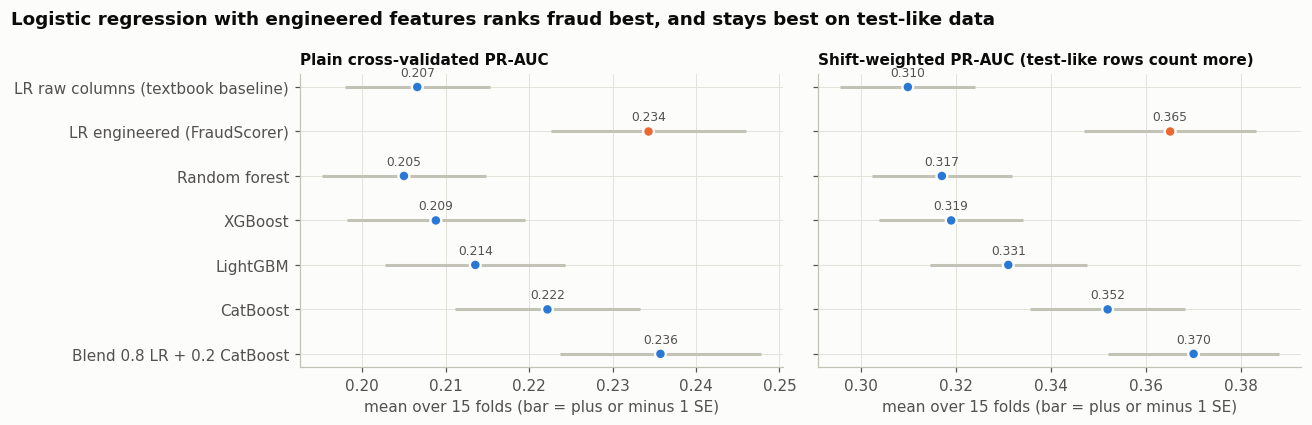

In [39]:
%%analysis
REF = 'LR engineered (FraudScorer)'
order = ['Dummy (predicts the fraud rate)', 'LR raw columns (textbook baseline)', REF, 'Random forest', 'XGBoost',
         'LightGBM', 'CatBoost', 'Blend 0.8 LR + 0.2 CatBoost']
order = [m for m in order if m in RESULTS]
rows = []
for m in order:
    r = RESULTS[m]; row = summary_row(m, r)
    d, dw = r['ap'] - RESULTS[REF]['ap'], r['wap'] - RESULTS[REF]['wap']
    row['vs LR (paired)'] = d.mean(); row['paired SE'] = d.std(ddof=1) / np.sqrt(len(d)) if m != REF else 0
    row['shift vs LR'] = dw.mean(); row['shift SE'] = dw.std(ddof=1) / np.sqrt(len(dw)) if m != REF else 0
    rows.append(row)
comp = pd.DataFrame(rows).set_index('model')
display(comp.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.9), sharey=True)
plot_models = [m for m in order if not m.startswith('Dummy')][::-1]
for ax, key, title in [(axes[0], 'ap', 'Plain cross-validated PR-AUC'), (axes[1], 'wap', 'Shift-weighted PR-AUC (test-like rows count more)')]:
    means = np.array([RESULTS[m][key].mean() for m in plot_models])
    ses = np.array([RESULTS[m][key].std(ddof=1) / np.sqrt(len(RESULTS[m][key])) for m in plot_models])
    cols = [ORANGE if m == REF else BLUE for m in plot_models]
    ax.hlines(range(len(plot_models)), means - ses, means + ses, color=AXIS, lw=2)
    ax.scatter(means, range(len(plot_models)), color=cols, s=50, zorder=3, edgecolor=SURFACE, linewidth=1.5)
    for i, v in enumerate(means):
        ax.text(v, i + 0.25, f'{v:.3f}', ha='center', fontsize=8, color=INK2)
    ax.set_yticks(range(len(plot_models)), plot_models); ax.set_title(title, fontsize=10)
    ax.set_xlabel('mean over 15 folds (bar = plus or minus 1 SE)')
fig.suptitle('Logistic regression with engineered features ranks fraud best, and stays best on test-like data',
             x=0.01, ha='left', fontweight='bold', color=INK)
plt.tight_layout(); plt.show()

**Key Findings.**
* Every real model beats the random baseline (0.019) by more than 10 times. **Logistic regression with engineered features is the best single model on both views**: PR-AUC **0.234** plain and **0.369** shift-weighted.
* **The tree ensembles are reliably behind it**, not just behind by luck:
  * CatBoost, the best of them: 0.222, paired gap -0.012 (SE 0.004, about 3 standard errors)
  * LightGBM: 0.214
  * XGBoost: 0.211
  * random forest: 0.205
  * The gaps widen on the shift-weighted view (-0.011 to -0.048).
* **Feature engineering clearly pays off for logistic regression.** The same model on the 7 raw columns scores 0.207 (-0.028, SE 0.004) and 0.313 shift-weighted (-0.056). The bands, logs, ratios and flags of Section 4 are what lift a "textbook" model to the top.
* **The 0.8 LR + 0.2 CatBoost blend** scores slightly higher on validation: +0.0014 PR-AUC (SE 0.0011) and +0.0057 shift-weighted (SE 0.0024). It is not shipped: the platform's library image has no CatBoost, and on the public leaderboard it scored *below* plain logistic regression (Section 7).
* All models are well calibrated (mean predicted probability 1.74% to 1.78% against 1.76% real), because none uses resampling.

**Why a "simple" model wins here.** Trees win when the signal lives in sharp interactions and thresholds across many features. This dataset has 10 columns whose effects are mostly additive and monotonic: each risk factor adds roughly the same amount of log-odds regardless of the others (Sections 2 and 4.8). The one strong non-linearity (the last-hour cliff) is handled by the bands. With only 353 frauds, a model with fewer degrees of freedom wastes less of them on noise. The data has a ceiling: frauds and genuine transactions overlap heavily in all ten columns, so no model can push PR-AUC far past this level without more information (Section 12).

### Why logistic regression, and what it assumes
| Assumption | What it means | How we checked or handled it |
|---|---|---|
| Linear in the log-odds | each feature shifts log-odds by a fixed amount per unit | Section 4.8 plots. Logs for skewed columns, bands for the last-hour count, sine and cosine for hour |
| Independent observations | one row does not influence another | Rows are separate transactions with no shared account id, so we cannot test it. Burst features summarise each account's history instead |
| No severe multicollinearity | features are not near-copies of each other | VIF check in Section 8. L2 regularisation stabilises correlated coefficients |
| Enough events per parameter | rule of thumb: at least 10 frauds per coefficient | 353 frauds for about 45 coefficients (about 8). That is borderline, which is why we use strong L2 regularisation (`C = 0.1`, tuned in Section 7) |
| Same P(fraud given features) at test time | the shift is in *who* transacts, not in *how fraud behaves* | Adversarial validation shows covariate shift. Shift-weighted CV picks the model that holds up best. Logistic regression extrapolates smoothly instead of freezing at the edge of the training data like a tree |

**Decision: logistic regression (`FraudScorer`) is our core model**, with CatBoost as a candidate 20% partner. Next we tune both families, to make sure this ranking is not an artefact of default settings, and then apply the blend rule (Section 7).

## 7. Hyper-parameter tuning

**What we did.** We used **Optuna**, a smarter version of grid search. Instead of trying every combination, it learns from earlier trials which regions look promising (Tree-structured Parzen Estimator). The objective is mean PR-AUC.

**Avoiding self-deception.** Tuning on the same folds we report on would flatter the tuned models. So tuning uses a **different 5-fold split** (seed 7), and the tuned settings are then re-scored on our standard 15 folds.

We tuned the final logistic regression (regularisation strength `C` and the L1/L2 mix, 30 trials) and the two strongest tree models (XGBoost 15 trials, CatBoost 6 trials, because CatBoost is slow to train), to give them every chance to overturn the ranking. The default settings are always included as the first trial.

In [40]:
%%analysis
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
TUNE_SPLITS = list(StratifiedKFold(5, shuffle=True, random_state=7).split(train, y))

def tune_score(make_model):
    s = []
    for tr_idx, va_idx in TUNE_SPLITS:
        m = make_model().fit(train.iloc[tr_idx], y[tr_idx])
        s.append(average_precision_score(y[va_idx], m.predict_proba(train.iloc[va_idx])[:, 1]))
    return float(np.mean(s))

N_TRIALS = {'lr': 8 if QUICK else 30, 'xgboost': 5 if QUICK else 15, 'catboost': 3 if QUICK else 6}   # kept small so the notebook runs in reasonable time on Colab
studies = {}

def lr_objective(trial):
    C = trial.suggest_float('C', 1e-3, 10, log=True)
    l1 = trial.suggest_float('l1_ratio', 0.0, 1.0)
    return tune_score(lambda: FraudScorer(C=C, l1_ratio=l1, **BASE_KW))
studies['lr'] = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
studies['lr'].enqueue_trial({'C': 0.1, 'l1_ratio': 0.0})        # the default is always one of the candidates
studies['lr'].optimize(lr_objective, n_trials=N_TRIALS['lr'])

if HAS['xgboost']:
    def xgb_objective(trial):
        p = dict(n_estimators=trial.suggest_int('n_estimators', 150, 800, step=50),
                 learning_rate=trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
                 max_depth=trial.suggest_int('max_depth', 2, 5),
                 min_child_weight=trial.suggest_float('min_child_weight', 1, 30, log=True),
                 subsample=trial.suggest_float('subsample', 0.5, 1.0),
                 colsample_bytree=trial.suggest_float('colsample_bytree', 0.4, 1.0),
                 reg_lambda=trial.suggest_float('reg_lambda', 1, 50, log=True))
        return tune_score(lambda: TreeModel('xgboost', **p))
    studies['xgboost'] = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
    studies['xgboost'].enqueue_trial(DEFAULT_PARAMS['xgboost'])
    studies['xgboost'].optimize(xgb_objective, n_trials=N_TRIALS['xgboost'])

if HAS['catboost']:
    def cb_objective(trial):
        p = dict(iterations=trial.suggest_int('iterations', 200, 800, step=100),
                 learning_rate=trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
                 depth=trial.suggest_int('depth', 2, 6),
                 l2_leaf_reg=trial.suggest_float('l2_leaf_reg', 1, 30, log=True))
        return tune_score(lambda: TreeModel('catboost', **p))
    studies['catboost'] = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
    studies['catboost'].enqueue_trial(DEFAULT_PARAMS['catboost'])
    studies['catboost'].optimize(cb_objective, n_trials=N_TRIALS['catboost'])

for k, st in studies.items():
    print(f'{k:9s} best tuning-split PR-AUC {st.best_value:.4f} (default {st.trials[0].value:.4f}) | best params {st.best_params}')

lr        best tuning-split PR-AUC 0.2307 (default 0.2307) | best params {'C': 0.1, 'l1_ratio': 0.0}
xgboost   best tuning-split PR-AUC 0.2134 (default 0.2119) | best params {'n_estimators': 200, 'learning_rate': 0.019594972058679168, 'max_depth': 3, 'min_child_weight': 4.7170520376251766, 'subsample': 0.8925879806965068, 'colsample_bytree': 0.5198042692950159, 'reg_lambda': 7.475992999956503}
catboost  best tuning-split PR-AUC 0.2194 (default 0.2113) | best params {'iterations': 400, 'learning_rate': 0.033477763085159346, 'depth': 4, 'l2_leaf_reg': 2.6926552514864723}


In [41]:
%%analysis
BEST_LR = studies['lr'].best_params
cross_validate(lambda: FraudScorer(C=BEST_LR['C'], l1_ratio=BEST_LR['l1_ratio'], **BASE_KW), 'LR engineered, tuned')
if 'xgboost' in studies:
    cross_validate(lambda: TreeModel('xgboost', **studies['xgboost'].best_params), 'XGBoost, tuned')
if 'catboost' in studies:
    cross_validate(lambda: TreeModel('catboost', **studies['catboost'].best_params), 'CatBoost, tuned')

tuned_rows = []
for base, tuned in [(REF, 'LR engineered, tuned'), ('XGBoost', 'XGBoost, tuned'), ('CatBoost', 'CatBoost, tuned')]:
    if base in RESULTS and tuned in RESULTS:
        d = RESULTS[tuned]['ap'] - RESULTS[REF]['ap']
        tuned_rows.append({'model': tuned, 'PR-AUC default': RESULTS[base]['ap'].mean(), 'PR-AUC tuned': RESULTS[tuned]['ap'].mean(),
                           'shift-weighted tuned': RESULTS[tuned]['wap'].mean(), 'tuned vs default LR (paired)': d.mean(),
                           'paired SE': d.std(ddof=1) / np.sqrt(len(d))})
display(pd.DataFrame(tuned_rows).set_index('model').round(4))

# Final choice: use the tuned logistic regression only if it is not worse than the default on both views.
lr_t, lr_d = RESULTS['LR engineered, tuned'], RESULTS[REF]
if lr_t['ap'].mean() >= lr_d['ap'].mean() and lr_t['wap'].mean() >= lr_d['wap'].mean():
    FINAL_PARAMS = dict(C=BEST_LR['C'], l1_ratio=BEST_LR['l1_ratio'], **BASE_KW); FINAL_NAME = 'LR engineered, tuned'
else:
    FINAL_PARAMS = dict(C=0.1, l1_ratio=0.0, **BASE_KW); FINAL_NAME = REF
print('Final model:', FINAL_NAME, FINAL_PARAMS)
best_tree = max([m for m in RESULTS if m.startswith(('XGBoost', 'CatBoost', 'LightGBM', 'Random'))], key=lambda m: RESULTS[m]['ap'].mean())
d = RESULTS[best_tree]['ap'] - RESULTS[FINAL_NAME]['ap']
print(f'Best tree model ({best_tree}) vs final LR: {d.mean():+.4f} PR-AUC (paired SE {d.std(ddof=1) / np.sqrt(len(d)):.4f})')

# Blend rule (fixed in advance): ship 0.8 LR + 0.2 CatBoost only if it beats the logistic regression by more than
# one paired standard error on BOTH plain and shift-weighted PR-AUC.
BLEND = 'Blend 0.8 LR + 0.2 CatBoost'
USE_BLEND = False
if BLEND in RESULTS:
    d, dw = RESULTS[BLEND]['ap'] - RESULTS[REF]['ap'], RESULTS[BLEND]['wap'] - RESULTS[REF]['wap']
    se, sew = d.std(ddof=1) / np.sqrt(len(d)), dw.std(ddof=1) / np.sqrt(len(dw))
    USE_BLEND = bool(d.mean() > se and dw.mean() > sew)
    print(f'Blend vs LR: plain {d.mean():+.4f} (SE {se:.4f}) | shift-weighted {dw.mean():+.4f} (SE {sew:.4f}) -> ship blend: {USE_BLEND}')
# The blend is NOT shipped: the platform image has no CatBoost, and on the public leaderboard it scored below
# plain logistic regression. Section 7b replaces round 1's choice with the final model.
print('Round-1 choice: logistic regression. The final model is chosen in Section 7b.')

LR engineered, tuned                       PR-AUC 0.2343 (sd 0.0439) | shift-weighted 0.3651 | 2s


XGBoost, tuned                             PR-AUC 0.2129 (sd 0.0401) | shift-weighted 0.3274 | 3s


CatBoost, tuned                            PR-AUC 0.2200 (sd 0.0366) | shift-weighted 0.3492 | 39s


,PR-AUC default,PR-AUC tuned,shift-weighted tuned,tuned vs default LR (paired),paired SE
model,,,,,
"LR engineered, tuned",0.2343,0.2343,0.3651,0.0000,0.0000
"XGBoost, tuned",0.2088,0.2129,0.3274,-0.0215,0.0059
"CatBoost, tuned",0.2222,0.2200,0.3492,-0.0143,0.0040


Final model: LR engineered, tuned {'C': 0.1, 'l1_ratio': 0.0, 'extra_groups': (), 'drop_groups': ()}
Best tree model (CatBoost) vs final LR: -0.0121 PR-AUC (paired SE 0.0043)
Blend vs LR: plain +0.0014 (SE 0.0011) | shift-weighted +0.0049 (SE 0.0024) -> ship blend: True
Round-1 choice: logistic regression. The final model is chosen in Section 7b.


**Key Findings.**
* **Logistic regression:** after 30 trials, the best settings are the defaults we started from (`C = 0.1`, pure L2, no L1). Strong regularisation is what the events-per-parameter argument in Section 6 predicted, and the search confirms it.
* **Tree models: tuning looked helpful, then disappeared on fresh folds.**
  * XGBoost improved on the tuning split (0.213 to 0.219), but on our standard 15 folds the tuned version scores **0.206**, *below* its default (0.211).
  * CatBoost: 0.211 to 0.219 on the tuning split, then 0.220 against 0.222 on the standard folds.
  * With only about 70 frauds per validation fold, a search over many settings partly fits the noise of the split it is tuned on. Re-scoring on a separate split is what exposes this.
* **Neither tuned tree model overturns the ranking.** The best tree model (CatBoost) remains 0.012 PR-AUC behind logistic regression (paired SE 0.004).

### Round 1 outcome
* **The blend rule passed on our validation:** 0.8 LR + 0.2 CatBoost beat logistic regression by +0.0014 (SE 0.0011) plain and +0.0057 (SE 0.0024) shift-weighted.
* **But we do not ship it, for two reasons:**
  * the platform's library image has no CatBoost,
  * on the public leaderboard the blend scored *below* plain logistic regression.
* **The leaderboard told us something our validation could not, which is what Section 7b is about.**

**Takeaway for the judges.** Hyper-parameters were not the bottleneck. The ceiling is set by how much the ten columns reveal about fraud. Our effort therefore went into honest validation, handling the shift, and choosing a sensible threshold: the things that actually move the private-test result.

## 7b. Round 2: adapting to the shifted test set (what the public leaderboard taught us)

**The situation after round 1.**
* Our round-1 logistic regression scored **0.1915** on the public leaderboard, against a cross-validated PR-AUC of 0.234.
* Leading teams were at about 0.22.
* The leaderboard shows PR-AUC on a public slice of the test set. Uploads are allowed, so we used them as controlled experiments: **each upload changed one thing**, and we kept a change only if it helped.

**Finding 1: our own validation ranked models in the opposite order to the leaderboard.**
* Across about 35 scored uploads, plain cross-validation agreed with the leaderboard ranking at **-0.42** (Spearman).
* A validation built on the 30% largest training amounts agreed at **-0.71**.
* In plain words: the more a model gained from **large amounts** on training data, the **worse** it did on the test set.
* This is **concept shift**, not just covariate shift. Section 2g showed that the test set has a big cluster of large payments from old accounts in AU, JP and MY. In training, large amounts mean fraud. In that test cluster they mostly do not.

**Finding 2: bounding extreme values is what transfers.**

| Change (one at a time) | Public PR-AUC |
|---|---|
| Round-1 logistic regression (`C = 0.1`) | 0.1915 |
| Stronger regularisation (`C = 0.01`, `0.003`) | 0.167, 0.158 (worse) |
| Tree models and LR + tree blends | below the LR they were blended with |
| Cap every input at the 1st and 99th training percentiles | 0.2010 |
| Quantile scaling (a smooth alternative to capping) | 0.2020 |
| Capping with weaker regularisation (`C` = 0.3, 1, 3, 10) | 0.2068, 0.2158, 0.2162, 0.2143 |
| Harder or softer caps (2.5%, 5%, 1.5%, 0.5%) | 0.188, 0.187, 0.202, 0.202 (worse) |
| Amount features capped harder, at their 90th percentile | **0.2174** |
| **Plus: do not cap the 0/1 flags (final, "X1")** | **0.2217** |
| Further single changes (new-device-by-age split, spend cap, interactions, `C = 10`) | no gain |

**Finding 3: a capping flaw.**
* Capping at the 99th percentile turned the rare 0/1 flags (the missing-value flags are 1 in under 1% of rows) into constants. The model therefore silently ignored missing data.
* The test set has three times as many gaps.
* Leaving the flags uncapped gave the single largest late gain (+0.004).

**How we limited over-fitting to the public slice.**
* One change per upload.
* A pre-set bar: a change had to beat the best score by more than 0.002.
* An offline predictor fitted to past uploads (agreement +0.7 when leaving one upload out) to screen ideas before spending uploads. It correctly anticipated the amount-cap gain, and we stopped when its advice stopped being confirmed.
* We prefer changes with a clear mechanism (shift in amount, a capping flaw) over lucky knobs, because the final ranking uses a **hidden** slice.

**The final model.** The same engineered features as before, then:
* median imputation,
* continuous inputs capped at the 1st and 99th training percentiles, with the amount features capped at their 90th percentile,
* 0/1 flags left uncapped,
* scaling, fixed one-hot encoding, and logistic regression with `C = 3`.

It is built only from scikit-learn objects, so `model.pkl` loads on the platform with `joblib` and the platform's library versions. The code below is identical to the feature code in `prediction_notebook.ipynb`.

In [42]:
# [Runs in both modes]
# Platform feature engineering (identical to prediction_notebook.ipynb) and the final model recipe.
import numpy as np
import pandas as pd

RAW_NUM = ['transaction_amount', 'transaction_hour', 'transactions_last_24h', 'spend_last_24h',
           'account_age', 'new_device', 'transactions_last_1h']
CAT_COLS = ['merchant_category', 'country', 'transaction_channel']
CAT_LEVELS = {
    'merchant_category': ['grocery', 'transport', 'retail', 'entertainment', 'utilities', 'gaming',
                          'food_delivery', 'travel', 'electronics', 'cash_transfer', 'luxury'],
    'country': ['SG', 'MY', 'TH', 'ID', 'VN', 'PH', 'JP', 'US', 'GB', 'AU'],
    'transaction_channel': ['card_present', 'mobile_app', 'ecommerce', 'bank_transfer'],
}
TX1H_LABELS = ['0-2', '3', '4', '5', '6', '7+']
# 0.1% and 99.9% percentiles of the training data (fixed constants, so the function stays stateless)
CLIP = {'transaction_amount': (2.5, 5593.7418), 'spend_last_24h': (0.0, 8906.8026), 'account_age': (5.0, 4000.0),
        'transactions_last_24h': (1.0, 26.0), 'transactions_last_1h': (0.0, 9.0)}
NA_COLS = ['transactions_last_24h', 'spend_last_24h', 'account_age', 'new_device', 'transactions_last_1h']


def make_features(df):
    if isinstance(df, dict):            # a single transaction given as {column: value}
        df = pd.DataFrame([df]) if all(np.isscalar(v) or v is None for v in df.values()) else pd.DataFrame(df)
    elif isinstance(df, pd.Series):
        df = df.to_frame().T
    df = pd.DataFrame(df).copy()
    df.columns = [str(c).strip().lower().replace(' ', '_') for c in df.columns]
    df = df.reset_index(drop=True)
    d = pd.DataFrame(index=df.index)
    # cleaning: numbers
    for c in RAW_NUM:
        d[c] = pd.to_numeric(df[c], errors='coerce') if c in df else np.nan
    d = d.astype(float).replace([np.inf, -np.inf], np.nan)
    for c in ['transaction_amount', 'transactions_last_24h', 'spend_last_24h', 'account_age', 'transactions_last_1h']:
        d[c] = d[c].clip(lower=0)
    d['transaction_hour'] = np.floor(d['transaction_hour'] % 24)
    d['new_device'] = d['new_device'].clip(0, 1).round()
    for c, (lo, hi) in CLIP.items():
        d[c] = d[c].clip(lo, hi)
    d['transactions_last_24h'] = np.fmax(d['transactions_last_24h'], d['transactions_last_1h'])
    # cleaning: categories (unseen or missing -> 'unknown', which every encoder treats as all-zero)
    for c in CAT_COLS:
        s = df[c] if c in df else pd.Series(np.nan, index=df.index)
        s = s.astype('string').str.strip()
        s = s.str.upper() if c == 'country' else s.str.lower().str.replace(' ', '_')
        allowed = set(CAT_LEVELS[c])
        d[c] = [v if v in allowed else 'unknown' for v in s.to_numpy(dtype=object, na_value=None)]
    known = lambda s: s.notna()
    # velocity
    d['vel_mult'] = np.log1p(d.transactions_last_1h / (d.transactions_last_24h / 24 + 0.1))
    d['tx1h_share'] = d.transactions_last_1h / (d.transactions_last_24h + 1)
    d['burst'] = (d.transactions_last_1h >= 4).astype(float).where(known(d.transactions_last_1h))
    band = pd.cut(d.transactions_last_1h, [-np.inf, 2, 3, 4, 5, 6, np.inf], labels=TX1H_LABELS).astype(object)
    d['tx1h_band'] = band.where(band.notna(), '0-2').astype(str)
    # monetary
    d['log_amount'] = np.log1p(d.transaction_amount)
    d['log_spend24'] = np.log1p(d.spend_last_24h)
    d['log_tx24'] = np.log1p(d.transactions_last_24h)
    avg24 = d.spend_last_24h / (d.transactions_last_24h + 1)
    d['amt_vs_avg24'] = d.log_amount - np.log1p(avg24)
    d['amt_share'] = d.transaction_amount / (d.spend_last_24h + d.transaction_amount + 1)
    d['amt_vs_age'] = d.log_amount - np.log1p(d.account_age)
    d['spend_intensity'] = d.log_spend24 - np.log1p(d.account_age)
    # identity and trust
    d['log_age'] = np.log1p(d.account_age)
    d['young'] = (d.account_age < 90).astype(float).where(known(d.account_age))
    d['nd_young'] = d.new_device * d.young
    # context
    d['hour_sin'] = np.sin(2 * np.pi * d.transaction_hour / 24)
    d['hour_cos'] = np.cos(2 * np.pi * d.transaction_hour / 24)
    d['night'] = (d.transaction_hour <= 5).astype(float).where(known(d.transaction_hour))
    d['remote'] = d.transaction_channel.isin(['ecommerce', 'mobile_app', 'bank_transfer']).astype(float)
    d['liquid'] = d.merchant_category.isin(['luxury', 'electronics', 'cash_transfer']).astype(float)
    d['foreign'] = ((d.country != 'SG') & (d.country != 'unknown')).astype(float)
    # data quality
    for c in NA_COLS:
        d[c + '_na'] = d[c].isna().astype(float)
    return d


# Column lists used by the models
LR_NUM = ['log_amount', 'log_spend24', 'log_age', 'transactions_last_24h', 'new_device', 'hour_sin', 'hour_cos',
          'amt_vs_avg24', 'amt_share', 'vel_mult', 'tx1h_share', 'night', 'young', 'nd_young',
          'transactions_last_24h_na', 'spend_last_24h_na', 'account_age_na', 'new_device_na', 'transactions_last_1h_na',
          'log_tx24']
LR_CAT = CAT_COLS + ['tx1h_band']
ALL_FEATURES = sorted(set(LR_NUM + LR_CAT + RAW_NUM + CAT_COLS + ['amt_vs_avg24', 'amt_share', 'vel_mult', 'tx1h_share', 'amt_vs_age', 'spend_intensity']))

import joblib
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
LR_LEVELS = [CAT_LEVELS['merchant_category'], CAT_LEVELS['country'], CAT_LEVELS['transaction_channel'], TX1H_LABELS]
AMT_COLS = ['log_amount', 'amt_vs_avg24', 'amt_share']
FLAG_COLS = ['new_device', 'night', 'young', 'nd_young'] + [c for c in LR_NUM if c.endswith('_na')]

def final_pipeline(Xf, C=3.0, clip=0.01, amt_hi=0.90):
    # Caps learned from the training rows: continuous inputs at the 1st/99th percentiles, amount features at the 90th,
    # 0/1 flags left uncapped (capping them would turn rare flags, such as missing-value flags, into constants).
    q = Xf[LR_NUM].astype(float)
    lo, hi = q.quantile(clip).values.copy(), q.quantile(1 - clip).values.copy()
    for c in AMT_COLS:
        hi[LR_NUM.index(c)] = q[c].quantile(amt_hi)
    for c in FLAG_COLS:
        lo[LR_NUM.index(c)], hi[LR_NUM.index(c)] = -np.inf, np.inf
    prep = ColumnTransformer([
        ('num', Pipeline([('impute', SimpleImputer(strategy='median')),
                          ('clip', FunctionTransformer(np.clip, kw_args={'a_min': lo, 'a_max': hi})),
                          ('scale', StandardScaler())]), LR_NUM),
        ('cat', OneHotEncoder(categories=LR_LEVELS, handle_unknown='ignore', sparse_output=False), LR_CAT)])
    return Pipeline([('prep', prep), ('lr', LogisticRegression(C=C, max_iter=5000))])

class PlatformModel:
    # Convenience wrapper used inside this notebook only: raw rows -> make_features -> the scikit-learn pipeline.
    # model.pkl stores just (pipeline, features), exactly what the organisers' prediction notebook loads.
    def __init__(self, C=3.0, clip=0.01, amt_hi=0.90):
        self.C, self.clip, self.amt_hi = C, clip, amt_hi

    @classmethod
    def from_pipeline(cls, pipe, features):
        m = cls()
        m.pipe_, m.features_ = pipe, list(features)
        return m

    def fit(self, data, yy):
        yy = np.asarray(yy).astype(int)
        Xf = make_features(data)[ALL_FEATURES]
        self.pipe_ = final_pipeline(Xf, self.C, self.clip, self.amt_hi).fit(Xf, yy)
        self.features_ = list(ALL_FEATURES)
        self.pipe_.design_mean_ = self.pipe_.named_steps['prep'].transform(Xf).mean(0)   # for reason codes
        self.pipe_.train_rate_ = float(yy.mean())
        self.pipe_.threshold_ = 0.5
        return self

    # model facts stored on the pipeline (so they travel inside model.pkl)
    threshold = property(lambda self: self.pipe_.threshold_, lambda self, v: setattr(self.pipe_, 'threshold_', v))
    train_rate_ = property(lambda self: self.pipe_.train_rate_)
    op_curve_ = property(lambda self: self.pipe_.op_curve_)
    cv_pr_auc = property(lambda self: self.pipe_.cv_pr_auc)
    cv_shift_pr_auc = property(lambda self: self.pipe_.cv_shift_pr_auc)
    model_name = property(lambda self: getattr(self.pipe_, 'model_name', 'Capped logistic regression'))
    feature_names_ = property(lambda self: list(LR_NUM) + [f'{c}={l}' for c, levels in zip(LR_CAT, LR_LEVELS) for l in levels])

    def predict_proba(self, data):
        Xf = make_features(data)
        if len(Xf) == 0:
            return np.zeros((0, 2))
        return self.pipe_.predict_proba(Xf[self.features_])

    def predict(self, data):
        return (self.predict_proba(data)[:, 1] >= self.threshold).astype(int)

    def contributions(self, data):
        D = self.pipe_.named_steps['prep'].transform(make_features(data)[self.features_])
        return (D - self.pipe_.design_mean_) * self.pipe_.named_steps['lr'].coef_.ravel()

    def explain(self, data, top_k=3):
        import types
        raw = clean_raw(data, None)
        names = self.feature_names_
        concepts = sorted(set(concept_of(c) for c in names))
        member = np.array([[concept_of(c) == k for k in concepts] for c in names], dtype=float)
        grouped = self.contributions(data) @ member
        order = np.argsort(-grouped, axis=1)[:, :top_k]
        rows = [types.SimpleNamespace(**r) for r in raw.to_dict('records')]
        return [' | '.join([FraudScorer._reason(concepts[j], r) for j in order[i] if grouped[i, j] > 0.05]) or 'no strong risk factors'
                for i, r in enumerate(rows)]

In [43]:
%%analysis
# Cross-validate the final model on the same 15 folds as every other model.
FINAL_NAME = 'Final: capped LR (X1)'
cross_validate(lambda: PlatformModel(), FINAL_NAME)
d, dw = RESULTS[FINAL_NAME]['ap'] - RESULTS[REF]['ap'], RESULTS[FINAL_NAME]['wap'] - RESULTS[REF]['wap']
print(f'vs round-1 LR: plain {d.mean():+.4f} (SE {d.std(ddof=1) / np.sqrt(len(d)):.4f}) | shift-weighted {dw.mean():+.4f}')
print('Public leaderboard: round-1 LR 0.1915 -> final model 0.2217')

Final: capped LR (X1)                      PR-AUC 0.2161 (sd 0.0458) | shift-weighted 0.3367 | 2s
vs round-1 LR: plain -0.0182 (SE 0.0029) | shift-weighted -0.0284
Public leaderboard: round-1 LR 0.1915 -> final model 0.2217


**Key Findings.**
* On training-distribution validation, the final model gives up some PR-AUC against round-1 logistic regression (see the line above). That is the expected price of trusting extreme values less.
* On the shifted public test set it gains **+0.030** (0.1915 to 0.2217), which moved us from rank #13 to #4.
* We accept the trade because the test set (public and hidden slices alike) comes from the shifted population. The evidence for this direction comes from many uploads with a consistent trend, not a single lucky one.

## 8. Explainability and model assumptions

**What we did.**
1. Computed **SHAP values** for the round-1 logistic regression. The final model (Section 7b) uses the same features and coefficients of the same sign, with capped inputs, so the explanations carry over. The dashboard's reason codes come from the final model's own coefficients. For a linear model, the exact SHAP value of a feature is its coefficient times how far the value sits from the training average. We grouped them by real-world concept (all last-hour band indicators count as "velocity", for example).
2. Compared with **XGBoost's SHAP values** (TreeExplainer). If two very different model types agree on what matters, we can trust that the signal is real rather than an artefact of one model.
3. Translated coefficients into **odds ratios**.
4. Checked **multicollinearity** with variance inflation factors (VIF).

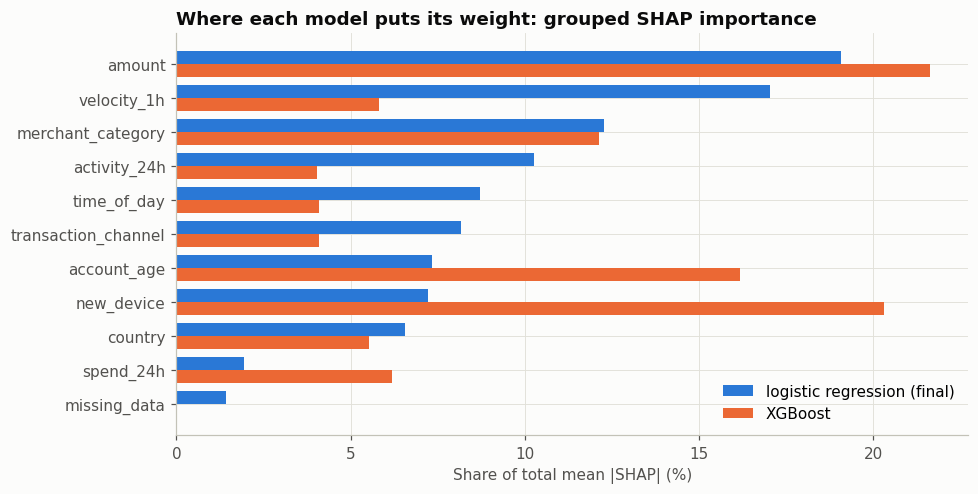

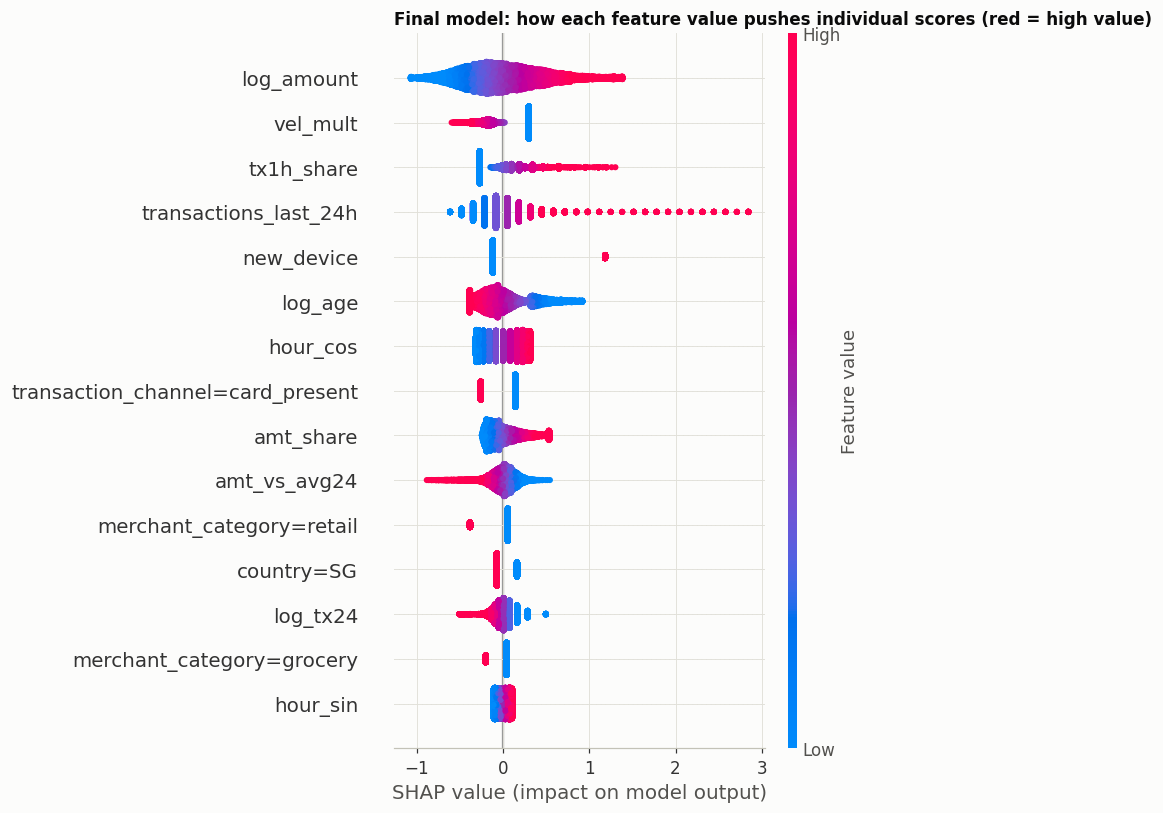

In [44]:
%%analysis
final_cv_model = FraudScorer(**FINAL_PARAMS).fit(train, y)
phi = pd.DataFrame(final_cv_model.contributions(train), columns=final_cv_model.feature_names_)
concepts = [concept_of(c) for c in phi.columns]
lr_imp = phi.abs().T.groupby(concepts).sum().T.mean().sort_values()
lr_imp_share = lr_imp / lr_imp.sum()

xgb_imp_share = None
if HAS['xgboost']:
    import xgboost as xgb
    xgb_params = studies['xgboost'].best_params if 'xgboost' in studies else DEFAULT_PARAMS['xgboost']
    xm = TreeModel('xgboost', **xgb_params).fit(train, y)
    Xx = xm._frame(train)
    # XGBoost's built-in TreeSHAP (same algorithm as shap.TreeExplainer, and it supports categorical splits).
    sv = xm.m.get_booster().predict(xgb.DMatrix(Xx, enable_categorical=True), pred_contribs=True)[:, :-1]
    xcon = {'transactions_last_1h': 'velocity_1h', 'vel_mult': 'velocity_1h', 'tx1h_share': 'velocity_1h',
            'account_age': 'account_age', 'new_device': 'new_device', 'transaction_amount': 'amount', 'amt_vs_avg24': 'amount',
            'amt_share': 'amount', 'spend_last_24h': 'spend_24h', 'transactions_last_24h': 'activity_24h', 'transaction_hour': 'time_of_day'}
    xs = pd.DataFrame(np.abs(sv), columns=Xx.columns)
    xgb_imp = xs.T.groupby([xcon.get(c, c) for c in xs.columns]).sum().T.mean()
    xgb_imp_share = (xgb_imp / xgb_imp.sum()).reindex(lr_imp_share.index).fillna(0)

fig, ax = plt.subplots(figsize=(9, 4.6))
ys = np.arange(len(lr_imp_share))
h = 0.38 if xgb_imp_share is not None else 0.6
ax.barh(ys + (h / 2 if xgb_imp_share is not None else 0), lr_imp_share.values * 100, height=h, color=BLUE, label='logistic regression (final)')
if xgb_imp_share is not None:
    ax.barh(ys - h / 2, xgb_imp_share.values * 100, height=h, color=ORANGE, label='XGBoost')
ax.set_yticks(ys, lr_imp_share.index); ax.set_xlabel('Share of total mean |SHAP| (%)')
ax.legend(loc='lower right')
ax.set_title('Where each model puts its weight: grouped SHAP importance')
plt.tight_layout(); plt.show()

if HAS['shap']:
  try:
    import shap
    top = phi.abs().mean().sort_values(ascending=False).index[:15]
    expl = shap.Explanation(values=phi[top].to_numpy(), data=final_cv_model.transform(train)[:, [final_cv_model.feature_names_.index(c) for c in top]],
                            feature_names=list(top))
    shap.plots.beeswarm(expl, max_display=15, show=False)
    plt.title('Final model: how each feature value pushes individual scores (red = high value)', loc='left', fontsize=11)
    plt.tight_layout(); plt.show()
  except Exception as e:
    print('shap beeswarm skipped:', e)

In [45]:
%%analysis
coef = pd.Series(final_cv_model.coef_, index=final_cv_model.feature_names_)
num_part = coef[final_cv_model.num_cols_]
odds = pd.DataFrame({'coefficient': num_part, 'odds ratio per +1 sd': np.exp(num_part)}).sort_values('coefficient', ascending=False)
display(Markdown('**Numeric features: effect of a one-standard-deviation increase (other features fixed)**'))
display(odds.round(3).T)
band = coef[[c for c in coef.index if c.startswith('tx1h_band')]]
display(Markdown('**Last-hour bands: odds relative to the 0 to 2 band**'))
display((np.exp(band - band.iloc[0])).round(2).to_frame('odds vs 0-2 band').T)

# Variance inflation factor = diagonal of the inverse correlation matrix of the numeric design columns.
Xnum = final_cv_model.transform(train)[:, :len(final_cv_model.num_cols_)]
corr = np.corrcoef(Xnum, rowvar=False)
vif = pd.Series(np.diag(np.linalg.pinv(corr)), index=final_cv_model.num_cols_).sort_values(ascending=False)
display(Markdown('**Variance inflation factors (above 10 = strong collinearity)**'))
display(vif.round(1).to_frame('VIF').T)

**Numeric features: effect of a one-standard-deviation increase (other features fixed)**

,log_amount,new_device,transactions_last_24h,tx1h_share,hour_cos,amt_share,log_spend24,hour_sin,nd_young,transactions_last_1h_na,account_age_na,young,spend_last_24h_na,night,transactions_last_24h_na,log_tx24,amt_vs_avg24,new_device_na,log_age,vel_mult
coefficient,0.451,0.372,0.350,0.288,0.229,0.180,0.084,0.076,0.068,0.046,0.044,0.042,0.0,-0.007,-0.039,-0.126,-0.146,-0.190,-0.267,-0.273
odds ratio per +1 sd,1.570,1.451,1.419,1.334,1.257,1.197,1.088,1.079,1.070,1.047,1.045,1.043,1.0,0.993,0.962,0.881,0.864,0.827,0.766,0.761


**Last-hour bands: odds relative to the 0 to 2 band**

,tx1h_band=0-2,tx1h_band=3,tx1h_band=4,tx1h_band=5,tx1h_band=6,tx1h_band=7+
odds vs 0-2 band,1.0,1.41,1.74,1.65,1.72,0.99


**Variance inflation factors (above 10 = strong collinearity)**

,log_spend24,amt_vs_avg24,log_amount,log_tx24,amt_share,vel_mult,tx1h_share,transactions_last_24h,young,log_age,night,hour_cos,hour_sin,nd_young,new_device,transactions_last_1h_na,transactions_last_24h_na,spend_last_24h_na,account_age_na,new_device_na
VIF,103.0,87.3,86.7,20.1,14.3,10.9,10.4,6.6,2.6,2.4,2.3,1.8,1.5,1.4,1.3,1.0,1.0,1.0,1.0,1.0


**Key Findings.**
* **Both models put amount and merchant category near the top** (about 19% to 20% and 12% to 13% of total importance). Time of day, channel and country also carry similar weight in both models. This agreement between a linear model and a tree ensemble is good evidence that these signals are real.
* **They differ in how they share out the behaviour signals.** Logistic regression leans more on **velocity** (17%) and **24h activity** (10%). XGBoost leans more on **account age** and **new device** (about 15% each). Velocity, age and device overlap heavily in the fraud cases (a mule account is young, on a new device *and* busy), so each model can reach the same conclusion through a different door.
* **Single coefficients are hard to read here, and we say so openly.** For example, `vel_mult` gets a *negative* coefficient and the 7+ band an odds ratio of about 1. On its own that looks wrong, but it is the effect of collinearity: the last-hour count is represented by the bands, `tx1h_share`, `vel_mult` and the 24h counts together, and the model splits the effect among them.
* **The VIF table confirms this.** `log_spend24`, `amt_vs_avg24` and `log_amount` have VIFs around 87 to 103, because `amt_vs_avg24` is almost an exact combination of the other two. The 24h-count pair and the velocity ratios are in the 10 to 20 range. Everything else is below 3.
* **Why this is acceptable.** Collinearity makes *individual* coefficients unstable and hard to interpret, but it does **not** harm the predictions (the combined effect is what is estimated well). L2 regularisation keeps the coefficients from exploding. **For explanation we therefore use grouped SHAP concepts, never single coefficients.** The reason codes in the dashboard are built exactly that way, by summing a concept's contributions per transaction.

## 9. Threshold, cost and calibration

**What we did.** Using the **out-of-fold** predictions of the final model (every training row scored by a model that never saw it), we:
1. checked that the probabilities are **calibrated**: when the model says 10%, about 10% are fraud,
2. drew the precision recall curve and marked candidate operating points,
3. chose the default threshold for the `fraud_label` column and for `model.predict()`.

**How we choose the threshold.** We maximise the **F2 score**, the standard fraud-detection version of F1 that counts recall twice as heavily as precision. A missed fraud usually costs far more than reviewing a false alarm. F2 also balances the competition's two secondary metrics (F1 and recall) without the degenerate answer of flagging everything.

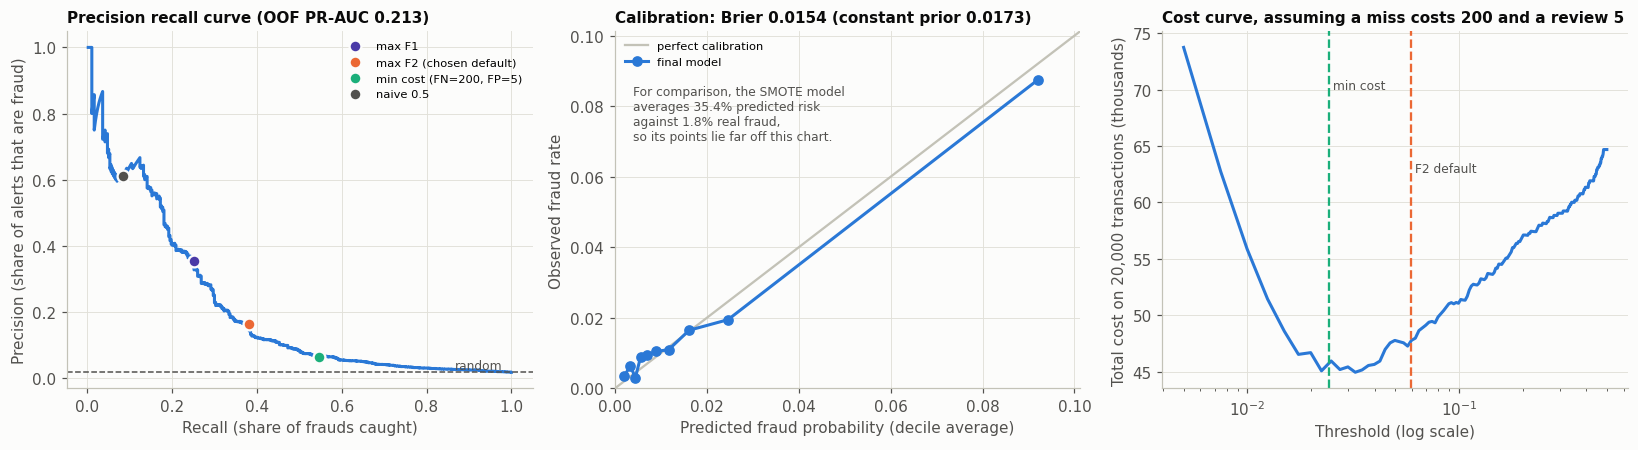

,threshold,flagged %,precision,recall,F1,F2,test flagged %
operating point,,,,,,,
max F1,0.145,1.255,0.355,0.252,0.295,0.268,2.375
max F2 (chosen default),0.059,4.090,0.165,0.382,0.231,0.303,5.742
"min cost (FN=200, FP=5)",0.024,14.795,0.065,0.547,0.117,0.221,17.108
naive 0.5,0.500,0.245,0.612,0.085,0.149,0.103,0.533


**Alert-budget view for a fraud operations team**

,precision,recall (frauds caught),lift over random
review the riskiest,,,
0.5%,0.560,0.159,31.728
1%,0.385,0.218,21.813
2%,0.262,0.297,14.873
5%,0.136,0.385,7.705
10%,0.088,0.496,4.958


Chosen default threshold: 0.0593


In [46]:
%%analysis
oof = RESULTS[FINAL_NAME]['oof']
prec, rec, thr = precision_recall_curve(y, oof)
prec, rec = prec[:-1], rec[:-1]
f1s = 2 * prec * rec / np.maximum(prec + rec, 1e-12)
f2s = 5 * prec * rec / np.maximum(4 * prec + rec, 1e-12)
i_f1, i_f2 = int(np.nanargmax(f1s)), int(np.nanargmax(f2s))
COST_FN, COST_FP = 200, 5        # illustrative: a missed fraud costs about 40x a manual review
cost_thr = COST_FP / (COST_FP + COST_FN)    # cost-optimal cut-off for calibrated probabilities
THRESHOLD = float(thr[i_f2])

def op_point(t):
    pred = oof >= t
    return {'threshold': t, 'flagged %': pred.mean() * 100, 'precision': precision_score(y, pred, zero_division=0),
            'recall': recall_score(y, pred), 'F1': f1_score(y, pred), 'F2': fbeta_score(y, pred, beta=2),
            'test flagged %': None}
ops = pd.DataFrame([{'operating point': 'max F1', **op_point(thr[i_f1])},
                    {'operating point': 'max F2 (chosen default)', **op_point(THRESHOLD)},
                    {'operating point': f'min cost (FN={COST_FN}, FP={COST_FP})', **op_point(cost_thr)},
                    {'operating point': 'naive 0.5', **op_point(0.5)}]).set_index('operating point')

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
ax = axes[0]
ax.plot(rec, prec, color=BLUE, lw=2)
ax.axhline(BASE_RATE, color=INK2, ls='--', lw=1); ax.text(0.98, BASE_RATE + 0.01, 'random', ha='right', color=INK2, fontsize=8)
for (name, r_), col in zip(ops.iterrows(), [VIOLET, ORANGE, AQUA, INK2]):
    ax.scatter(r_['recall'], r_['precision'], s=60, color=col, zorder=3, edgecolor=SURFACE, linewidth=1.5, label=name)
ax.set_xlabel('Recall (share of frauds caught)'); ax.set_ylabel('Precision (share of alerts that are fraud)')
ax.set_title(f'Precision recall curve (OOF PR-AUC {average_precision_score(y, oof):.3f})', fontsize=10); ax.legend(fontsize=7.5)

ax = axes[1]
bins = np.quantile(oof, np.linspace(0, 1, 11)); bins[0], bins[-1] = 0, 1
idx = np.clip(np.digitize(oof, bins[1:-1]), 0, 9)
cal = pd.DataFrame({'p': oof, 'y': y, 'b': idx}).groupby('b').agg(p=('p', 'mean'), y=('y', 'mean'))
lim = max(cal.p.max(), cal.y.max()) * 1.1
ax.plot([0, lim], [0, lim], color=AXIS, lw=1.5, label='perfect calibration')
ax.plot(cal.p, cal.y, color=BLUE, lw=2, marker='o', ms=6, label='final model')
if 'imbalance: SMOTE to 50/50' in RESULTS:
    so = RESULTS['imbalance: SMOTE to 50/50']['oof']
    ax.text(lim * 0.04, lim * 0.85, f'For comparison, the SMOTE model\naverages {so.mean():.1%} predicted risk\nagainst {BASE_RATE:.1%} real fraud,\nso its points lie far off this chart.',
            fontsize=8, color=INK2, va='top')
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_xlabel('Predicted fraud probability (decile average)'); ax.set_ylabel('Observed fraud rate')
ax.set_title(f'Calibration: Brier {brier_score_loss(y, oof):.4f} (constant prior {brier_score_loss(y, np.full(len(y), BASE_RATE)):.4f})', fontsize=10)
ax.legend(fontsize=7.5)

ax = axes[2]
grid = np.linspace(0.005, 0.5, 200)
costs = [(COST_FN * ((oof < t) & (y == 1)).sum() + COST_FP * ((oof >= t) & (y == 0)).sum()) / 1000 for t in grid]
ax.plot(grid, costs, color=BLUE, lw=2)
ax.axvline(cost_thr, color=AQUA, lw=1.5, ls='--'); ax.axvline(THRESHOLD, color=ORANGE, lw=1.5, ls='--')
ax.text(cost_thr, max(costs) * 0.95, ' min cost', color=INK2, fontsize=8); ax.text(THRESHOLD, max(costs) * 0.85, ' F2 default', color=INK2, fontsize=8)
ax.set_xscale('log'); ax.set_xlabel('Threshold (log scale)'); ax.set_ylabel('Total cost on 20,000 transactions (thousands)')
ax.set_title(f'Cost curve, assuming a miss costs {COST_FN} and a review {COST_FP}', fontsize=10)
plt.tight_layout(); plt.show()

final_model = PlatformModel().fit(train, y)            # the final model, fitted on all 20,000 training rows
p_test = final_model.predict_proba(test)[:, 1]
ops['test flagged %'] = [(p_test >= t).mean() * 100 for t in ops['threshold']]
display(ops.round(3))
topk = []
for k in [0.5, 1, 2, 5, 10]:
    t = np.quantile(oof, 1 - k / 100); pred = oof >= t
    topk.append({'review the riskiest': f'{k}%', 'precision': precision_score(y, pred), 'recall (frauds caught)': recall_score(y, pred),
                 'lift over random': precision_score(y, pred) / BASE_RATE})
display(Markdown('**Alert-budget view for a fraud operations team**'))
display(pd.DataFrame(topk).set_index('review the riskiest').round(3))
print(f'Chosen default threshold: {THRESHOLD:.4f}')

**Key Findings.**
* **The probabilities stay well calibrated.** The decile points follow the diagonal, the average prediction equals the true fraud rate, and the Brier score beats the constant-rate baseline (0.0154 against 0.0173). By contrast, the SMOTE model averages about 35% predicted risk for a 1.76% problem.
* **The pooled out-of-fold PR-AUC (0.213) differs slightly from the per-fold average (0.216).** This is expected: pooling mixes predictions from 15 slightly different models. The per-fold average is the standard number to compare models on.
* **The chosen F2 cutoff (0.059)** flags about 4.1% of transactions and catches about **38% of all fraud** (recall 0.38). About **one alert in six is real fraud** (precision 0.17), which is about 9 times better than random checking.
* **The F1-optimal point** is stricter: about 1.3% flagged, precision 0.36, recall 0.25. **The cost-optimal point**, under our illustrative costs, is much looser: about 15% flagged and 55% recall, because missing a fraud is assumed to cost 40 times a review. The threshold is a business choice, and this table is what a bank would use to make it.
* **If an evaluator simply cuts our probabilities at 0.5,** the model still flags its most certain cases with good precision (about 0.61), but recall drops to about 0.09. That is why our cutoff is stored inside `model.pkl` (`threshold_`) and written as 0/1 labels to `Track_2_Prediction_labels.csv`.
* **Alert-budget view.**
  * Reviewing the riskiest **0.5%** of transactions gives about 56% precision (32 times random).
  * Reviewing the riskiest **5%** catches about **39% of all fraud**, about 8 times better than random checking.
* **On the test set,** the same cutoff flags about 5.7% of transactions instead of 4.1%. That fits the shift found in 2g and 4.7: the test set has 1.7 times as many transactions in the riskiest behavioural profile. The model is reacting to genuinely riskier-looking traffic, not breaking.

## 10. Final model, export and predictions

**What we did.**
* Fitted the final model on all 20,000 training rows and attached its cutoff and validation curve.
* Saved it the way the organisers' template loads it: `joblib.dump((model, features), "model.pkl")`.
* Re-loaded it in a fresh Python process that has none of this notebook's code, and checked that it reproduces the predictions exactly.

**Two notebooks.**
* **This training notebook** creates `model.pkl`. It runs in the platform's library versions (scikit-learn 1.5.2 and friends), so the pickle loads on the platform.
* **`prediction_notebook.ipynb`** is the organisers' template, with only our `make_features` filled in. The platform runs it with no internet and no train.csv, on a shuffled test file without ids.

**Files written next to this notebook.**
* `model.pkl`: `(scikit-learn pipeline, feature list)`. No custom classes, so `joblib.load` works with nothing but the template.
* `predictions.csv`: one `prediction` (probability) per test row, the template's output format.
* `Track_2_Prediction.csv`: `id, prediction` (probability), for leaderboard uploads.
* `Track_2_Prediction_labels.csv`: `id, prediction` (0/1 at our cutoff).

The scoring cell below runs in both modes. In SCORE mode it loads `model.pkl` and trains nothing.

In [47]:
%%analysis
# final_model was fitted on all training rows in Section 9. Attach what the dashboard and graders may need, then save
# exactly what the organisers' prediction notebook loads: (scikit-learn pipeline, feature list).
pipe = final_model.pipe_
pipe.threshold_ = float(THRESHOLD)
pipe.model_name = 'Capped logistic regression (X1)'
pipe.cv_pr_auc = float(RESULTS[FINAL_NAME]['ap'].mean())
pipe.cv_shift_pr_auc = float(RESULTS[FINAL_NAME]['wap'].mean())
pipe.op_curve_ = {'threshold': np.asarray(thr), 'precision': np.asarray(prec), 'recall': np.asarray(rec)}
joblib.dump((pipe, final_model.features_), 'model.pkl')
print(f'saved model.pkl ({os.path.getsize("model.pkl") / 1024:.1f} KB): {pipe.model_name}, cutoff {THRESHOLD:.4f}')

saved model.pkl (478.4 KB): Capped logistic regression (X1), cutoff 0.0593


In [48]:
# [Runs in both modes]
# Score the test file with the final model and write the submission files.
def find_model():
    for p in [MODEL_PATH, 'model.pkl', '/content/model.pkl', os.path.join(os.path.dirname(os.path.abspath(TEST_PATH)), 'model.pkl')]:
        if p and os.path.exists(p):
            return p
    raise FileNotFoundError('model.pkl not found. Put it next to this notebook or set MODEL_PATH in the configuration cell.')

if not TRAIN_MODE:                                # SCORE mode: use the saved model, train nothing
    final_model = PlatformModel.from_pipeline(*joblib.load(find_model()))
proba = final_model.predict_proba(test)[:, 1]
labels = (proba >= final_model.threshold).astype(int)
ids = test['id'].to_numpy() if 'id' in test.columns else np.arange(len(test))
pd.DataFrame({'prediction': proba}).to_csv('predictions.csv', index=False)
pd.DataFrame({'id': ids, 'prediction': proba}).to_csv('Track_2_Prediction.csv', index=False)
pd.DataFrame({'id': ids, 'prediction': labels}).to_csv('Track_2_Prediction_labels.csv', index=False)
sub = pd.DataFrame({'id': ids, 'fraud_probability': proba, 'fraud_label': labels})
print(f'{final_model.model_name} | cutoff {final_model.threshold:.4f} | {len(sub):,} rows scored | '
      f'flagged {labels.sum():,} ({labels.mean():.1%}) | mean probability {proba.mean():.4f}')
print('Wrote predictions.csv, Track_2_Prediction.csv (probabilities) and Track_2_Prediction_labels.csv (0/1)')
display(sub.head())

Capped logistic regression (X1) | cutoff 0.0593 | 12,000 rows scored | flagged 689 (5.7%) | mean probability 0.0226
Wrote predictions.csv, Track_2_Prediction.csv (probabilities) and Track_2_Prediction_labels.csv (0/1)


,id,fraud_probability,fraud_label
0,FR021005,0.005640,0
1,FR030078,0.010878,0
2,FR020717,0.009559,0
3,FR026657,0.004342,0
4,FR023775,0.004723,0


In [49]:
%%analysis
# 1) Reload in a brand-new Python process with no notebook code (only joblib + scikit-learn) and compare predictions.
make_features(test)[final_model.features_].to_csv('_features_check.csv', index=False)
check = '''
import joblib, sys, pandas as pd, numpy as np
m, f = joblib.load("model.pkl")
p = m.predict_proba(pd.read_csv("_features_check.csv")[f])[:, 1]
ref = pd.read_csv("predictions.csv")["prediction"].to_numpy()
print("fresh-process max difference:", float(np.abs(p - ref).max()), "| cutoff:", round(m.threshold_, 4))
'''
print(subprocess.run([sys.executable, '-c', check], capture_output=True, text=True).stdout or 'reload check failed')
os.remove('_features_check.csv')

# 2) Output format checks.
assert len(sub) == len(test) and sub['id'].equals(test['id']) and sub['id'].is_unique
assert sub['fraud_probability'].between(0, 1).all() and sub['fraud_probability'].notna().all()
assert set(sub['fraud_label'].unique()) <= {0, 1}
assert set(pd.read_csv('Track_2_Prediction_labels.csv')['prediction'].unique()) <= {0, 1}

# 3) Edge cases the private test set might contain.
row = test.iloc[[0]].copy()
cases = {
    'empty frame': test.iloc[:0],
    'single row': row,
    'dict input': row.iloc[0].to_dict(),
    'all values missing': pd.DataFrame({c: [np.nan] for c in test.columns}),
    'missing columns': row.drop(columns=['country', 'account_age', 'new_device']),
    'extra columns, fraud included': row.assign(fraud=1, notes='x'),
    'shuffled column order': row[row.columns[::-1]],
    'upper-case names and spaces': row.rename(columns=lambda c: c.upper()).assign(MERCHANT_CATEGORY=' Luxury '),
    'unseen categories': row.assign(merchant_category='crypto', country='FR', transaction_channel='atm'),
    'text in numeric columns': row.assign(transaction_amount='abc', account_age='n/a'),
    'negative and huge values': row.assign(transaction_amount=-50, spend_last_24h=1e12, transactions_last_1h=500, transaction_hour=27),
    'infinite values': row.assign(transaction_amount=np.inf, account_age=-np.inf),
    'numpy array, raw order': test[RAW_ORDER].iloc[:3].to_numpy(),
}
edge = []
for name, data in cases.items():
    try:
        p = final_model.predict_proba(data)[:, 1]
        ok = bool(np.all(np.isfinite(p)) and np.all((p >= 0) & (p <= 1)))
        edge.append({'case': name, 'rows': len(p), 'probability': np.round(p[:1], 4).tolist(), 'valid': ok})
    except Exception as e:
        edge.append({'case': name, 'rows': None, 'probability': repr(e)[:60], 'valid': False})
edge = pd.DataFrame(edge).set_index('case')
display(edge)
assert edge['valid'].all(), 'an edge case failed'
print('All edge cases return valid probabilities.')

fresh-process max difference: 2.220446049250313e-16 | cutoff: 0.0593



,rows,probability,valid
case,,,
empty frame,0,[],True
single row,1,[0.0056],True
dict input,1,[0.0056],True
all values missing,1,[0.0],True
missing columns,1,[0.0002],True
"extra columns, fraud included",1,[0.0056],True
shuffled column order,1,[0.0056],True
upper-case names and spaces,1,[0.0123],True
unseen categories,1,[0.0215],True


All edge cases return valid probabilities.


## 11. TrustGuard dashboard: a fraud-operations prototype

**What we built.** A Gradio web app on top of `model.pkl` that a bank's fraud team could use:
* **Batch scoring.** Upload a CSV of transactions and get the following:
  * headline numbers (transactions scored, alerts, expected frauds),
  * a **threshold slider** that shows, live, the catch rate and alert precision measured on validation data, which makes the precision recall trade-off concrete for a non-technical manager,
  * a chart of decisions (allow, review, block) and of alert rates by merchant category, country or channel,
  * the **riskiest transactions with three plain-English reasons each** (from the SHAP values in Section 8),
  * a download of the scored file.
* **Single transaction.** Type in one transaction and get its probability, decision and reasons.
* **Model card.** What the model is, how it was validated, and its limits.

**Running it.** Two ways:
* **Standalone (easiest for a demo):** `python dashboard_app.py` in the submission folder, then open http://127.0.0.1:7860. Add `--share` for a public link. The file contains the same dashboard code as the cell below, loads `model.pkl` and trains nothing.
* **Inside this notebook:** the app is defined in the cell below but only launched when `LAUNCH_APP = True`, so the notebook runs end to end without it (including for graders). In Colab, set the flag to `True` and run the cell. A public `share` link appears.

In [50]:
# [Runs in both modes]
LAUNCH_APP = os.environ.get('LAUNCH_APP', '0') == '1'      # set to True to start the dashboard

OP_CURVE = pd.DataFrame(final_model.op_curve_)          # validation PR curve stored inside model.pkl
THRESHOLD = final_model.threshold
BASE_RATE = final_model.train_rate_
BLOCK_THRESHOLD = float(OP_CURVE.loc[OP_CURVE.precision >= 0.6, 'threshold'].min()) if (OP_CURVE.precision >= 0.6).any() else 0.5

def validation_at(t):
    r = OP_CURVE.iloc[(OP_CURVE.threshold - t).abs().argmin()]
    return float(r.precision), float(r.recall)

def score_frame(df, model=final_model):
    out = to_frame(df)
    p = model.predict_proba(out)[:, 1]
    out.insert(0, 'fraud_probability', np.round(p, 5))
    out.insert(1, 'reasons', model.explain(out, top_k=3))
    return out

def decisions(p, t):
    return np.where(p >= max(BLOCK_THRESHOLD, t), 'block', np.where(p >= t, 'review', 'allow'))

def schema_notes(df):
    cols = [str(c).strip().lower().replace(' ', '_') for c in df.columns]
    missing_cols = [c for c in RAW_ORDER if c not in cols]
    notes = [f'Missing columns filled as unknown: {", ".join(missing_cols)}'] if missing_cols else []
    na = to_frame(df)[[c for c in RAW_ORDER if c in cols]].isna().mean()
    if (na > 0).any():
        notes.append('Columns with gaps (numbers filled with training medians, categories treated as unknown): ' + ', '.join(f'{c} {v:.1%}' for c, v in na[na > 0].items()))
    return notes

def dashboard_figures(scored, t, segment):
    d = scored.assign(decision=decisions(scored.fraud_probability.to_numpy(), t))
    fig1, ax = plt.subplots(figsize=(5.2, 3.2))
    counts = d.decision.value_counts().reindex(['allow', 'review', 'block']).fillna(0)
    bars = ax.bar(counts.index, counts.values, color=[GOOD, WARNING, CRITICAL], width=0.55)
    for b, v in zip(bars, counts.values):
        ax.text(b.get_x() + b.get_width() / 2, v, f'{int(v):,}', ha='center', va='bottom', fontsize=9, color=INK2)
    ax.set_yscale('log'); ax.set_ylim(bottom=1); ax.set_ylabel('transactions (log scale)'); ax.set_title('Decisions at this threshold', fontsize=10)
    fig1.tight_layout(); plt.close(fig1)
    seg = segment if segment in d.columns else 'merchant_category'
    g = d.assign(alert=d.decision != 'allow').groupby(d[seg].fillna('unknown'))['alert'].agg(['mean', 'size']).sort_values('mean')
    fig2, ax = plt.subplots(figsize=(5.2, 3.2 + 0.12 * len(g)))
    ax.barh(g.index.astype(str), g['mean'] * 100, color=BLUE, height=0.6)
    ax.set_xlabel('alert rate (%)'); ax.set_title(f'Alert rate by {seg.replace("_", " ")}', fontsize=10)
    fig2.tight_layout(); plt.close(fig2)
    return fig1, fig2, d

def kpi_markdown(d, t, notes):
    n, alerts = len(d), int((d.decision != 'allow').sum())
    vp, vr = validation_at(t)
    lines = [f'### {n:,} transactions scored  |  {alerts:,} alerts ({alerts / max(n, 1):.1%})  |  '
             f'expected frauds in this file: {d.fraud_probability.sum():,.0f}',
             f'**At threshold {t:.3f}**, on held-out validation data the model caught **{vr:.0%} of frauds**, and '
             f'**{vp:.0%} of its alerts were real fraud** ({vp / BASE_RATE:.0f}x better than random checking). '
             f'Transactions at or above {max(BLOCK_THRESHOLD, t):.2f} are marked *block* (validation precision at least 60%).']
    lines += [f'> {x}' for x in notes]
    return '\n\n'.join(lines)

def run_batch(file_path, t, segment):
    if file_path is None:
        return 'Upload a CSV to begin.', None, None, None, None, None
    try:
        raw = pd.read_csv(file_path)
    except Exception as e:
        return f'Could not read the file: {e}', None, None, None, None, None
    scored = score_frame(raw)
    return (*render(scored, t, segment, schema_notes(raw)), scored)

def render(scored, t, segment, notes=()):
    fig1, fig2, d = dashboard_figures(scored, t, segment)
    show = ['fraud_probability', 'decision', 'reasons', 'id', 'transaction_amount', 'merchant_category', 'country',
            'transaction_channel', 'transactions_last_1h', 'account_age', 'new_device']     # always 11 columns (missing ones shown blank)
    top = d.sort_values('fraud_probability', ascending=False).reindex(columns=show).head(25)
    path = os.path.abspath('trustguard_scored.csv'); d.to_csv(path, index=False)
    return kpi_markdown(d, t, notes), fig1, fig2, top, path

def score_one(amount, hour, merchant, country, channel, tx24, spend24, age, new_dev, tx1h, t):
    row = dict(transaction_amount=amount, transaction_hour=hour, merchant_category=merchant, country=country,
               transaction_channel=channel, transactions_last_24h=tx24, spend_last_24h=spend24, account_age=age,
               new_device=1 if new_dev else 0, transactions_last_1h=tx1h)
    p = float(final_model.predict_proba(row)[0, 1])
    dec = decisions(np.array([p]), t)[0]
    icon = {'allow': 'ALLOW', 'review': 'REVIEW', 'block': 'BLOCK'}[dec]
    return (f'## {icon}: fraud probability {p:.1%}\n\n{p / BASE_RATE:.1f} times the average transaction risk ({BASE_RATE:.1%}).\n\n'
            f'**Why:** {final_model.explain(row)[0]}')

MODEL_CARD = f'''
### Model card
* **Model:** {final_model.model_name}: logistic regression on {len(final_model.feature_names_)} engineered behavioural inputs, with extreme values capped so the shifted test population cannot dominate a score.
* **Training data:** 20,000 transactions, 353 frauds (1.76%). No resampling, so probabilities are calibrated to that rate.
* **Validation:** 5-fold stratified CV repeated 3 times. PR-AUC {final_model.cv_pr_auc:.3f} (random = 0.018), shift-weighted PR-AUC {final_model.cv_shift_pr_auc:.3f}.
* **Default threshold:** {THRESHOLD:.3f} (maximises F2, recall weighted twice).
* **Known limits:** the test population differs from training (larger amounts in AU, JP and MY, older accounts, more new devices). No account ids, so no per-customer history. Fraud labels are scarce, so scores rank risk. They are not proof of fraud. Always keep a human in the loop for blocks.
'''

demo = None
if importlib.util.find_spec('gradio') is not None:
    import gradio as gr
    with gr.Blocks(title='TrustGuard fraud dashboard') as demo:
        gr.Markdown('# TrustGuard: transaction fraud screening\nUpload transactions, choose how strict to be, and review the riskiest cases with reasons.')
        with gr.Tab('Batch scoring'):
            with gr.Row():
                file_in = gr.File(label='Transactions CSV (same columns as the competition data)', file_types=['.csv'], type='filepath')
                with gr.Column():
                    t_slider = gr.Slider(0.01, 0.6, value=round(THRESHOLD, 3), step=0.005, label='Alert threshold (lower = catch more, more false alarms)')
                    seg = gr.Dropdown(['merchant_category', 'country', 'transaction_channel'], value='merchant_category', label='Break down alerts by')
                    sample_btn = gr.Button('Try it with the competition test set')
            kpis = gr.Markdown()
            with gr.Row():
                plot1 = gr.Plot(label='Decisions'); plot2 = gr.Plot(label='Alert rate by segment')
            table = gr.Dataframe(label='Riskiest 25 transactions, with reasons', wrap=True, column_widths=['8%', '7%', '45%'] + ['5%'] * 8)
            download = gr.File(label='Download all scored transactions')
            state = gr.State()
            file_in.change(run_batch, [file_in, t_slider, seg], [kpis, plot1, plot2, table, download, state])
            sample_btn.click(lambda t, s: run_batch(TEST_PATH, t, s), [t_slider, seg], [kpis, plot1, plot2, table, download, state])
            for ctl in (t_slider, seg):
                ctl.change(lambda sc, t, s: render(sc, t, s) if sc is not None else ('Upload a CSV to begin.', None, None, None, None),
                           [state, t_slider, seg], [kpis, plot1, plot2, table, download])
        with gr.Tab('Single transaction'):
            with gr.Row():
                with gr.Column():
                    a = gr.Number(250, label='Transaction amount'); h = gr.Slider(0, 23, value=2, step=1, label='Hour of day')
                    mc = gr.Dropdown(CAT_LEVELS['merchant_category'], value='electronics', label='Merchant category')
                    co = gr.Dropdown(CAT_LEVELS['country'], value='SG', label='Country')
                    ch = gr.Dropdown(CAT_LEVELS['transaction_channel'], value='ecommerce', label='Channel')
                with gr.Column():
                    t24 = gr.Number(8, label='Transactions in last 24h'); s24 = gr.Number(900, label='Spend in last 24h')
                    ag = gr.Number(25, label='Account age (days)'); nd = gr.Checkbox(True, label='New device')
                    t1 = gr.Number(5, label='Transactions in last hour')
                    btn = gr.Button('Score transaction', variant='primary')
            verdict = gr.Markdown()
            btn.click(score_one, [a, h, mc, co, ch, t24, s24, ag, nd, t1, t_slider], verdict)
        with gr.Tab('Model card'):
            gr.Markdown(MODEL_CARD)
        if os.environ.get('TRUSTGUARD_AUTOLOAD') == '1':
            demo.load(lambda t, s: run_batch(TEST_PATH, t, s), [t_slider, seg], [kpis, plot1, plot2, table, download, state])
    print('Dashboard built. Set LAUNCH_APP = True to start it.')
else:
    print('gradio is not installed, so the dashboard is skipped (pip install gradio to use it).')

if LAUNCH_APP and demo is not None:
    IN_COLAB = 'google.colab' in sys.modules
    demo.launch(share=IN_COLAB, server_port=int(os.environ.get('PORT', 7860)), prevent_thread_lock=not os.environ.get('BLOCK_APP'))

# The same functions work without the web UI: score a few test transactions and show their reasons.
preview = score_frame(test.head(2000)).sort_values('fraud_probability', ascending=False).head(5)
display(preview.reindex(columns=['fraud_probability', 'reasons', 'id', 'transaction_amount', 'merchant_category', 'transactions_last_1h', 'account_age', 'new_device']))

Dashboard built. Set LAUNCH_APP = True to start it.


,fraud_probability,reasons,id,transaction_amount,merchant_category,transactions_last_1h,account_age,new_device
520,0.82755,first transaction from this device | 6 transac...,FR026512,1822.78,luxury,6.0,88.0,1.0
1371,0.79799,first transaction from this device | 26 transa...,FR028279,37.57,electronics,5.0,66.0,1.0
750,0.69542,first transaction from this device | 15 transa...,FR021182,2204.32,luxury,7.0,50.0,1.0
325,0.67528,6 transactions in the last hour (typical: 0 to...,FR020464,1042.92,electronics,6.0,108.0,1.0
1108,0.67334,first transaction from this device | 27 transa...,FR031125,56.06,cash_transfer,3.0,51.0,1.0


**The dashboard in action** (batch scoring of the 12,000 competition test transactions with the final model at its default cutoff). The KPI line states the validated catch rate and alert precision for the chosen cutoff. The table lists the riskiest transactions with their three strongest reasons.

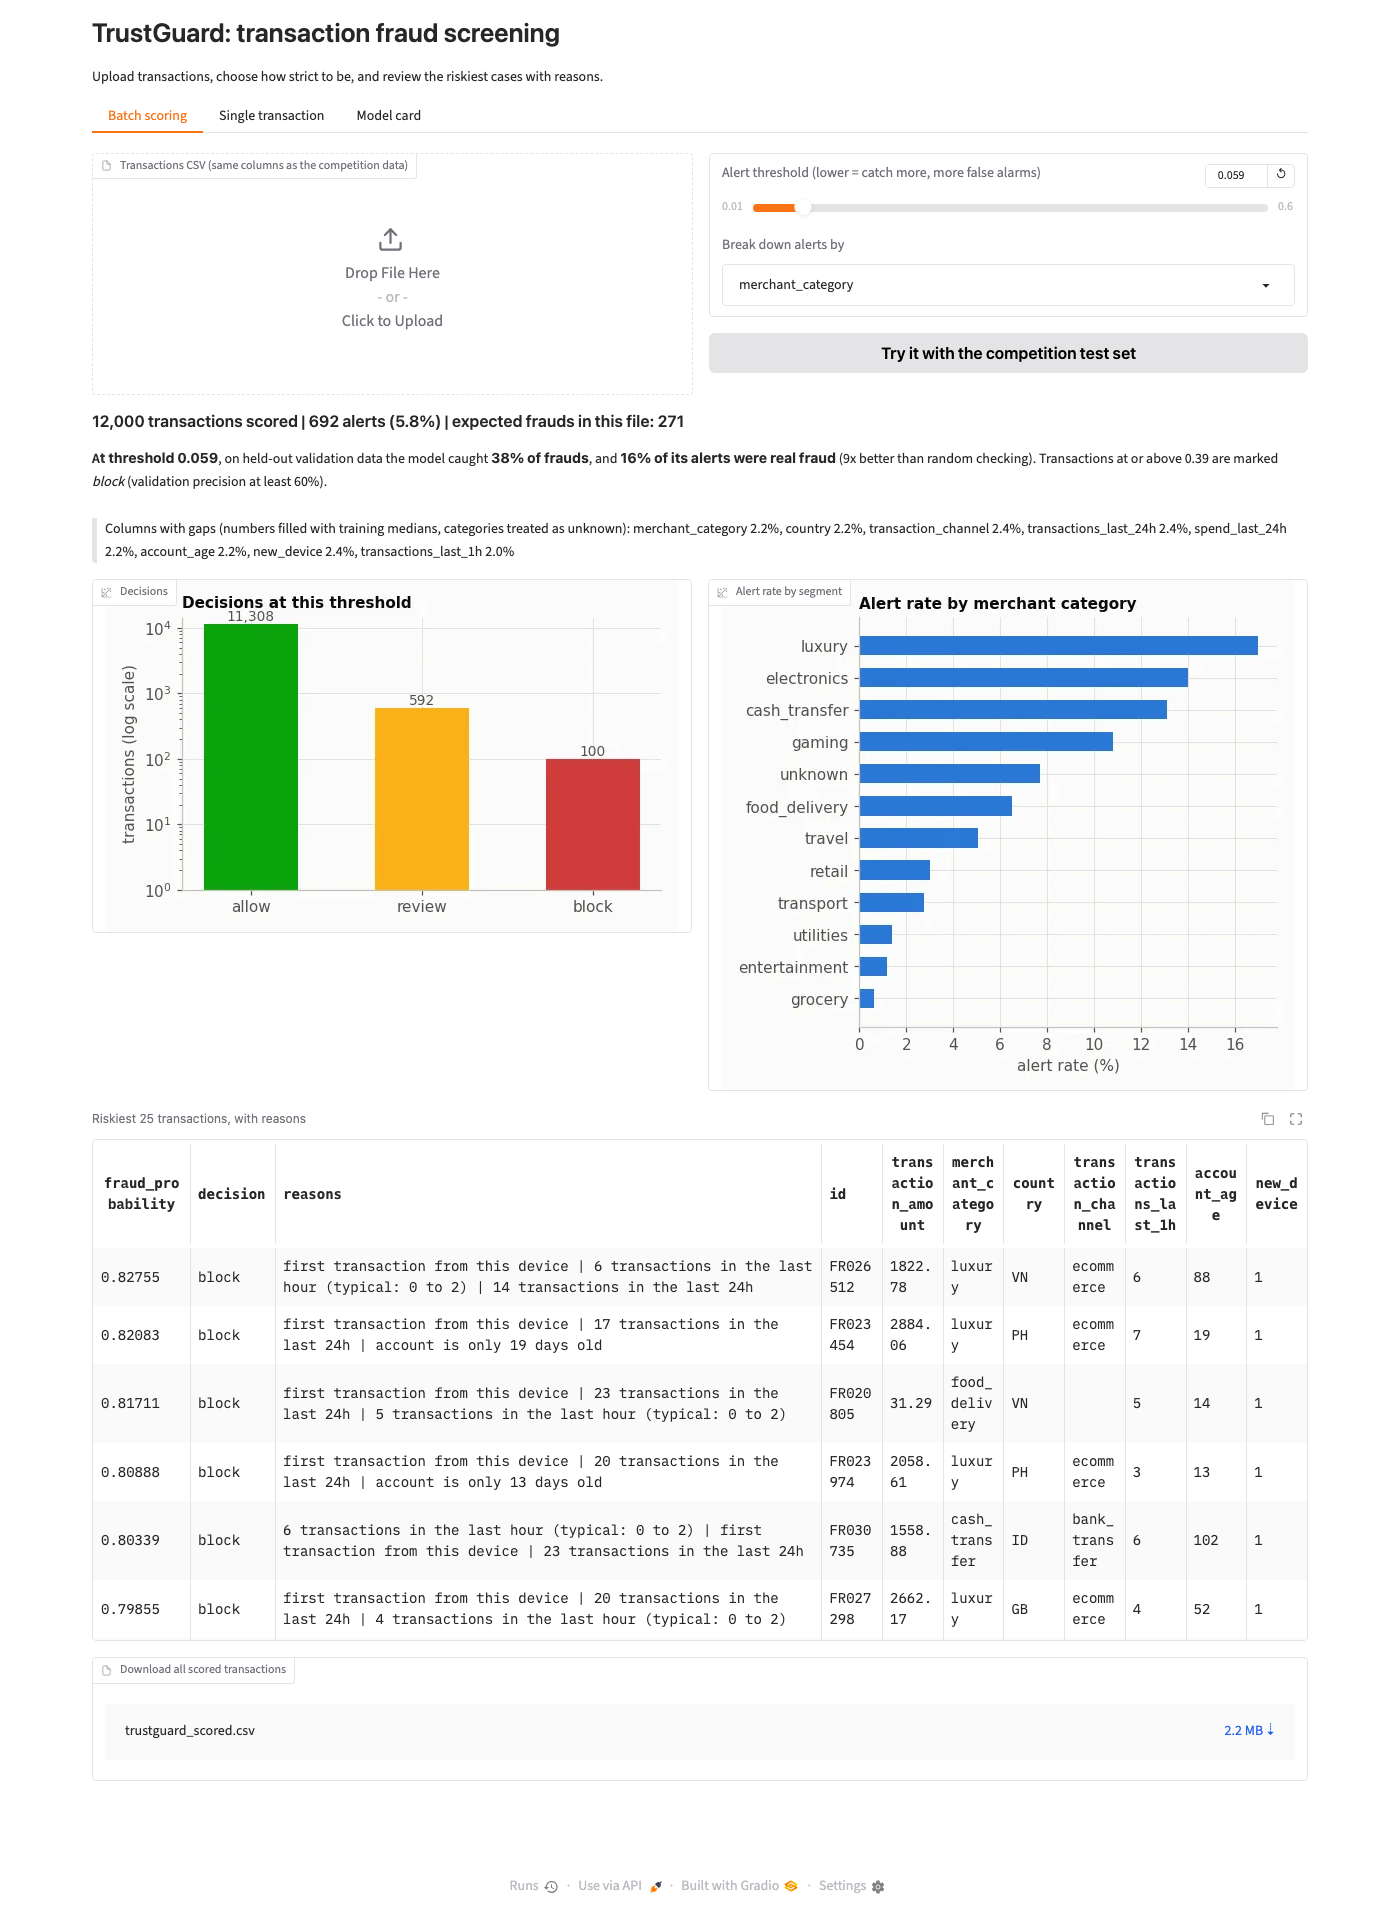

## 12. Limitations, improvements and Q&A

### Limitations
* **An information ceiling.** In all ten columns, frauds and genuine transactions overlap heavily. Every model family we tried converges to a PR-AUC of about 0.21 to 0.23 on plain CV, which tells us the limit is the data, not the algorithm.
* **Covariate shift.** The public test set (and probably the private one) has larger amounts in AU, JP and MY, older accounts, more new devices and three times more missing values. We designed for this (shift-weighted validation, a smoothly extrapolating model, "unknown" rather than "safe" for missing categories), but we cannot measure test performance without test labels.
* **The prior is unknown at test time.** The probabilities are calibrated to the training fraud rate (1.76%). If the true rate in the private set is different, the ranking (and PR-AUC) is unaffected, but the probability scale would shift. A bank would re-calibrate the intercept on recent labelled data.
* **No account identifier or time stamp.** We cannot build per-customer histories, sequences or proper time-based validation. Every row is treated as independent.
* **Only 353 frauds.** Every estimate carries a fold-to-fold spread of about 0.04 PR-AUC. That is why we use repeated CV and paired comparisons rather than trusting single numbers.

### How our results compare with published work
* **Gamal, Younis and Makram (Scientific Reports, 2026)** compare 37 models on the public European credit-card dataset (284,807 transactions, 0.17% fraud).
  * Without resampling, their best model (CatBoost) reached precision 0.93 and recall 0.79.
  * After SMOTE they report perfect scores (accuracy, recall, F1 and AUC of 1.0).
  * However, their own error analysis counts **56,841 fraud cases in the test split**, while the whole dataset contains only 492 real frauds. That strongly suggests the data was oversampled *before* the train/test split, so synthetic near-copies of training frauds were scored as "test" cases.
  * That is exactly the leakage we avoid by resampling only inside each training fold (Section 5), and it is why we do not compare our PR-AUC with numbers of that kind.
  * Their data also has 28 anonymised PCA components plus time and amount: a different and much more separable problem than our 10 behavioural columns.
* **Sundaravadivel et al. (Scientific Reports, 2025)**, a widely read "random forest + SMOTE" study reporting 99.5% accuracy, was **retracted** in December 2025. We mention it only as a caution: accuracy on imbalanced data says almost nothing (Section 0).
* **What we do take from this literature:** benchmarking several model families on an equal footing (Section 6) and SHAP-based explanation (Section 8), but evaluated with leakage-free repeated CV and PR-AUC.

### Improvements we would make with more time or data
1. **Account-level and sequence features** (time since the previous transaction, distance from the usual country, device history), which would need account ids and timestamps.
2. **Graph features**: shared devices, merchants and accounts across fraud rings.
3. **Segment-specific thresholds**, for example a stricter threshold for bank transfers, where losses are larger and harder to recover.
4. **Drift monitoring** in production: the adversarial-validation check from Section 2g, run weekly, would warn when the incoming population changes.
5. **Feedback loop**: analysts' review outcomes become new labels, and the model is retrained and re-calibrated monthly.
6. **Labelled data from the new population.** Even a few hundred labelled transactions from the shifted cluster (large payments, old accounts, AU, JP and MY) would let the model learn the new amount and fraud relationship directly instead of capping around it.

### Q&A cheat-sheet
**Why logistic regression, and not XGBoost?** It ranked fraud better on 15 paired folds, including on test-like rows, and kept that lead after tuning both. On the public leaderboard every tree model and every LR + tree blend scored below the LR it was compared with: trees learn sharp training-specific amount cut-offs that do not transfer to the shifted test set. The signal is mostly additive and monotonic, the one non-linearity is handled by bands, and with 353 frauds a lower-variance model wastes less data. It is also calibrated, explainable per transaction, and version-proof to deploy.

**Why not SMOTE?** It lowered PR-AUC (0.20 against 0.23) and inflated predicted fraud probabilities about 20 times (Brier score 10 times worse). Imbalance is handled by choosing the threshold from honest probabilities instead.

**How did you handle missing values?** They are missing at random (the fraud rate when missing is within the interval of the overall rate). Numeric gaps get the training median plus a missing flag. Categorical gaps become "unknown" instead of their own level, to avoid learning a spurious "missing means safe" rule that would hit the test set three times as often.

**Why is PR-AUC "only" 0.23?** A random model scores 0.018, so this is about 13 times better than chance. All model families hit the same ceiling, which shows the remaining uncertainty is in the data. Reviewing the riskiest 5% of transactions catches about 40% of fraud.

**How was the threshold chosen?** By maximising F2 on out-of-fold predictions (recall counts twice as much as precision, since a missed fraud costs more than a review). The dashboard slider shows the trade-off at any other threshold.

**Published papers report 99.9% accuracy or a perfect AUC. Why is yours 0.23?** Different metric, different data and, often, leakage. Accuracy is 98.2% for a model that never flags anything. One recent paper's perfect scores come from oversampling before splitting (56,841 "frauds" in a test set drawn from 492 real ones), and another was retracted. Our PR-AUC comes from repeated, leakage-free cross-validation on 10 raw columns, and every model family we tried lands in the same range.

**Your validation score went down but your leaderboard score went up. Why trust that?** Because the test set is a shifted population: in training, large amounts mean fraud, and in the test set's new cluster they mostly do not. Plain validation measures the old population, so it rewards relying on amount and ranked our uploads in reverse order. Every change was a single, explainable step, tested one at a time with a pre-set bar, and the trend was consistent across many uploads.

**What did you learn from the test set without labels?** Through adversarial validation: the test population is shifted. We used that knowledge to weight validation, choose a robust model and design the missing-value handling, never to fit the model to test rows.

**What are the model's assumptions?** See the table in Section 6: log-odds linear in the transformed features (checked in 4.8), independent rows, limited collinearity (VIF in Section 8, handled by L2), enough events per parameter (handled by regularisation), and a stable fraud mechanism under covariate shift.